# Adaptive Power Units, v2: audited and controlled shallow study

This notebook implements the *APU Code and Experiment Improvement Plan* (30 October 2026). It replaces `APU_Final2.ipynb` for new work and never modifies the historical results.

**The question.** Does learning a bounded input-dependent power improve shallow image classification over a matched frozen profile and competitive learned activations, under equal validation and training budgets, and at what computational cost?

**How to run.** Put this notebook in the folder that holds `APU_Final2.ipynb`, `apu_runs_paper/`, `apu_runs_preflight/` and `data/`. Then choose *Kernel -> Restart & Run All*. If the run stops, run all cells again: completed runs are reused only when their full configuration digest matches, and interrupted runs resume at the last epoch boundary.

Set `PROFILE = "smoke"` first if you want a 10-minute end-to-end test on synthetic data. It writes to a separate folder and touches nothing else.

| Plan step | Section here | Required outcome |
|---|---|---|
| 1. Preserve and audit existing runs | 2, 3 | archive with SHA-256 manifest; reconciled counts; corrections file |
| 2. Repair infrastructure | 1 (library), 4, 5 | immutable configs and digests, keyed random streams, faithful resume, validation/test separation |
| 3. Auditable activation | 1, 5 | corrected documentation, math and gradient checks, frozen control, parameter counts |
| 4. Smallest decisive study | 6-9 | protocol frozen before search; equal-budget validation search; lock; 7 methods x 5 seeds on CIFAR-10, then CIFAR-100 confirmation |
| 5. Cost and behaviour | 10, 11 | fresh-process benchmarks; passive diagnostics (clean accuracy, quantiles, exponents, gradient norms) |
| 6-7. Reporting and claims | 11-13 | tables and figures from records only; decision rules; claims file; completion checklist |

**Order enforced in code.** The protocol is frozen before any search run. Selection uses validation data only. A lock listing every final fit is written before final training. The test partition is never loaded during training. Each locked run is evaluated on the test partition exactly once, after all locked fits have finished.


In [1]:
# ===== 0. Settings (the only cell you normally edit) =====
import os, sys, json
from pathlib import Path
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")      # needed for deterministic cuBLAS; must be set before CUDA starts

PROFILE = "paper"          # "paper": the plan's study on CIFAR-10 / CIFAR-100 | "smoke": tiny synthetic test of the whole pipeline
STAGES = "all"             # or a comma list of: audit,data,checks,protocol,estimate,search,lock,final,test,bench,analysis,extensions,report

# historical study (read-only inputs; nothing in them is modified except optional read-only flags)
OLD_ROOT, OLD_PREFLIGHT = Path("apu_runs_paper"), Path("apu_runs_preflight")
OLD_NOTEBOOK, OLD_FLAG = Path("APU_Final2.ipynb"), Path("apu_preflight_ok.flag")
ARCHIVE_DIR = Path("archive_v1")
ARCHIVE_COPY = "auto"      # "auto": full copy if free disk allows (about 9 GB + 5 GB margin), True: always, False: checksums only
PROTECT_HISTORICAL = True  # set historical result files read-only (undo: right-click > Properties > untick Read-only)

DATA_DIR = Path("data")    # reuses the CIFAR archives already downloaded by APU_Final2
V2_ROOT = Path("apu_v2_runs" if PROFILE == "paper" else "apu_v2_smoke")

TRAIN_COMPILE = False      # same setting for every method and recorded in each digest. Eager is slower but the simplest to reproduce
DETERMINISTIC = True       # deterministic kernels for every method (the actual mode is recorded per run)
FORCE_EXTENSIONS = False   # run the depth study and Pade baseline even if decision rule A is not met (then labelled exploratory)
ALLOW_FAILED_CHECKS = False  # never set True for paper results; it only lets you inspect what happens after a failed check
BENCH_MODES = ["eager", "compiled"]
BENCH_ROUNDS = 3           # interleaved rounds; every (method, mode) is measured once per round in a fresh process
BENCH_RESNET = False       # also benchmark ResNet-18 (the historical setting); the plan prioritises the shallow network
STRICT = False             # True: stop at the first failed training run instead of recording it and continuing

PROFILES = {
    "paper": dict(stage1_dataset="cifar10", stage2_dataset="cifar100", epochs=200,
                  grid=[dict(lr=1e-3, weight_decay=1e-4), dict(lr=5e-4, weight_decay=1e-4), dict(lr=2e-3, weight_decay=1e-4),
                        dict(lr=1e-3, weight_decay=5e-4), dict(lr=5e-4, weight_decay=5e-4), dict(lr=2e-3, weight_decay=5e-4)],
                  selection_seeds=[1000, 1001], final_seeds=[0, 1, 2, 3, 4], diag_epochs=[1, 5, 25, 50, 100, 150, 200], probe_n=1024,
                  ckpt_every=5, batch_size=128, train_limit=None, val_limit=None, ext_depths=[4, 6],
                  eng=dict(epochs=3, train_limit=2048, val_limit=512), bench=dict(warmup=20, blocks=7, iters=30, epoch_reps=2)),
    "smoke": dict(stage1_dataset="fake10", stage2_dataset="fake100", epochs=2,
                  grid=[dict(lr=1e-3, weight_decay=1e-4), dict(lr=2e-3, weight_decay=1e-4)],
                  selection_seeds=[1000], final_seeds=[0, 1], diag_epochs=[1, 2], probe_n=128,
                  ckpt_every=1, batch_size=64, train_limit=256, val_limit=128, ext_depths=[3],
                  eng=dict(epochs=3, train_limit=256, val_limit=128), bench=dict(warmup=2, blocks=3, iters=3, epoch_reps=1)),
}
PRO = PROFILES[PROFILE]
RUN = [s.strip() for s in STAGES.split(",")]
def stage_on(name): return "all" in RUN or name in RUN
Path("apu_lib").mkdir(exist_ok=True)
print(f"PROFILE={PROFILE}  V2_ROOT={V2_ROOT}  STAGES={STAGES}  compile={TRAIN_COMPILE}  deterministic={DETERMINISTIC}")


PROFILE=paper  V2_ROOT=apu_v2_runs  STAGES=all  compile=False  deterministic=True


In [2]:
# ===== 0b. Libraries and GPU check (installs only what is missing; PyTorch is reinstalled only if it cannot use the GPU) =====
import subprocess, importlib.util, shutil
def pip(*a):
    print(">", "pip install", " ".join(a)); return subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", *a]).returncode == 0
need = [p for p, m in [("numpy", "numpy"), ("pandas", "pandas"), ("scipy", "scipy"), ("matplotlib", "matplotlib"), ("tqdm", "tqdm"),
                       ("jinja2", "jinja2"), ("ipywidgets", "ipywidgets"), ("psutil", "psutil")] if importlib.util.find_spec(m) is None]
if need: pip(*need)
gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
probe = ("import json,torch;d=dict(v=torch.__version__,ok=False)\n"
         "if torch.cuda.is_available():\n x=torch.randn(64,64,device='cuda');d['ok']=bool(torch.isfinite(x@x).all());d['gpu']=torch.cuda.get_device_name(0)\n"
         "print('JSON'+json.dumps(d))")
def probe_torch():
    r = subprocess.run([sys.executable, "-c", probe], capture_output=True, text=True)
    return next((json.loads(l[4:]) for l in r.stdout.splitlines() if l.startswith("JSON")), None)
st = probe_torch()
if gpu and (st is None or not st["ok"]):
    for url in ["https://download.pytorch.org/whl/cu128", "https://download.pytorch.org/whl/cu130"]:
        pip("torch", "torchvision", "--index-url", url); st = probe_torch()
        if st and st["ok"]: break
print("PyTorch:", st)
if PROFILE == "paper" and not (st and st["ok"]):
    raise RuntimeError("PyTorch cannot use the GPU. The paper profile needs it (CPU training would take weeks).")


PyTorch: {'v': '2.11.0+cu128', 'ok': True, 'gpu': 'NVIDIA GeForce RTX 5070'}


## 1. Library modules

The next cells write the reusable code to `apu_lib/`. The notebook only launches experiments and shows results.

| Module | Responsibility |
|---|---|
| `config.py` | immutable configurations, SHA-256 digests, run records and status, atomic writes, provenance |
| `activations.py` | APU (historical defaults kept as `apu_v1`), frozen and constant-power controls, ACON-C, safe Pade, reference implementation |
| `models.py` | SimpleCNN (plus depth variants), ResNet-18, ViT-Tiny; keyed backbone initialisation shared by every activation |
| `data.py` | synchronous downloads with integrity checks, stratified validation split, GPU loader with keyed order and augmentation |
| `evaluate.py` | evaluation, passive probes, gradient-norm meter, gated one-time test evaluation |
| `train.py` | training engine with epoch-boundary resume and full state |
| `protocol.py` | frozen protocol, validation-only selection, locks, job lists |
| `checks.py` | engineering and mathematical checks |
| `audit.py` | archive, checksums and reconciliation of the historical study |
| `benchmark.py` | fresh-process cost measurement |
| `report.py` | tables, statistics, figures and decision rules from records |

The SHA-256 of the six training-relevant files (`config`, `activations`, `models`, `data`, `train`, `evaluate`) is part of every run's configuration. Editing them therefore creates new digests instead of silently mixing old and new runs. The protocol file also refuses to change after it is frozen.


In [3]:
%%writefile apu_lib/__init__.py
"""APU v2 experiment library. Training-relevant modules are hashed into each run's source revision."""


Overwriting apu_lib/__init__.py


In [4]:
%%writefile apu_lib/config.py
"""Configuration, digests, provenance and run records (plan section 1 and 6).

Every run is described by one immutable configuration dictionary. Its digest is the SHA-256 of a canonical
serialization (sorted keys, no whitespace, floats written with repr). Records, checkpoints and test metrics are keyed
by that digest. A cached record is only reused when its stored configuration has exactly the same digest; anything
else raises DigestMismatchError instead of silently reusing or overwriting a result.
"""
import hashlib, json, os, platform, subprocess, sys, time, datetime, traceback, io
from pathlib import Path

SCHEMA = "apu-run-v2"
STATUSES = ("planned", "running", "completed", "failed", "interrupted")
FAILURE_KINDS = ("numerical", "compile", "benchmark", "exception", "data", "checkpoint", "metrics")
TRAINING_MODULES = ("config.py", "activations.py", "models.py", "data.py", "train.py", "evaluate.py")


class DigestMismatchError(RuntimeError):
    """A stored result does not belong to the requested configuration."""


class ProtocolError(RuntimeError):
    """An action would violate the frozen protocol (for example test access before the lock)."""


# ---------------------------------------------------------------- canonical serialization and hashing
def _norm(o):
    if isinstance(o, dict):
        return {str(k): _norm(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_norm(v) for v in o]
    if isinstance(o, float):
        if o != o or o in (float("inf"), float("-inf")):
            raise ValueError("non-finite float in configuration")
        return o
    if isinstance(o, (str, int, bool)) or o is None:
        return o
    if hasattr(o, "item"):                      # numpy / torch scalars
        return _norm(o.item())
    raise TypeError(f"configuration value of type {type(o)} is not serializable: {o!r}")


def canonical_json(obj):
    return json.dumps(_norm(obj), sort_keys=True, separators=(",", ":"), ensure_ascii=True)


def digest_of(obj):
    return hashlib.sha256(canonical_json(obj).encode("utf-8")).hexdigest()


def sha256_bytes(b):
    return hashlib.sha256(b).hexdigest()


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def key_seed(*parts):
    """64-bit seed derived from a key such as (seed, 'order', epoch). Used for every independent random stream."""
    h = hashlib.sha256("|".join(str(p) for p in parts).encode("utf-8")).digest()
    return int.from_bytes(h[:8], "little") & ((1 << 63) - 1)


# ---------------------------------------------------------------- atomic writes
def atomic_write_bytes(path, data):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + f".tmp{os.getpid()}")
    with open(tmp, "wb") as f:
        f.write(data); f.flush(); os.fsync(f.fileno())
    os.replace(tmp, path)


def atomic_write_json(path, obj):
    atomic_write_bytes(path, json.dumps(obj, indent=2, sort_keys=True, default=_json_default).encode("utf-8"))


def atomic_write_text(path, text):
    atomic_write_bytes(path, text.encode("utf-8"))


def atomic_torch_save(path, obj):
    import torch
    buf = io.BytesIO(); torch.save(obj, buf); atomic_write_bytes(path, buf.getvalue())


def _json_default(o):
    if hasattr(o, "item"):
        return o.item()
    if hasattr(o, "tolist"):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    return str(o)


def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def now():
    return datetime.datetime.now().isoformat(timespec="seconds")


# ---------------------------------------------------------------- provenance
def source_revision(lib_dir):
    """Hash of the training-relevant source files plus the git commit if the folder is a repository."""
    lib_dir = Path(lib_dir); files = {}
    for name in TRAINING_MODULES:
        p = lib_dir / name
        files[name] = sha256_file(p) if p.exists() else "missing"
    code_digest = digest_of(files)
    try:
        r = subprocess.run(["git", "rev-parse", "HEAD"], cwd=lib_dir, capture_output=True, text=True, timeout=10)
        git = r.stdout.strip() if r.returncode == 0 and r.stdout.strip() else "unavailable"
        if git != "unavailable":
            d = subprocess.run(["git", "status", "--porcelain"], cwd=lib_dir, capture_output=True, text=True, timeout=10)
            git += "+dirty" if d.stdout.strip() else ""
    except Exception:
        git = "unavailable"
    return dict(code_sha256=code_digest, files=files, git_commit=git)


def environment_record(deterministic_mode=None):
    import torch, numpy, scipy, pandas, matplotlib
    try:
        import torchvision; tv = torchvision.__version__
    except Exception:
        tv = "unavailable"
    rec = dict(date=now(), python=platform.python_version(), executable=sys.executable, platform=platform.platform(),
               cpu=platform.processor() or "unavailable", cpu_count=os.cpu_count(), torch=torch.__version__, torchvision=tv,
               numpy=numpy.__version__, scipy=scipy.__version__, pandas=pandas.__version__, matplotlib=matplotlib.__version__,
               cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else None,
               cuda_available=torch.cuda.is_available(), cublas_workspace_config=os.environ.get("CUBLAS_WORKSPACE_CONFIG", "unset"),
               cudnn_benchmark=torch.backends.cudnn.benchmark, cudnn_deterministic=torch.backends.cudnn.deterministic,
               deterministic_algorithms=torch.are_deterministic_algorithms_enabled(),
               deterministic_warn_only=torch.is_deterministic_algorithms_warn_only_enabled(),
               deterministic_mode=deterministic_mode)
    try:
        import psutil; rec["ram_gb"] = round(psutil.virtual_memory().total / 2**30, 1)
    except Exception:
        rec["ram_gb"] = "unavailable"
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        rec.update(gpu=p.name, gpu_mem_gb=round(p.total_memory / 2**30, 2), gpu_capability=list(torch.cuda.get_device_capability(0)),
                   bf16_supported=torch.cuda.is_bf16_supported())
        try:
            r = subprocess.run(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"], capture_output=True, text=True, timeout=20)
            rec["driver"] = r.stdout.strip() or "unavailable"
        except Exception:
            rec["driver"] = "unavailable"
    else:
        rec.update(gpu=None, driver="unavailable")
    return rec


# ---------------------------------------------------------------- directory layout and run store
class Store:
    """root/
         configs/<id>.json        immutable configuration (written once)
         runs/<id>.json           run record (status, metrics, provenance)
         runs/<id>.test.json      one-time test evaluation (written only after the protocol lock)
         checkpoints/<id>/        last.pt (resume state), final.pt (evaluation checkpoint)
         splits/ protocol/ engineering/ benchmarks/ diagnostics/ audit/ logs/ paper_assets/
       <id> is the first 16 hex characters of the digest; the full digest is stored and verified inside every file."""
    SUBDIRS = ("configs", "runs", "checkpoints", "splits", "protocol", "engineering", "benchmarks", "diagnostics", "audit",
               "logs", "paper_assets", "paper_assets/figures", "paper_assets/tables")

    def __init__(self, root):
        self.root = Path(root)
        for d in self.SUBDIRS:
            (self.root / d).mkdir(parents=True, exist_ok=True)

    @staticmethod
    def rid(digest):
        return digest[:16]

    def config_path(self, d): return self.root / "configs" / f"{self.rid(d)}.json"
    def record_path(self, d): return self.root / "runs" / f"{self.rid(d)}.json"
    def test_path(self, d): return self.root / "runs" / f"{self.rid(d)}.test.json"
    def ckpt_dir(self, d): return self.root / "checkpoints" / self.rid(d)

    # -- configurations
    def register(self, cfg):
        """Write the immutable configuration; verify an existing one is identical. Returns the digest."""
        d = digest_of(cfg); p = self.config_path(d)
        if p.exists():
            stored = read_json(p)
            if stored.get("digest") != d or digest_of(stored.get("config")) != d:
                raise DigestMismatchError(f"configuration file {p} does not match digest {d}; refusing to reuse it")
        else:
            atomic_write_json(p, dict(schema=SCHEMA, digest=d, created=now(), config=cfg))
        if not self.record_path(d).exists():
            self.write_record(d, dict(status="planned"))
        return d

    def config(self, d):
        stored = read_json(self.config_path(d))
        if digest_of(stored["config"]) != d:
            raise DigestMismatchError(f"stored configuration for {d[:16]} was modified")
        return stored["config"]

    # -- records
    def record(self, d):
        p = self.record_path(d)
        if not p.exists():
            return None
        r = read_json(p)
        if r.get("digest") != d:
            raise DigestMismatchError(f"record {p} belongs to digest {r.get('digest')}, expected {d}")
        return r

    def write_record(self, d, updates):
        r = self.record(d) or dict(schema=SCHEMA, digest=d, run_id=self.rid(d), history_of_status=[])
        status = updates.get("status", r.get("status"))
        if status not in STATUSES:
            raise ValueError(f"unknown status {status}")
        if updates.get("status") and updates["status"] != r.get("status"):
            r.setdefault("history_of_status", []).append(dict(status=updates["status"], time=now()))
        r.update(updates); r["updated"] = now()
        atomic_write_json(self.record_path(d), r)
        return r

    def load_cached(self, cfg):
        """Return a completed, valid record for exactly this configuration, None if not completed.
        Raises DigestMismatchError when stored data claims this digest but holds a different configuration."""
        d = digest_of(cfg)
        if not self.config_path(d).exists():
            return None
        if digest_of(self.config(d)) != d or canonical_json(self.config(d)) != canonical_json(cfg):
            raise DigestMismatchError(f"stored configuration for {d[:16]} differs from the requested one")
        r = self.record(d)
        if r and r.get("status") == "completed" and validate_completed(self, d, r) is None:
            return r
        return None

    def all_records(self):
        out = []
        for p in sorted((self.root / "runs").glob("*.json")):
            if p.name.endswith(".test.json"):
                continue
            r = read_json(p); out.append(r)
        return out


def load_foreign_result(store, path, cfg):
    """Loading a result file that was not produced for `cfg` (for example a historical v1 JSON) must fail visibly."""
    r = read_json(path)
    d = digest_of(cfg)
    if r.get("digest") != d or r.get("schema") != SCHEMA:
        raise DigestMismatchError(f"{path} has digest {r.get('digest', 'none (historical format)')} and schema "
                                  f"{r.get('schema', 'none')}; it cannot stand in for configuration {d[:16]}")
    return r


def validate_completed(store, d, r=None):
    """None if the record may be called completed, otherwise the reason. Completed requires a readable final
    checkpoint whose checksum matches the record and finite final metrics."""
    import math
    r = r or store.record(d)
    if r is None:
        return "no record"
    ck = r.get("evaluation_checkpoint")
    if not ck:
        return "no evaluation checkpoint recorded"
    p = store.root / ck["path"]
    if not p.exists():
        return f"evaluation checkpoint {p} missing"
    if ck.get("sha256") and sha256_file(p) != ck["sha256"]:
        return "evaluation checkpoint checksum mismatch"
    m = r.get("final_metrics") or {}
    for k in ("val_top1", "val_loss"):
        v = m.get(k)
        if v is None or not math.isfinite(v):
            return f"final metric {k} missing or non-finite"
    return None


Overwriting apu_lib/config.py


In [5]:
%%writefile apu_lib/activations.py
"""Activation functions (plan section 3).

Adaptive Power Unit, as implemented and as used in the historical study:

    s     = z^2 + eps
    p(z)  = p0 + A * tanh(w * z + b),   A = a_max * tanh(a)
    f(z)  = z * s^((p(z) - 1) / 2)       (approximately sign(z) * |z|^p(z))

a, w and b are learned scalars shared by all elements of one activation module ("module" sharing). Historical
defaults (named configuration "apu_v1"): p0 = 1, a_max = 0.5, eps = 1e-3, initial A = 0.3, w = 0.5, b = 0.
With these defaults p(z) lies in (0.5, 1.5); exponents above one are allowed. Bounded exponents do NOT guarantee
monotonicity, globally bounded gradients or successful training: with p > 1 activations can grow across residual
blocks, and the learned-exponent variants can diverge. Per-channel parameters ("channel" sharing) are a different
method configuration with their own parameter counts.

Other modes kept for the historical ablation:
    fixed    p = p0, not learned
    const    p = p_min + (p_max - p_min) * sigmoid(a), one learned scalar (bounded in (p_min, p_max))
    linear   p = clamp(p0 + w_p * (w_z * z + b_z), 0.1, 4)   (clamped to [0.1, 4]; not unbounded)
    sigmoid  p = p_min + (p_max - p_min) * sigmoid(w_z * z + b_z)
    full     the APU above

The forward pass computes the power in float32 (also under autocast). A dtype-preserving reference implementation
(`apu_reference`) exists for float64 derivative checks; it is validated against the production path separately.
"""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

from .config import key_seed

APU_V1 = dict(p0=1.0, a_max=0.5, eps=1e-3, init_A=0.3, init_wz=0.5, init_bz=0.0, p_min=0.5, p_max=1.5)


def _keyed_gen(*parts):
    g = torch.Generator(); g.manual_seed(key_seed(*parts)); return g


class APU(nn.Module):
    def __init__(self, mode="full", p0=1.0, a_max=0.5, init_A=0.3, init_wz=0.5, init_bz=0.0, p_min=0.5, p_max=1.5,
                 eps=1e-3, num_channels=None, channel_dim=1, trainable=True):
        super().__init__()
        self.mode, self.p0, self.a_max, self.p_min, self.p_max, self.eps = mode, float(p0), float(a_max), float(p_min), float(p_max), float(eps)
        self.channel_dim, self.trainable = channel_dim, trainable
        self.init_args = dict(mode=mode, p0=p0, a_max=a_max, init_A=init_A, init_wz=init_wz, init_bz=init_bz, p_min=p_min,
                              p_max=p_max, eps=eps, num_channels=num_channels, channel_dim=channel_dim, trainable=trainable)
        shape = (1,) if num_channels is None else (int(num_channels),)
        P_ = lambda v: nn.Parameter(torch.full(shape, float(v)), requires_grad=trainable)
        if mode == "fixed":
            pass
        elif mode == "const":
            frac = min(max((p0 - p_min) / (p_max - p_min), 1e-6), 1 - 1e-6)
            self.a = P_(math.log(frac / (1 - frac)))
        elif mode == "linear":
            self.w_p, self.w_z, self.b_z = P_(0.1), P_(0.1), P_(0.0)
        elif mode == "sigmoid":
            self.w_z, self.b_z = P_(init_wz), P_(init_bz)
        elif mode == "full":
            if not abs(init_A) < a_max:
                raise ValueError("init_A must satisfy |init_A| < a_max")
            self.raw_A = P_(math.atanh(init_A / a_max))
            self.w_z, self.b_z = P_(init_wz), P_(init_bz)
        else:
            raise ValueError(mode)

    def _b(self, t, z):
        if t.numel() == 1 or z.dim() == 1:
            return t
        shape = [1] * z.dim(); shape[self.channel_dim] = -1
        return t.view(shape)

    def exponent(self, z):
        m = self.mode
        if m == "fixed":
            return torch.full_like(z, self.p0)
        if m == "const":
            return (self.p_min + (self.p_max - self.p_min) * torch.sigmoid(self._b(self.a, z))).expand_as(z)
        if m == "linear":
            return (self.p0 + self._b(self.w_p, z) * (self._b(self.w_z, z) * z + self._b(self.b_z, z))).clamp(0.1, 4.0)
        if m == "sigmoid":
            return self.p_min + (self.p_max - self.p_min) * torch.sigmoid(self._b(self.w_z, z) * z + self._b(self.b_z, z))
        A = self.a_max * torch.tanh(self._b(self.raw_A, z))
        return self.p0 + A * torch.tanh(self._b(self.w_z, z) * z + self._b(self.b_z, z))

    def amplitude(self):
        return (self.a_max * torch.tanh(self.raw_A)).detach() if self.mode == "full" else None

    def forward(self, z):
        dt = z.dtype
        with torch.autocast(device_type=z.device.type, enabled=False):
            z32 = z.float()
            p = self.exponent(z32)
            out = z32 * (z32 * z32 + self.eps).pow(0.5 * (p - 1.0))
        return out.to(dt)

    def extra_repr(self):
        return f"mode={self.mode}, p0={self.p0}, a_max={self.a_max}, eps={self.eps}, trainable={self.trainable}"


def apu_reference(z, mode="full", p0=1.0, a_max=0.5, eps=1e-3, p_min=0.5, p_max=1.5, raw_A=None, w_z=None, b_z=None,
                  a=None, w_p=None):
    """Dtype-preserving reference (no float32 cast). Parameters are tensors of z's dtype, already broadcastable."""
    if mode == "fixed":
        p = torch.full_like(z, p0)
    elif mode == "const":
        p = (p_min + (p_max - p_min) * torch.sigmoid(a)).expand_as(z)
    elif mode == "linear":
        p = (p0 + w_p * (w_z * z + b_z)).clamp(0.1, 4.0)
    elif mode == "sigmoid":
        p = p_min + (p_max - p_min) * torch.sigmoid(w_z * z + b_z)
    else:
        p = p0 + a_max * torch.tanh(raw_A) * torch.tanh(w_z * z + b_z)
    return z * (z * z + eps).pow(0.5 * (p - 1.0))


class ESReLU(nn.Module):
    """Historical baseline: z for z > 0, alpha * (exp(-gamma z^2) - 1) otherwise."""
    def __init__(self, alpha=0.1, gamma=1.0):
        super().__init__(); self.alpha, self.gamma = alpha, gamma
    def forward(self, x):
        return torch.where(x > 0, x, self.alpha * (torch.exp(-self.gamma * x * x) - 1))


class ACONC(nn.Module):
    """ACON-C (Ma et al., "Activate or Not: Learning Customized Activation", CVPR 2021):
        f(x) = (p1 - p2) * x * sigmoid(beta * (p1 - p2) * x) + p2 * x
    with per-channel learnable p1, p2, beta. Initialisation follows the authors' public code (p1, p2 ~ N(0, 1),
    beta = 1); here the normal draws come from a keyed generator so they do not shift any other random stream.
    Identities checked in the engineering cell: p1 = 1, p2 = 0, beta = 1 gives SiLU; large beta approaches
    max(p1 x, p2 x). Re-check against the primary source before submission."""
    def __init__(self, num_channels, channel_dim=1):
        super().__init__()
        self.channel_dim, self.C = channel_dim, int(num_channels)
        self.p1 = nn.Parameter(torch.zeros(self.C)); self.p2 = nn.Parameter(torch.zeros(self.C)); self.beta = nn.Parameter(torch.ones(self.C))
        self.init_args = dict(num_channels=num_channels, channel_dim=channel_dim, init="p1,p2~N(0,1) keyed; beta=1")

    def reset_parameters_keyed(self, seed, name):
        g = _keyed_gen(seed, "act-init", name)
        with torch.no_grad():
            self.p1.copy_(torch.randn(self.C, generator=g)); self.p2.copy_(torch.randn(self.C, generator=g)); self.beta.fill_(1.0)

    def _b(self, t, x):
        if x.dim() == 1:
            return t
        shape = [1] * x.dim(); shape[self.channel_dim] = -1
        return t.view(shape)

    def forward(self, x):
        p1, p2, beta = self._b(self.p1, x), self._b(self.p2, x), self._b(self.beta, x)
        d = (p1 - p2) * x
        return d * torch.sigmoid(beta * d) + p2 * x


_PADE_CACHE = {}


def pade_init_coefficients(target="leaky_relu", m=5, n=4, lo=-3.0, hi=3.0, steps=3000):
    """Least-squares fit of a safe Pade activation (numerator degree m, denominator Q(x) = 1 + sum_k |b_k| |x|^k,
    Molina et al., ICLR 2020) to the target on [lo, hi]. Deterministic (float64, fixed grid, Adam then LBFGS)."""
    key = (target, m, n, lo, hi)
    if key in _PADE_CACHE:
        return _PADE_CACHE[key]
    x = torch.linspace(lo, hi, 2001, dtype=torch.float64)
    y = F.leaky_relu(x, 0.01) if target == "leaky_relu" else F.gelu(x)
    a = torch.zeros(m + 1, dtype=torch.float64); a[1] = 0.5; a[2] = 0.3
    b = torch.full((n,), 0.1, dtype=torch.float64)
    a.requires_grad_(True); b.requires_grad_(True)
    def model():
        num = sum(a[k] * x ** k for k in range(m + 1))
        den = 1 + sum(b[k - 1].abs() * x.abs() ** k for k in range(1, n + 1))
        return num / den
    opt = torch.optim.Adam([a, b], lr=1e-2)
    for _ in range(steps):
        opt.zero_grad(); loss = ((model() - y) ** 2).mean(); loss.backward(); opt.step()
    opt2 = torch.optim.LBFGS([a, b], lr=0.5, max_iter=500, line_search_fn="strong_wolfe")
    def closure():
        opt2.zero_grad(); l = ((model() - y) ** 2).mean(); l.backward(); return l
    opt2.step(closure)
    with torch.no_grad():
        err = (model() - y).abs().max().item()
    res = (a.detach().clone(), b.detach().clone(), err)
    _PADE_CACHE[key] = res
    return res


class PadeActivation(nn.Module):
    """Safe Pade activation unit, module-shared coefficients (m + 1 + n learned scalars per module)."""
    def __init__(self, m=5, n=4, target="leaky_relu"):
        super().__init__()
        a, b, err = pade_init_coefficients(target, m, n)
        self.num = nn.Parameter(a.float().clone()); self.den = nn.Parameter(b.float().clone())
        self.m, self.n, self.fit_max_error = m, n, err
        self.init_args = dict(m=m, n=n, target=target, fit_range=[-3.0, 3.0], fit_max_abs_error=err)

    def forward(self, x):
        dt = x.dtype
        with torch.autocast(device_type=x.device.type, enabled=False):
            x = x.float()
            num = self.num[self.m] * torch.ones_like(x)
            for k in range(self.m - 1, -1, -1):              # Horner
                num = num * x + self.num[k]
            ax = x.abs(); den = torch.ones_like(x); pw = torch.ones_like(x)
            for k in range(self.n):
                pw = pw * ax; den = den + self.den[k].abs() * pw
            out = num / den
        return out.to(dt)


# ---------------------------------------------------------------- named method specifications
# Every spec is a plain dict that goes verbatim into the run configuration (and therefore into the digest).
ACT_SPECS = {
    "relu":       dict(kind="relu"),
    "gelu":       dict(kind="gelu"),
    "silu":       dict(kind="silu"),
    "mish":       dict(kind="mish"),
    "leakyrelu":  dict(kind="leakyrelu", negative_slope=0.01),
    "prelu":      dict(kind="prelu", init=0.25, sharing="module"),
    "esrelu":     dict(kind="esrelu", alpha=0.1, gamma=1.0),
    # historical full APU ("apu_v1"): learned, module-shared
    "apu":        dict(kind="apu", mode="full", sharing="module", trainable=True, **APU_V1),
    # matched frozen profile: identical initial function, activation parameters not learned
    "apu_frozen": dict(kind="apu", mode="full", sharing="module", trainable=False, **APU_V1),
    # learned constant power initialised at p = 1 (starts as the identity; cannot match the full initial profile)
    "apu_const":  dict(kind="apu", mode="const", sharing="module", trainable=True, **{**APU_V1, "p0": 1.0}),
    # per-channel full APU: a different method configuration (not part of the core study)
    "apu_pc":     dict(kind="apu", mode="full", sharing="channel", trainable=True, **APU_V1),
    "apu_fixed2": dict(kind="apu", mode="fixed", sharing="module", trainable=False, **{**APU_V1, "p0": 2.0}),
    "apu_linear": dict(kind="apu", mode="linear", sharing="module", trainable=True, **APU_V1),
    "apu_sigmoid": dict(kind="apu", mode="sigmoid", sharing="module", trainable=True, **APU_V1),
    "acon_c":     dict(kind="acon_c", sharing="channel", init="p1,p2~N(0,1) keyed; beta=1"),
    "pade":       dict(kind="pade", m=5, n=4, target="leaky_relu", sharing="module"),
}
STANDARD = ("relu", "gelu")
ADAPTIVE = ("prelu", "acon_c")
CONTROLS = ("apu_frozen", "apu_const")
CORE_METHODS = ("relu", "gelu", "prelu", "apu_frozen", "apu_const", "apu", "acon_c")


def make_activation(spec, num_channels, channel_dim=1):
    k = spec["kind"]
    if k == "relu": m = nn.ReLU()
    elif k == "gelu": m = nn.GELU()
    elif k == "silu": m = nn.SiLU()
    elif k == "mish": m = nn.Mish()
    elif k == "leakyrelu": m = nn.LeakyReLU(spec["negative_slope"])
    elif k == "prelu":
        if spec.get("sharing", "module") != "module":
            raise ValueError("only module-shared PReLU is used")
        m = nn.PReLU(init=spec["init"])
    elif k == "esrelu": m = ESReLU(spec["alpha"], spec["gamma"])
    elif k == "apu":
        args = {kk: spec[kk] for kk in ("mode", "p0", "a_max", "init_A", "init_wz", "init_bz", "p_min", "p_max", "eps")}
        m = APU(**args, num_channels=(num_channels if spec["sharing"] == "channel" else None), channel_dim=channel_dim,
                trainable=spec["trainable"])
    elif k == "acon_c": m = ACONC(num_channels, channel_dim)
    elif k == "pade": m = PadeActivation(spec["m"], spec["n"], spec["target"])
    else:
        raise ValueError(f"unknown activation kind {k}")
    m._is_act = True; m._act_spec = spec; m._cd = channel_dim
    return m


def act_modules(model):
    return [(n, m) for n, m in model.named_modules() if getattr(m, "_is_act", False)]


def activation_param_names(model):
    names = set()
    for n, m in act_modules(model):
        for pn, _ in m.named_parameters(recurse=False):
            names.add(f"{n}.{pn}" if n else pn)
    return names


def init_activation_params(model, seed):
    """Activation-specific initialisation with its own keyed stream (never shifts backbone initialisation)."""
    for n, m in act_modules(model):
        if hasattr(m, "reset_parameters_keyed"):
            m.reset_parameters_keyed(seed, n)


def count_params(model):
    act_names = activation_param_names(model)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    act_all = sum(p.numel() for n, p in model.named_parameters() if n in act_names)
    act_trainable = sum(p.numel() for n, p in model.named_parameters() if n in act_names and p.requires_grad)
    return dict(total=total, trainable=trainable, activation_total=act_all, activation_trainable=act_trainable,
                backbone=total - act_all, n_activation_modules=len(act_modules(model)))


Overwriting apu_lib/activations.py


In [6]:
%%writefile apu_lib/models.py
"""Models. The activation replaces the baseline nonlinearity; nothing else changes between methods.

Backbone initialisation is done after construction by `init_backbone(model, seed)`: every backbone module draws from
its own generator keyed by (seed, 'init', module name). Construction order, activation parameters and the global
random state therefore cannot change the backbone weights, which makes seed-paired comparisons possible.
The init rules reproduce the historical ones: PyTorch defaults for SimpleCNN and Linear layers, Kaiming-normal
(fan_out, ReLU gain) for ResNet convolutions, truncated normal (std 0.02) for ViT linear layers and embeddings.
"""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

from .config import key_seed, digest_of
from .activations import make_activation, act_modules, activation_param_names, init_activation_params


def _gen(*parts):
    g = torch.Generator(); g.manual_seed(key_seed(*parts)); return g


def _uniform_(t, bound, g):
    with torch.no_grad():
        t.copy_((torch.rand(t.shape, generator=g, dtype=torch.float64) * 2 - 1).mul_(bound).to(t.dtype))


def _normal_(t, std, g, trunc=None):
    with torch.no_grad():
        v = torch.randn(t.shape, generator=g, dtype=torch.float64) * std
        if trunc is not None:
            v = v.clamp(-trunc, trunc)
        t.copy_(v.to(t.dtype))


class SimpleCNN(nn.Module):
    """Historical layout: conv-act, conv-act, [extra 3x3 same-padding conv-act blocks], max-pool, fc-act, fc.
    depth = number of conv layers (2 = the original model)."""
    init_rule = "pytorch_default"
    def __init__(self, act, meta, depth=2):
        super().__init__()
        c, img, nc = meta["in_ch"], meta["img"], meta["num_classes"]
        self.conv1, self.conv2 = nn.Conv2d(c, 32, 3, 1), nn.Conv2d(32, 64, 3, 1)
        self.a1, self.a2 = act(32, 1), act(64, 1)
        self.extra = nn.ModuleList([nn.Conv2d(64, 64, 3, 1, 1) for _ in range(depth - 2)])
        self.extra_act = nn.ModuleList([act(64, 1) for _ in range(depth - 2)])
        feat = 64 * ((img - 4) // 2) ** 2
        self.fc1 = nn.Linear(feat, 128); self.a3 = act(128, 1); self.fc2 = nn.Linear(128, nc)
    def forward(self, x):
        x = self.a2(self.conv2(self.a1(self.conv1(x))))
        for conv, a in zip(self.extra, self.extra_act):
            x = a(conv(x))
        x = torch.flatten(F.max_pool2d(x, 2), 1)
        return self.fc2(self.a3(self.fc1(x)))


class BasicBlock(nn.Module):
    def __init__(self, inp, planes, stride, act):
        super().__init__()
        self.conv1 = nn.Conv2d(inp, planes, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(planes); self.act1 = act(planes, 1)
        self.conv2 = nn.Conv2d(planes, planes, 3, 1, 1, bias=False); self.bn2 = nn.BatchNorm2d(planes); self.act2 = act(planes, 1)
        self.shortcut = nn.Sequential()
        if stride != 1 or inp != planes:
            self.shortcut = nn.Sequential(nn.Conv2d(inp, planes, 1, stride, bias=False), nn.BatchNorm2d(planes))
    def forward(self, x):
        out = self.act1(self.bn1(self.conv1(x)))
        return self.act2(self.bn2(self.conv2(out)) + self.shortcut(x))


class ResNet18(nn.Module):
    init_rule = "resnet_kaiming_fan_out"
    def __init__(self, act, meta, width=64):
        super().__init__()
        w = width; self.inp = w
        self.stem = nn.Sequential(nn.Conv2d(meta["in_ch"], w, 3, 1, 1, bias=False), nn.BatchNorm2d(w), act(w, 1))
        self.layer1 = self._make(w, 1, act); self.layer2 = self._make(w * 2, 2, act)
        self.layer3 = self._make(w * 4, 2, act); self.layer4 = self._make(w * 8, 2, act)
        self.fc = nn.Linear(w * 8, meta["num_classes"])
    def _make(self, planes, stride, act):
        layers = []
        for s in (stride, 1):
            layers.append(BasicBlock(self.inp, planes, s, act)); self.inp = planes
        return nn.Sequential(*layers)
    def forward(self, x):
        x = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
        return self.fc(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1))


class Attention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__(); self.h = heads; self.qkv = nn.Linear(dim, dim * 3); self.proj = nn.Linear(dim, dim)
    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        return self.proj(F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, N, D))


class ViTBlock(nn.Module):
    def __init__(self, dim, heads, act, mlp_ratio=4):
        super().__init__()
        self.ln1, self.attn, self.ln2 = nn.LayerNorm(dim), Attention(dim, heads), nn.LayerNorm(dim)
        self.fc1, self.act, self.fc2 = nn.Linear(dim, dim * mlp_ratio), act(dim * mlp_ratio, -1), nn.Linear(dim * mlp_ratio, dim)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.fc2(self.act(self.fc1(self.ln2(x))))


class ViT(nn.Module):
    init_rule = "vit_trunc_normal_0.02"
    def __init__(self, act, meta, dim=192, depth=12, heads=3):
        super().__init__()
        p = meta["patch"]; n = (meta["img"] // p) ** 2
        self.patch = nn.Conv2d(meta["in_ch"], dim, p, p)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim)); self.pos = nn.Parameter(torch.zeros(1, n + 1, dim))
        self.blocks = nn.ModuleList([ViTBlock(dim, heads, act) for _ in range(depth)])
        self.norm, self.head = nn.LayerNorm(dim), nn.Linear(dim, meta["num_classes"])
    def forward(self, x):
        x = self.patch(x).flatten(2).transpose(1, 2)
        x = torch.cat([self.cls.expand(x.shape[0], -1, -1), x], 1) + self.pos
        for b in self.blocks:
            x = b(x)
        return self.head(self.norm(x)[:, 0])


def build_model(model_cfg, act_spec, meta):
    act = lambda C, cd: make_activation(act_spec, C, cd)
    arch = model_cfg["arch"]
    if arch == "simplecnn":
        return SimpleCNN(act, meta, depth=model_cfg.get("depth", 2))
    if arch == "resnet18":
        return ResNet18(act, meta, width=model_cfg.get("width", 64))
    if arch == "vit_tiny":
        return ViT(act, meta, dim=192, depth=12, heads=3)
    raise ValueError(arch)


def init_backbone(model, seed):
    """Re-initialise every backbone parameter and buffer from keyed generators. Returns the set of initialised names."""
    rule = getattr(model, "init_rule", "pytorch_default")
    act_mod_names = {n for n, _ in act_modules(model)}
    done = set()
    for name, m in model.named_modules():
        if name in act_mod_names or any(name.startswith(a + ".") for a in act_mod_names if a):
            continue
        g = _gen(seed, "init", name)
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            fan_in = m.weight[0].numel()
            if isinstance(m, nn.Conv2d) and rule == "resnet_kaiming_fan_out":
                fan_out = m.weight.shape[0] * m.weight[0][0].numel()
                _normal_(m.weight, math.sqrt(2.0 / fan_out), g)
            elif isinstance(m, nn.Linear) and rule == "vit_trunc_normal_0.02":
                _normal_(m.weight, 0.02, g, trunc=2.0)
            else:                                            # PyTorch default (kaiming_uniform a=sqrt(5))
                _uniform_(m.weight, 1.0 / math.sqrt(fan_in), g)
            done.add(f"{name}.weight")
            if m.bias is not None:
                if isinstance(m, nn.Linear) and rule == "vit_trunc_normal_0.02":
                    with torch.no_grad(): m.bias.zero_()
                else:
                    _uniform_(m.bias, 1.0 / math.sqrt(fan_in), g)
                done.add(f"{name}.bias")
        elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d, nn.LayerNorm)):
            with torch.no_grad():
                if m.weight is not None: m.weight.fill_(1.0); done.add(f"{name}.weight")
                if m.bias is not None: m.bias.zero_(); done.add(f"{name}.bias")
                if isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                    m.running_mean.zero_(); m.running_var.fill_(1.0); m.num_batches_tracked.zero_()
    if isinstance(model, ViT):
        _normal_(model.pos, 0.02, _gen(seed, "init", "pos"), trunc=2.0); _normal_(model.cls, 0.02, _gen(seed, "init", "cls"), trunc=2.0)
        done |= {"pos", "cls"}
    act_names = activation_param_names(model)
    missing = {n for n, _ in model.named_parameters()} - act_names - done
    if missing:
        raise RuntimeError(f"backbone parameters without keyed initialisation: {sorted(missing)}")
    return done


def create_model(model_cfg, act_spec, meta, seed):
    """Build, initialise backbone and activation parameters from independent keyed streams, apply freezing."""
    model = build_model(model_cfg, act_spec, meta)
    init_backbone(model, seed)
    init_activation_params(model, seed)
    return model


def backbone_state(model):
    act_names = activation_param_names(model)
    return {k: v for k, v in model.state_dict().items() if k not in act_names}


def backbone_digest(model):
    import hashlib
    h = hashlib.sha256()
    for k, v in sorted(backbone_state(model).items()):
        h.update(k.encode()); h.update(v.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()


Overwriting apu_lib/models.py


In [7]:
%%writefile apu_lib/data.py
"""Datasets, integrity checks, fixed stratified splits and GPU loaders with keyed random streams (plan section 2).

Random streams are independent and keyed:
    sample order   (seed, 'order', epoch)
    augmentation   (seed, 'aug', epoch)   one crop offset pair and one flip bit per training example, indexed by the
                                          example's position in the training subset, so every method sees the same
                                          augmented example at the same step for a given seed
    probes         (split_seed, 'probe')  a fixed validation subset, never drawn from a training stream
Downloads are synchronous: a run starts only after the archive MD5 and the extracted-file integrity checks pass.
"""
import os, time, json, tarfile, hashlib, urllib.request
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F

from .config import key_seed, sha256_bytes, atomic_write_json, read_json, digest_of

DS_META = {
    "cifar10":  dict(num_classes=10,  in_ch=3, img=32, patch=4, mean=(0.4914, 0.4822, 0.4465), std=(0.2470, 0.2435, 0.2616)),
    "cifar100": dict(num_classes=100, in_ch=3, img=32, patch=4, mean=(0.5071, 0.4865, 0.4409), std=(0.2673, 0.2564, 0.2762)),
    "fake10":   dict(num_classes=10,  in_ch=3, img=32, patch=4, mean=(0.5, 0.5, 0.5), std=(0.25, 0.25, 0.25)),
    "fake100":  dict(num_classes=100, in_ch=3, img=32, patch=4, mean=(0.5, 0.5, 0.5), std=(0.25, 0.25, 0.25)),
}


def _gen(*parts):
    g = torch.Generator(); g.manual_seed(key_seed(*parts)); return g


def _md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()


def fetch(url, dest, md5=None, retries=30, timeout=60):
    """Resumable download with retries; returns True only when dest exists and matches md5."""
    dest = Path(dest); dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and (md5 is None or _md5(dest) == md5):
        return True
    part = dest.with_name(dest.name + ".part")
    for attempt in range(1, retries + 1):
        try:
            have = part.stat().st_size if part.exists() else 0
            hdr = {"User-Agent": "Mozilla/5.0"}
            if have: hdr["Range"] = f"bytes={have}-"
            with urllib.request.urlopen(urllib.request.Request(url, headers=hdr), timeout=timeout) as r:
                if have and getattr(r, "status", 200) != 206:
                    have = 0; part.unlink(missing_ok=True)
                total = have + int(r.headers.get("Content-Length", 0)); last = -1
                with open(part, "ab" if have else "wb") as f:
                    while True:
                        chunk = r.read(1 << 18)
                        if not chunk: break
                        f.write(chunk); have += len(chunk)
                        pct = int(100 * have / total) if total else 0
                        if total and pct // 10 > last // 10:
                            last = pct; print(f"  {dest.name}: {pct}%", flush=True)
            if md5 is not None and _md5(part) != md5:
                part.unlink(missing_ok=True); raise IOError("md5 mismatch")
            part.replace(dest); return True
        except Exception as e:
            print(f"  download attempt {attempt}/{retries} for {dest.name} failed: {repr(e)[:120]}", flush=True)
            time.sleep(min(5 * attempt, 60))
    return False


def prepare_dataset(name, data_dir):
    """Synchronous download + integrity verification. Returns a dataset-version record (raises on failure)."""
    import torchvision
    data_dir = Path(data_dir)
    if name.startswith("fake"):
        return dict(name=name, source="synthetic keyed random tensors", archive_md5=None)
    cls = torchvision.datasets.CIFAR10 if name == "cifar10" else torchvision.datasets.CIFAR100
    if not fetch(cls.url, data_dir / cls.filename, cls.tgz_md5):
        raise RuntimeError(f"{name}: download failed; place {cls.filename} in {data_dir} and re-run")
    for train in (True, False):                     # extracts if needed; torchvision then checks every file's md5
        ds = cls(str(data_dir), train=train, download=True)
        if not ds._check_integrity():
            raise RuntimeError(f"{name}: extracted files failed the integrity check")
    return dict(name=name, source=f"torchvision.datasets.{cls.__name__} {torchvision.__version__}", archive=cls.filename,
                archive_md5=cls.tgz_md5, archive_md5_verified=True, extracted_files_verified=True)


_ARR = {}


def load_arrays(name, data_dir, partition):
    """Whole partition as uint8 (N, C, H, W) and int64 labels. partition in {'train', 'test'}."""
    key = (name, partition)
    if key in _ARR:
        return _ARR[key]
    if name.startswith("fake"):
        meta = DS_META[name]; n = 1024 if partition == "train" else 256
        g = _gen("fake", name, partition)
        x = torch.randint(0, 256, (n, 3, 32, 32), generator=g, dtype=torch.uint8)
        y = torch.arange(n) % meta["num_classes"]
        y = y[torch.randperm(n, generator=g)]
    else:
        import torchvision
        cls = torchvision.datasets.CIFAR10 if name == "cifar10" else torchvision.datasets.CIFAR100
        ds = cls(str(data_dir), train=(partition == "train"), download=False)
        x = torch.as_tensor(np.asarray(ds.data)).permute(0, 3, 1, 2).contiguous()
        y = torch.as_tensor(np.asarray(ds.targets)).long()
    _ARR[key] = (x, y)
    return _ARR[key]


def tensor_checksum(x, y):
    return sha256_bytes(x.numpy().tobytes() + y.numpy().astype("<i8").tobytes())


def dataset_version(name, data_dir, prepared):
    xtr, ytr = load_arrays(name, data_dir, "train"); xte, yte = load_arrays(name, data_dir, "test")
    return dict(prepared, train_n=len(ytr), test_n=len(yte), train_sha256=tensor_checksum(xtr, ytr), test_sha256=tensor_checksum(xte, yte))


def make_split(name, data_dir, split_dir, val_fraction=0.1, split_seed=20261030):
    """Fixed stratified validation split of the training partition. Saved to disk; returns the split record."""
    _, y = load_arrays(name, data_dir, "train")
    y_np = y.numpy(); classes = np.unique(y_np)
    val = []
    for c in classes:
        idx = np.nonzero(y_np == c)[0]
        k = int(round(val_fraction * len(idx)))
        perm = torch.randperm(len(idx), generator=_gen(split_seed, "split", name, int(c))).numpy()
        val.append(idx[perm[:k]])
    val = np.sort(np.concatenate(val)).astype(np.int64)
    train = np.setdiff1d(np.arange(len(y_np)), val).astype(np.int64)
    assert len(np.intersect1d(train, val)) == 0 and len(train) + len(val) == len(y_np)
    rec = dict(dataset=name, val_fraction=val_fraction, stratified=True, split_seed=split_seed, n_train=int(len(train)),
               n_val=int(len(val)), train_indices_sha256=sha256_bytes(train.astype("<i8").tobytes()),
               val_indices_sha256=sha256_bytes(val.astype("<i8").tobytes()),
               val_per_class={int(c): int((y_np[val] == c).sum()) for c in classes})
    rec["split_id"] = digest_of({k: rec[k] for k in ("dataset", "val_fraction", "split_seed", "train_indices_sha256", "val_indices_sha256")})[:16]
    split_dir = Path(split_dir); split_dir.mkdir(parents=True, exist_ok=True)
    np.savez(split_dir / f"{name}_{rec['split_id']}.npz", train=train, val=val)
    atomic_write_json(split_dir / f"{name}_{rec['split_id']}.json", rec)
    return rec


def load_split(split_dir, rec):
    z = np.load(Path(split_dir) / f"{rec['dataset']}_{rec['split_id']}.npz")
    train, val = z["train"], z["val"]
    if sha256_bytes(train.astype("<i8").tobytes()) != rec["train_indices_sha256"] or sha256_bytes(val.astype("<i8").tobytes()) != rec["val_indices_sha256"]:
        raise RuntimeError("saved split indices do not match their recorded checksums")
    return train, val


class KeyedLoader:
    """Batches from a GPU-resident uint8 tensor. Training mode uses the keyed order/augmentation plan of each epoch;
    evaluation mode iterates in index order without augmentation. Yields (x, y, dataset_indices)."""
    def __init__(self, x, y, indices, batch, device, mean, std, train, augment, seed=None, pad=4, limit=None):
        idx = np.asarray(indices, dtype=np.int64)
        if limit is not None:
            idx = idx[:limit]
        self.indices = torch.as_tensor(idx)
        self.x = x[self.indices].to(device); self.y = y[self.indices].to(device); self.idx_dev = self.indices.to(device)
        self.batch, self.device, self.train, self.augment, self.seed, self.pad = batch, device, train, augment, seed, pad
        self.mean = torch.tensor(mean, device=device).view(1, -1, 1, 1); self.std = torch.tensor(std, device=device).view(1, -1, 1, 1)
        self.epoch = None
    def __len__(self):
        n = len(self.indices)
        return n // self.batch if self.train else -(-n // self.batch)
    def set_epoch(self, epoch):
        self.epoch = epoch
    def epoch_plan(self, epoch):
        n = len(self.indices)
        order = torch.randperm(n, generator=_gen(self.seed, "order", epoch))
        g = _gen(self.seed, "aug", epoch)
        off = torch.randint(0, 2 * self.pad + 1, (n, 2), generator=g)
        flip = torch.rand(n, generator=g) < 0.5
        return order, off, flip
    def plan_digest(self, epoch):
        o, off, fl = self.epoch_plan(epoch)
        return sha256_bytes(o.numpy().tobytes() + off.numpy().tobytes() + fl.numpy().tobytes())
    def _aug(self, xb, off, flip):
        B, C, H, W = xb.shape; p = self.pad
        xp = F.pad(xb, (p, p, p, p))
        rows = off[:, 0:1] + torch.arange(H, device=xb.device); cols = off[:, 1:2] + torch.arange(W, device=xb.device)
        out = xp[torch.arange(B, device=xb.device)[:, None, None, None], torch.arange(C, device=xb.device)[None, :, None, None],
                 rows[:, None, :, None], cols[:, None, None, :]]
        return torch.where(flip[:, None, None, None], out.flip(-1), out)
    def __iter__(self):
        n = len(self.indices)
        if self.train:
            if self.epoch is None:
                raise RuntimeError("set_epoch() must be called before iterating a training loader")
            order, off, flip = self.epoch_plan(self.epoch)
            order, off, flip = order.to(self.device), off.to(self.device), flip.to(self.device)
        else:
            order = torch.arange(n, device=self.device)
        for k in range(len(self)):
            pos = order[k * self.batch:(k + 1) * self.batch]
            xb = self.x[pos].float() / 255.0
            if self.train and self.augment:
                xb = self._aug(xb, off[pos], flip[pos])
            yield (xb - self.mean) / self.std, self.y[pos], self.idx_dev[pos]


def probe_positions(n_val, n_probe, split_seed):
    """Fixed validation subset (positions within the validation index list) for activation diagnostics."""
    perm = torch.randperm(n_val, generator=_gen(split_seed, "probe")).numpy()
    return np.sort(perm[:min(n_probe, n_val)])


Overwriting apu_lib/data.py


In [8]:
%%writefile apu_lib/evaluate.py
"""Evaluation, passive diagnostics and the gated one-time test evaluation (plan sections 2 and 5).

Every function here runs the model in evaluation mode without gradient tracking and restores the previous mode.
Diagnostics never draw from a training random stream (probe batches come from a fixed validation subset), and
BatchNorm running statistics are checked to be unchanged by probes.
"""
import contextlib, math, time
import numpy as np
import torch
import torch.nn.functional as F

from .activations import act_modules, APU
from .config import ProtocolError, atomic_write_json, read_json, sha256_file, now, digest_of

QUANTILES = (0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999)


@contextlib.contextmanager
def eval_mode(model):
    was = model.training
    model.eval()
    try:
        yield
    finally:
        model.train(was)


def autocast_ctx(device, precision):
    if precision == "bf16-autocast" and device.type == "cuda":
        return torch.autocast("cuda", dtype=torch.bfloat16)
    return contextlib.nullcontext()


@torch.no_grad()
def evaluate(model, loader, device, precision):
    with eval_mode(model):
        n = 0; loss = 0.0; c1 = 0; c5 = 0
        for x, y, _ in loader:
            with autocast_ctx(device, precision):
                out = model(x)
            out = out.float()
            loss += F.cross_entropy(out, y, reduction="sum").item()
            top = out.topk(min(5, out.shape[1]), 1).indices
            c1 += (top[:, 0] == y).sum().item(); c5 += (top == y[:, None]).any(1).sum().item(); n += y.numel()
    return dict(loss=loss / n, top1=100.0 * c1 / n, top5=100.0 * c5 / n, n=n)


def _bn_state(model):
    return {k: v.detach().clone() for k, v in model.state_dict().items() if "running_" in k or "num_batches_tracked" in k}


def _quant(t, max_n=200_000):
    t = t.detach().float().flatten()
    finite = torch.isfinite(t); nonfinite = int((~finite).sum().item()); t = t[finite]
    if t.numel() == 0:
        return dict(nonfinite=nonfinite, n=0)
    if t.numel() > max_n:                                   # deterministic stride subsample (no random stream)
        t = t[:: math.ceil(t.numel() / max_n)]
    q = torch.quantile(t, torch.tensor(QUANTILES, device=t.device)).tolist()
    return dict(n=int(t.numel()), nonfinite=nonfinite, min=t.min().item(), max=t.max().item(), mean=t.mean().item(),
                std=t.std().item() if t.numel() > 1 else 0.0, quantiles=dict(zip([str(q_) for q_ in QUANTILES], q)))


@torch.no_grad()
def probe_activations(model, probe_loader, device, precision, max_batches=None):
    """Per activation module: pre-activation and output quantiles, non-finite counts, exponent distribution and
    effective amplitude for APU modules. Returns (stats, bn_unchanged, mode_restored)."""
    bn_before = _bn_state(model); was_training = model.training
    store = {}
    def hook(name):
        def f(m, inp, out):
            z = inp[0].detach(); o = out.detach()
            s = store.setdefault(name, dict(z=[], o=[], p=[]))
            s["z"].append(z.float().flatten()); s["o"].append(o.float().flatten())
            if isinstance(m, APU):
                s["p"].append(m.exponent(z.float()).flatten())
        return f
    handles = [m.register_forward_hook(hook(n)) for n, m in act_modules(model)]
    try:
        with eval_mode(model):
            for b, (x, _, _) in enumerate(probe_loader):
                if max_batches is not None and b >= max_batches: break
                with autocast_ctx(device, precision):
                    model(x)
    finally:
        for h in handles: h.remove()
    out = {}
    for n, m in act_modules(model):
        s = store.get(n)
        if not s: continue
        rec = dict(preact=_quant(torch.cat(s["z"])), output=_quant(torch.cat(s["o"])))
        if s["p"]:
            rec["exponent"] = _quant(torch.cat(s["p"]))
            if m.mode == "full":
                rec["amplitude_A"] = m.amplitude().float().mean().item()
            rec["params"] = {pn: p.detach().float().cpu().flatten().tolist()[:8] for pn, p in m.named_parameters(recurse=False)}
        out[n] = rec
    bn_after = _bn_state(model)
    bn_unchanged = all(torch.equal(bn_before[k], bn_after[k]) for k in bn_before)
    return out, bn_unchanged, model.training == was_training


class GradNormMeter:
    """Accumulates per-parameter gradient norms over the steps of one epoch (read-only on gradients)."""
    def __init__(self, model):
        self.names = [n for n, p in model.named_parameters() if p.requires_grad]
        self.params = [p for n, p in model.named_parameters() if p.requires_grad]
        self.sum = None; self.max = None; self.steps = 0
    @torch.no_grad()
    def update(self):
        gs = [p.grad if p.grad is not None else torch.zeros_like(p) for p in self.params]
        norms = torch.stack(torch._foreach_norm(gs)).float()
        self.sum = norms if self.sum is None else self.sum + norms
        self.max = norms if self.max is None else torch.maximum(self.max, norms)
        self.steps += 1
    def result(self):
        if not self.steps: return {}
        mean = (self.sum / self.steps).tolist(); mx = self.max.tolist()
        return {n: dict(mean=a, max=b) for n, a, b in zip(self.names, mean, mx)}


# ---------------------------------------------------------------- gated test evaluation
def evaluate_test(store, digest, lock, build_fn, test_loader_fn):
    """Evaluate the recorded evaluation checkpoint of a completed run on the official test partition exactly once.
    Refuses unless a protocol lock exists and lists this digest. The result is stored next to the run record."""
    if lock is None:
        raise ProtocolError("no protocol lock: test evaluation is not allowed yet")
    if digest not in lock["final_fit_digests"]:
        raise ProtocolError(f"run {digest[:16]} is not a locked final fit; test evaluation refused")
    tp = store.test_path(digest)
    if tp.exists():
        t = read_json(tp)
        if t.get("digest") != digest:
            raise ProtocolError("stored test metrics belong to another digest")
        return t
    r = store.record(digest)
    if not r or r.get("status") != "completed":
        raise ProtocolError(f"run {digest[:16]} is not completed; cannot evaluate on test")
    ck = r["evaluation_checkpoint"]; path = store.root / ck["path"]
    if sha256_file(path) != ck["sha256"]:
        raise ProtocolError(f"checkpoint checksum mismatch for {digest[:16]}")
    cfg = store.config(digest)
    model, device, precision = build_fn(cfg)
    state = torch.load(path, map_location=device, weights_only=False)
    if state.get("digest") != digest:
        raise ProtocolError("checkpoint belongs to another configuration")
    model.load_state_dict(state["model"])
    t0 = time.time(); m = evaluate(model, test_loader_fn(cfg), device, precision)
    res = dict(digest=digest, lock_digest=lock["lock_digest"], evaluated=now(), checkpoint=ck, test_top1=m["top1"],
               test_top5=m["top5"], test_loss=m["loss"], test_n=m["n"], seconds=time.time() - t0)
    atomic_write_json(tp, res)
    return res


Overwriting apu_lib/evaluate.py


In [9]:
%%writefile apu_lib/train.py
"""Training engine (plan sections 1, 2 and 5).

One call of `train_run` trains one immutable configuration and writes its record as it goes:
planned -> running -> completed | failed (failure_kind) | interrupted. Resumption happens only at completed epoch
boundaries and restores model, optimizer, scheduler, gradient-scaler state, epoch and step counters, the split id
and all random-generator states. Sample order and augmentation are keyed by (seed, epoch), so the sampling state of
an epoch boundary is fully described by the epoch number. The test partition is never loaded here.
"""
import math, os, random, time, traceback, warnings, contextlib
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from .config import (digest_of, now, atomic_torch_save, sha256_file, validate_completed, DigestMismatchError)
from .activations import ACT_SPECS, activation_param_names, count_params
from .models import create_model, backbone_digest
from .data import DS_META, load_arrays, load_split, KeyedLoader, probe_positions, tensor_checksum
from .evaluate import evaluate, probe_activations, GradNormMeter, autocast_ctx


class SimulatedInterruption(Exception):
    """Raised by the engineering resume check after the checkpoint of a chosen epoch boundary is written."""


HISTORICAL_SHALLOW_RECIPE = dict(optimizer="adamw", lr=1e-3, betas=[0.9, 0.999], weight_decay=1e-4, warmup_epochs=1,
                                 label_smoothing=0.0, batch_size=128, epochs=200)


def make_config(*, dataset_version, split, arch, act_name, seed, epochs, lr, weight_decay, precision, compile,
                deterministic, diag_epochs, probe_n, source_rev, depth=2, batch_size=128, betas=(0.9, 0.999),
                warmup_epochs=1, label_smoothing=0.0, optimizer="adamw", ckpt_every=5, checkpoint_rule="final_epoch",
                train_limit=None, val_limit=None, augment=True):
    spec = dict(ACT_SPECS[act_name]); spec["name"] = act_name
    return dict(
        dataset=dataset_version,
        split={k: split[k] for k in ("dataset", "split_id", "val_fraction", "stratified", "split_seed", "n_train", "n_val",
                                     "train_indices_sha256", "val_indices_sha256")},
        fit_partition="train_minus_validation", train_limit=train_limit, val_limit=val_limit,
        model=dict(arch=arch, depth=depth) if arch == "simplecnn" else dict(arch=arch),
        activation=spec,
        optimizer=dict(name=optimizer, lr=float(lr), betas=list(betas), weight_decay=float(weight_decay),
                       param_groups="decay: trainable backbone tensors with ndim > 1; no decay: biases, norm and all activation parameters"),
        schedule=dict(kind="linear-warmup+cosine", per="step", warmup_epochs=int(min(warmup_epochs, max(1, epochs // 10)))),
        loss=dict(name="cross_entropy", label_smoothing=float(label_smoothing)),
        augmentation=dict(random_crop_pad=4, horizontal_flip=0.5) if augment else dict(none=True),
        batch_size=int(batch_size), epochs=int(epochs), eval_batch_size=512,
        precision=precision, compile=bool(compile), deterministic=bool(deterministic),
        seed=int(seed), rng_scheme="keyed-v1: init(seed,init,module) act(seed,act-init,module) order(seed,order,epoch) aug(seed,aug,epoch) probe(split_seed,probe)",
        checkpoint_rule=checkpoint_rule, ckpt_every=int(ckpt_every),
        diagnostics=dict(epochs=sorted(int(e) for e in diag_epochs if e <= epochs), probe_examples=int(probe_n)),
        source_revision=source_rev,
    )


def set_determinism(deterministic):
    torch.use_deterministic_algorithms(bool(deterministic), warn_only=True)
    torch.backends.cudnn.deterministic = bool(deterministic)
    torch.backends.cudnn.benchmark = not deterministic
    return "deterministic-algorithms(warn_only)" if deterministic else "nondeterministic(cudnn.benchmark)"


def _rng_state():
    st = dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state())
    if torch.cuda.is_available():
        st["cuda"] = torch.cuda.get_rng_state_all()
    return st


def _set_rng_state(st):
    """Generator states must be CPU ByteTensors, whatever device the checkpoint was mapped to."""
    random.setstate(st["python"]); np.random.set_state(st["numpy"])
    torch.set_rng_state(st["torch"].cpu().to(torch.uint8))
    if "cuda" in st and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([t.cpu().to(torch.uint8) for t in st["cuda"]])


def _seed_global(seed):
    random.seed(seed); np.random.seed(seed % (2 ** 32)); torch.manual_seed(seed)


def reset_compile_state():
    try:
        import torch._dynamo as dyn
        dyn.reset()
        for k in ("recompile_limit", "cache_size_limit", "accumulated_recompile_limit", "accumulated_cache_size_limit"):
            if hasattr(dyn.config, k): setattr(dyn.config, k, max(getattr(dyn.config, k), 256))
    except Exception:
        pass


def param_groups(model, wd):
    act = activation_param_names(model); decay, no_decay = [], []
    names = dict(decay=[], no_decay=[])
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        if p.ndim > 1 and n not in act:
            decay.append(p); names["decay"].append(n)
        else:
            no_decay.append(p); names["no_decay"].append(n)
    return [dict(params=decay, weight_decay=wd), dict(params=no_decay, weight_decay=0.0)], names


def make_optimizer(model, ocfg):
    groups, names = param_groups(model, ocfg["weight_decay"])
    if ocfg["name"] == "adamw":
        opt = torch.optim.AdamW(groups, lr=ocfg["lr"], betas=tuple(ocfg["betas"]))
    elif ocfg["name"] == "sgd":
        opt = torch.optim.SGD(groups, lr=ocfg["lr"], momentum=0.9, nesterov=True)
    else:
        raise ValueError(ocfg["name"])
    return opt, names


def make_scheduler(opt, steps_per_epoch, epochs, warmup_epochs):
    warm, total = max(warmup_epochs * steps_per_epoch, 1), max(epochs * steps_per_epoch, 2)
    def f(step):
        if step < warm: return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(total - warm, 1)))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)


_DS_VERIFIED = set()


def build_data(cfg, device, data_dir, split_dir):
    name = cfg["dataset"]["name"]; meta = DS_META[name]
    x, y = load_arrays(name, data_dir, "train")
    if name not in _DS_VERIFIED:
        if tensor_checksum(x, y) != cfg["dataset"]["train_sha256"]:
            raise RuntimeError(f"{name}: training tensors do not match the dataset version in the configuration")
        _DS_VERIFIED.add(name)
    tr_idx, va_idx = load_split(split_dir, cfg["split"])
    if np.intersect1d(tr_idx, va_idx).size:
        raise RuntimeError("training and validation indices overlap")
    if cfg.get("train_limit"): tr_idx = tr_idx[: cfg["train_limit"]]
    if cfg.get("val_limit"): va_idx = va_idx[: cfg["val_limit"]]
    aug = "none" not in cfg["augmentation"]
    tl = KeyedLoader(x, y, tr_idx, cfg["batch_size"], device, meta["mean"], meta["std"], train=True, augment=aug, seed=cfg["seed"])
    vl = KeyedLoader(x, y, va_idx, cfg["eval_batch_size"], device, meta["mean"], meta["std"], train=False, augment=False)
    pl = KeyedLoader(x, y, va_idx[probe_positions(len(va_idx), cfg["diagnostics"]["probe_examples"], cfg["split"]["split_seed"])],
                     256, device, meta["mean"], meta["std"], train=False, augment=False)
    cl = KeyedLoader(x, y, tr_idx, cfg["eval_batch_size"], device, meta["mean"], meta["std"], train=False, augment=False)
    return meta, tl, vl, pl, cl, torch.as_tensor(va_idx).to(device)


def build_model_for(cfg, device):
    meta = DS_META[cfg["dataset"]["name"]]
    model = create_model(cfg["model"], cfg["activation"], meta, cfg["seed"]).to(device)
    if device.type == "cuda" and cfg["model"]["arch"] in ("simplecnn", "resnet18"):
        model = model.to(memory_format=torch.channels_last)
    return model


def train_run(store, cfg, device, data_dir, split_dir, tags=(), stop_after_epoch=None, retry_failed=False, verbose=True,
              print_every=10, strict=False):
    d = store.register(cfg)
    rec = store.record(d)
    tags = sorted(set(rec.get("tags", [])) | set(tags))
    if rec["status"] == "completed":
        reason = validate_completed(store, d, rec)
        if reason is None:
            return store.write_record(d, dict(tags=tags))
        rec = store.write_record(d, dict(status="planned", tags=tags, invalidated=dict(time=now(), reason=reason)))
        if verbose: print(f"[{d[:16]}] previous completion invalid ({reason}); retraining")
    if rec["status"] == "failed" and not retry_failed:
        return store.write_record(d, dict(tags=tags))
    if rec["status"] == "running":                     # a previous session stopped without closing the record
        rec = store.write_record(d, dict(status="interrupted", interrupted=dict(time=now(), reason="stale 'running' record found at start")))

    ck_dir = store.ckpt_dir(d); ck_dir.mkdir(parents=True, exist_ok=True); last = ck_dir / "last.pt"
    det_mode = set_determinism(cfg["deterministic"])
    store.write_record(d, dict(status="running", tags=tags, started=rec.get("started", now()), session_started=now(),
                               determinism_mode_requested=det_mode))
    label = f"{cfg['dataset']['name']}/{cfg['model']['arch']}/{cfg['activation']['name']}/s{cfg['seed']}/lr{cfg['optimizer']['lr']}/wd{cfg['optimizer']['weight_decay']}"
    t_wall = time.time()
    det_warnings = []
    try:
        with warnings.catch_warnings(record=True) as wlist:
            warnings.simplefilter("always")
            result = _train(store, d, cfg, device, data_dir, split_dir, last, ck_dir, stop_after_epoch, verbose, print_every, label)
            det_warnings = sorted({str(w.message)[:300] for w in wlist if "determinis" in str(w.message).lower()})
        result["determinism"] = dict(requested=cfg["deterministic"], mode=det_mode, nondeterministic_op_warnings=det_warnings,
                                     actual=("deterministic" if cfg["deterministic"] and not det_warnings else
                                             "deterministic-requested-with-warnings" if cfg["deterministic"] else "nondeterministic"))
        result["wall_seconds_this_session"] = time.time() - t_wall
        return store.write_record(d, result)
    except SimulatedInterruption as e:
        return store.write_record(d, dict(status="interrupted", interrupted=dict(time=now(), reason=str(e))))
    except KeyboardInterrupt:
        store.write_record(d, dict(status="interrupted", interrupted=dict(time=now(), reason="KeyboardInterrupt")))
        raise
    except Exception as e:
        kind = getattr(e, "failure_kind", "exception")
        r = store.write_record(d, dict(status="failed", failure_kind=kind, failure_reason=repr(e)[:500], failed=now(),
                                       traceback=traceback.format_exc()[-4000:], **getattr(e, "extra", {})))
        if verbose: print(f"[{label}] FAILED ({kind}): {repr(e)[:200]}")
        if strict: raise
        return r


class _Fail(RuntimeError):
    def __init__(self, msg, kind, **extra):
        super().__init__(msg); self.failure_kind = kind; self.extra = extra


def _train(store, d, cfg, device, data_dir, split_dir, last, ck_dir, stop_after_epoch, verbose, print_every, label):
    _seed_global(cfg["seed"])
    meta, tl, vl, pl, cl, val_idx_dev = build_data(cfg, device, data_dir, split_dir)
    model = build_model_for(cfg, device)
    counts = count_params(model)
    bb_digest = backbone_digest(model)
    opt, group_names = make_optimizer(model, cfg["optimizer"])
    E = cfg["epochs"]; spe = len(tl)
    sched = make_scheduler(opt, spe, E, cfg["schedule"]["warmup_epochs"])
    crit = nn.CrossEntropyLoss(label_smoothing=cfg["loss"]["label_smoothing"])
    precision = cfg["precision"]
    use_scaler = precision == "fp16-autocast"
    scaler = torch.amp.GradScaler("cuda", enabled=use_scaler) if device.type == "cuda" else torch.amp.GradScaler("cpu", enabled=False)
    trainable = [p for p in model.parameters() if p.requires_grad]

    mc = model; compile_outcome = "not requested"; compile_seconds = None
    if cfg["compile"]:
        reset_compile_state()
        try:
            t0 = time.time(); mc = torch.compile(model)
            with torch.no_grad(), autocast_ctx(device, precision):
                was = model.training; model.eval(); mc(next(iter(vl))[0][:2]); model.train(was)
            compile_seconds = time.time() - t0; compile_outcome = "compiled"
        except Exception as e:
            raise _Fail(f"torch.compile failed (no silent eager fallback): {repr(e)[:300]}", "compile")

    hist, diag, start, step, train_seconds, eval_seconds, diag_seconds = [], {}, 0, 0, 0.0, 0.0, 0.0
    resumed_from = None
    if last.exists():
        ck = torch.load(last, map_location="cpu", weights_only=False)   # load_state_dict moves tensors to the model/optimizer device
        if ck.get("digest") != d or ck.get("split_id") != cfg["split"]["split_id"]:
            raise _Fail("resume checkpoint belongs to another configuration or split", "checkpoint")
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        scaler.load_state_dict(ck["scaler"]); _set_rng_state(ck["rng"])
        hist, diag, start, step = ck["hist"], ck["diag"], ck["epoch"], ck["step"]
        train_seconds, eval_seconds, diag_seconds = ck["times"]
        resumed_from = start
        if verbose: print(f"[{label}] resumed at epoch boundary {start}")

    if device.type == "cuda": torch.cuda.reset_peak_memory_stats()
    peak_mem = None; samples_total = sum(h["samples"] for h in hist)
    diag_epochs = set(cfg["diagnostics"]["epochs"])
    for epoch in range(start, E):
        ep = epoch + 1
        tl.set_epoch(epoch); model.train()
        gm = GradNormMeter(model) if ep in diag_epochs else None
        t0 = time.time()
        loss_sum = torch.zeros((), device=device); corr = torch.zeros((), device=device, dtype=torch.long)
        nonfinite = torch.zeros((), device=device, dtype=torch.long); leak = torch.zeros((), device=device, dtype=torch.long)
        gns = []; n_seen = 0
        for x, y, idx in tl:
            if device.type == "cuda" and cfg["model"]["arch"] in ("simplecnn", "resnet18"):
                x = x.contiguous(memory_format=torch.channels_last)
            opt.zero_grad(set_to_none=True)
            with autocast_ctx(device, precision):
                out = mc(x); loss = crit(out, y)
            if use_scaler:
                scaler.scale(loss).backward(); scaler.unscale_(opt)
            else:
                loss.backward()
            if gm is not None: gm.update()
            gn = torch.nn.utils.clip_grad_norm_(trainable, float("inf")) if trainable else torch.zeros((), device=device)
            if use_scaler: scaler.step(opt); scaler.update()
            else: opt.step()
            sched.step(); step += 1
            lf = loss.detach().float()
            nonfinite += (~torch.isfinite(lf)).long() + (~torch.isfinite(gn.detach())).long()
            loss_sum += lf * y.numel(); corr += (out.detach().argmax(1) == y).sum()
            leak += torch.isin(idx, val_idx_dev).sum(); gns.append(gn.detach().float()); n_seen += y.numel()
        if device.type == "cuda": torch.cuda.synchronize()
        t_train = time.time() - t0; train_seconds += t_train
        if peak_mem is None and device.type == "cuda": peak_mem = torch.cuda.max_memory_allocated() / 2**20
        if leak.item() != 0:
            raise _Fail(f"{leak.item()} validation examples entered optimisation batches", "data")
        g = torch.stack(gns) if gns else torch.zeros(1); gf = g[torch.isfinite(g)]
        train_loss = loss_sum.item() / max(n_seen, 1)
        entry = dict(epoch=ep, lr=opt.param_groups[0]["lr"], samples=n_seen, train_loss_aug=train_loss,
                     train_acc_aug=100.0 * corr.item() / max(n_seen, 1), grad_norm_mean=gf.mean().item() if gf.numel() else float("nan"),
                     grad_norm_max=gf.max().item() if gf.numel() else float("nan"), nonfinite_events=int(nonfinite.item()), time_train=t_train)
        samples_total += n_seen
        if nonfinite.item() > 0 or not math.isfinite(train_loss):
            hist.append(entry)
            raise _Fail(f"non-finite loss or gradient in epoch {ep} ({int(nonfinite.item())} events)", "numerical",
                        history=hist, failed_epoch=ep, param_counts=counts, label=label, seed=cfg["seed"], activation=cfg["activation"])
        t1 = time.time(); ev = evaluate(model, vl, device, precision); t_eval = time.time() - t1; eval_seconds += t_eval
        entry.update(val_top1=ev["top1"], val_top5=ev["top5"], val_loss=ev["loss"], time_eval=t_eval)
        if ep in diag_epochs:
            t2 = time.time()
            ce = evaluate(model, cl, device, precision)
            stats, bn_ok, mode_ok = probe_activations(model, pl, device, precision)
            if not (bn_ok and mode_ok):
                raise _Fail("diagnostic probe changed BatchNorm statistics or the model mode", "exception")
            diag[str(ep)] = dict(clean_train_top1=ce["top1"], clean_train_loss=ce["loss"], val_top1=ev["top1"], val_loss=ev["loss"],
                                 generalization_gap_top1=ce["top1"] - ev["top1"], activations=stats, grad_norms=gm.result(),
                                 bn_unchanged_by_probe=bn_ok, model_mode="eval during probe; restored to train")
            entry.update(clean_train_top1=ce["top1"])
            diag_seconds += time.time() - t2
        hist.append(entry)
        if verbose and (ep == 1 or ep % print_every == 0 or ep == E):
            print(f"[{label}] ep {ep}/{E} loss {train_loss:.3f} val {ev['top1']:.2f} gn {entry['grad_norm_mean']:.3f} {t_train:.1f}s", flush=True)
        if ep < E and (ep % cfg["ckpt_every"] == 0 or ep == stop_after_epoch):
            atomic_torch_save(last, dict(digest=d, split_id=cfg["split"]["split_id"], epoch=ep, step=step, model=model.state_dict(),
                                         opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state_dict(), rng=_rng_state(),
                                         hist=hist, diag=diag, times=(train_seconds, eval_seconds, diag_seconds),
                                         sampling_state=dict(scheme="keyed (seed, epoch)", next_epoch=ep)))
            store.write_record(d, dict(last_checkpoint_epoch=ep, epochs_done=ep))
        if stop_after_epoch is not None and ep == stop_after_epoch:
            raise SimulatedInterruption(f"stopped after epoch {ep} for the resume check")

    final = ck_dir / "final.pt"
    atomic_torch_save(final, dict(digest=d, epoch=E, model=model.state_dict()))
    sha = sha256_file(final)
    chk = torch.load(final, map_location=device, weights_only=False)            # readable and restorable
    probe_model = build_model_for(cfg, device); probe_model.load_state_dict(chk["model"])
    f = hist[-1]
    fm = dict(val_top1=f["val_top1"], val_top5=f["val_top5"], val_loss=f["val_loss"], train_loss_aug=f["train_loss_aug"],
              train_acc_aug=f["train_acc_aug"], clean_train_top1=f.get("clean_train_top1"))
    if not all(math.isfinite(v) for v in (fm["val_top1"], fm["val_loss"])):
        raise _Fail("final metrics are not finite", "metrics")
    if last.exists(): last.unlink()
    return dict(status="completed", completed=now(), label=label, config_digest=d, source_revision=cfg["source_revision"],
                dataset_checksums=dict(train=cfg["dataset"]["train_sha256"], test=cfg["dataset"]["test_sha256"]),
                split_checksums=dict(train=cfg["split"]["train_indices_sha256"], val=cfg["split"]["val_indices_sha256"]),
                seed=cfg["seed"], activation=cfg["activation"], param_counts=counts, backbone_init_sha256=bb_digest,
                optimizer=cfg["optimizer"], optimizer_groups=dict(decay=len(group_names["decay"]), no_decay=len(group_names["no_decay"]),
                no_decay_names=group_names["no_decay"]), schedule=cfg["schedule"], precision=precision,
                grad_scaler="enabled" if use_scaler else "disabled (bf16 or fp32)", compile_outcome=compile_outcome,
                compile_seconds=compile_seconds, epochs_done=E, samples_seen=samples_total, steps=step, resumed_from_epoch=resumed_from,
                times=dict(train_s=train_seconds, eval_s=eval_seconds, diagnostics_s=diag_seconds,
                           median_epoch_train_s=float(np.median([h["time_train"] for h in hist]))),
                peak_mem_mb=peak_mem, peak_mem_scope="torch.cuda.max_memory_allocated during epoch 1 of this session (model, optimizer, GPU-resident data)",
                evaluation_checkpoint=dict(path=str(final.relative_to(store.root)).replace("\\", "/"), sha256=sha, epoch=E,
                                           rule=cfg["checkpoint_rule"]),
                final_metrics=fm, history=hist, diagnostics=diag, test_partition_loaded=False)


def run_many(store, jobs, device, data_dir, split_dir, verbose=True, strict=False, print_every=10):
    """jobs: list of (cfg, tags). Runs in the given order (callers order them seed-first). Returns status counts."""
    from collections import Counter
    try:
        from tqdm.auto import tqdm
    except Exception:
        tqdm = lambda x, **k: x
    c = Counter()
    todo = []
    for cfg, tags in jobs:
        d = store.register(cfg); r = store.record(d)
        if r["status"] == "completed" and validate_completed(store, d, r) is None:
            store.write_record(d, dict(tags=sorted(set(r.get("tags", [])) | set(tags)))); c["cached"] += 1
        elif r["status"] == "failed":
            store.write_record(d, dict(tags=sorted(set(r.get("tags", [])) | set(tags)))); c["failed (kept)"] += 1
        else:
            todo.append((cfg, tags))
    print(f"{len(jobs)} jobs: {c['cached']} already completed, {c['failed (kept)']} failed earlier (kept), {len(todo)} to run")
    for cfg, tags in tqdm(todo, desc="runs"):
        r = train_run(store, cfg, device, data_dir, split_dir, tags=tags, verbose=verbose, strict=strict, print_every=print_every)
        c[r["status"]] += 1
    return dict(c)


Overwriting apu_lib/train.py


In [10]:
%%writefile apu_lib/protocol.py
"""Predeclared protocol, validation-only selection, locks and job lists (plan sections 2 and 4).

Order of operations enforced in code:
  1. protocol.json is written once before any search run. Changing it later raises ProtocolError.
  2. The equal-budget validation search runs; selection uses validation metrics only.
  3. lock.json (protocol digest + selected configurations + every final-fit digest) is written once.
  4. Final fits train without touching the test partition.
  5. evaluate.evaluate_test refuses to run unless the lock lists the run; each run is evaluated on test once.
Extensions have their own lock (lock_extensions.json), written before their fits.
"""
from pathlib import Path
import numpy as np

from .config import digest_of, atomic_write_json, read_json, now, ProtocolError
from .activations import CORE_METHODS, STANDARD, ADAPTIVE, CONTROLS
from .train import make_config, HISTORICAL_SHALLOW_RECIPE

DECISION_RULES = {
    "A": "Full adaptation exceeds the frozen profile and the strongest validated standard and adaptive baselines in both shallow datasets -> evidence for learned power adaptation in these tested shallow settings, with stated uncertainty and measured costs.",
    "B": "Full and frozen profiles perform similarly -> a useful fixed profile may explain any gain; learning has not demonstrated additional value.",
    "C": "Benefit appears only on CIFAR-10 -> a restricted exploratory observation requiring further confirmation.",
    "D": "Accuracy improves but runtime increases -> an accuracy and computation trade-off, not general efficiency.",
    "E": "No reproducible advantage over strong controls -> revise the central claim or pursue a carefully supported behavioural analysis.",
}


def build_protocol(profile, data_ctx, exec_ctx, source_rev):
    P = profile
    return dict(
        protocol_version=1, created=now(),
        question=("Does learning a bounded input-dependent power improve shallow image classification over a matched frozen "
                  "profile and competitive learned activations, under equal validation and training budgets, and at what "
                  "computational cost?"),
        methods=list(CORE_METHODS), groups=dict(standard=list(STANDARD), adaptive=list(ADAPTIVE), controls=list(CONTROLS), proposed=["apu"]),
        fixed_recipe=dict(HISTORICAL_SHALLOW_RECIPE, epochs=P["epochs"]),
        search=dict(grid=P["grid"], selection_seeds=P["selection_seeds"], epochs=P["epochs"],
                    criterion="mean final-epoch validation top-1 over the selection seeds",
                    tie_break="earlier candidate in grid order (grid[0] is the historical recipe)",
                    failed_candidate="a candidate with any failed selection seed is not selectable",
                    budget="identical grid, selection seeds and epochs for every method, including the frozen control"),
        final_seeds=P["final_seeds"],
        stage1=dict(role="primary (equal-search arm) and fixed-recipe arm", dataset=data_ctx["stage1_dataset"], arch="simplecnn", depth=2,
                    epochs=P["epochs"]),
        stage2=dict(role="predeclared confirmation of the selected protocol (no new selection)", dataset=data_ctx["stage2_dataset"],
                    arch="simplecnn", depth=2, epochs=P["epochs"]),
        analysis=dict(
            primary_outcome="final-epoch test top-1 of the final-epoch checkpoint (checkpoint rule fixed in advance)",
            primary_comparison="apu vs apu_frozen, equal-search arm, stage 1; repeated as the confirmation test in stage 2",
            secondary_family=["apu vs strongest validated standard (relu, gelu)", "apu vs strongest validated adaptive (prelu, acon_c)",
                              "apu vs apu_const (learned constant power)"],
            strongest_rule="highest mean final validation top-1 among the final fits of that group (validation only)",
            alpha=0.05, ci_level=0.95, multiplicity="primary comparison alone at alpha; Holm over the secondary family within each stage",
            paired_rule="paired t-interval when every compared seed has identical backbone-initialisation checksums and the keyed data "
                        "plan was verified identical; otherwise Welch",
            seeds="fixed in advance; no seeds are added based on significance", failures="retained and reported with denominators",
            exploratory="everything else (fixed-recipe arm, diagnostics, cost correlations, historical results) is labelled exploratory"),
        first_passage=dict(metric="val_top1", threshold_fraction=0.95,
                           threshold_rule="0.95 x mean final validation top-1 of relu in the same arm and setting",
                           budget="configured epochs (identical across methods)", censoring="runs that never reach it stay visible as censored"),
        decision_rules=DECISION_RULES,
        extensions=dict(trigger="decision A, or FORCE_EXTENSIONS (then labelled exploratory)",
                        depth_study=dict(depths=P["ext_depths"], methods=["relu", "gelu", "apu_frozen", "apu"], dataset=data_ctx["stage1_dataset"],
                                         hyperparameters="stage-1 selected configuration of each method", seeds=P["final_seeds"]),
                        pade=dict(method="pade", search="same grid, selection seeds and epochs as stage 1", seeds=P["final_seeds"])),
        execution=exec_ctx, data=data_ctx, source_revision=source_rev,
    )


def freeze_protocol(path, protocol):
    """Write once. A later call with different content raises instead of overwriting."""
    path = Path(path)
    body = {k: v for k, v in protocol.items() if k != "created"}
    dg = digest_of(body)
    if path.exists():
        old = read_json(path)
        if old["protocol_digest"] != dg:
            raise ProtocolError(f"{path} is frozen with digest {old['protocol_digest'][:16]}; the current settings give {dg[:16]}. "
                                "Restore the original settings, or start a new protocol file deliberately and report it.")
        return old
    p = dict(protocol, protocol_digest=dg)
    atomic_write_json(path, p)
    return p


def _cfg(ctx, dataset, method, seed, lr, wd, epochs, depth=2):
    return make_config(dataset_version=ctx["versions"][dataset], split=ctx["splits"][dataset], arch="simplecnn", depth=depth,
                       act_name=method, seed=seed, epochs=epochs, lr=lr, weight_decay=wd, precision=ctx["precision"],
                       compile=ctx["compile"], deterministic=ctx["deterministic"], diag_epochs=ctx["diag_epochs"],
                       probe_n=ctx["probe_n"], source_rev=ctx["source_rev"], ckpt_every=ctx["ckpt_every"],
                       batch_size=ctx["batch_size"], train_limit=ctx.get("train_limit"), val_limit=ctx.get("val_limit"))


def search_jobs(protocol, ctx, methods=None, dataset=None, depth=2, tag="s1_search"):
    S = protocol["search"]; ds = dataset or protocol["stage1"]["dataset"]; methods = methods or protocol["methods"]
    jobs = []
    for s in S["selection_seeds"]:
        for ci, c in enumerate(S["grid"]):
            for m in methods:
                jobs.append((_cfg(ctx, ds, m, s, c["lr"], c["weight_decay"], S["epochs"], depth), [tag, f"cand{ci}"]))
    return jobs


def fixed_jobs(protocol, ctx):
    R = protocol["fixed_recipe"]; ds = protocol["stage1"]["dataset"]
    return [(_cfg(ctx, ds, m, s, R["lr"], R["weight_decay"], protocol["stage1"]["epochs"]), ["s1_fixed"])
            for s in protocol["final_seeds"] for m in protocol["methods"]]


def selected_jobs(protocol, ctx, selection, stage="stage1", tag="s1_selected", methods=None, depth=2):
    ds = protocol[stage]["dataset"]; E = protocol[stage]["epochs"]; methods = methods or protocol["methods"]
    jobs = []
    for s in protocol["final_seeds"]:
        for m in methods:
            sel = selection[m]
            if sel is None:
                continue
            jobs.append((_cfg(ctx, ds, m, s, sel["lr"], sel["weight_decay"], E, depth), [tag]))
    return jobs


def select(store, protocol, search, methods=None):
    """Validation-only selection. search: list of (cfg, tags) as produced by search_jobs."""
    from .config import digest_of as _d
    S = protocol["search"]; methods = methods or protocol["methods"]
    table, selection = [], {}
    for m in methods:
        best = None
        for ci, c in enumerate(S["grid"]):
            vals, fails, digests = [], 0, []
            for cfg, _ in search:
                if cfg["activation"]["name"] != m or cfg["optimizer"]["lr"] != c["lr"] or cfg["optimizer"]["weight_decay"] != c["weight_decay"]:
                    continue
                d = _d(cfg); r = store.record(d); digests.append(d[:16])
                if r and r["status"] == "completed":
                    vals.append(r["final_metrics"]["val_top1"])
                else:
                    fails += 1
            ok = fails == 0 and len(vals) == len(S["selection_seeds"])
            mean = float(np.mean(vals)) if vals else float("nan")
            table.append(dict(method=m, candidate=ci, lr=c["lr"], weight_decay=c["weight_decay"], val_top1_mean=mean,
                              n_completed=len(vals), n_failed_or_missing=fails, selectable=ok, run_ids=",".join(digests)))
            if ok and (best is None or mean > best[1]):
                best = (ci, mean)
        if best is None:
            selection[m] = None
        else:
            c = S["grid"][best[0]]
            lrs = sorted({g["lr"] for g in S["grid"]}); wds = sorted({g["weight_decay"] for g in S["grid"]})
            selection[m] = dict(candidate=best[0], lr=c["lr"], weight_decay=c["weight_decay"], val_top1_mean=best[1],
                                at_grid_edge=dict(lr=c["lr"] in (lrs[0], lrs[-1]) and len(lrs) > 1,
                                                  weight_decay=c["weight_decay"] in (wds[0], wds[-1]) and len(wds) > 1))
    return selection, table


def write_lock(path, protocol, selection, final_jobs, extra=None):
    path = Path(path)
    digests = sorted({digest_of(cfg) for cfg, _ in final_jobs})
    body = dict(protocol_digest=protocol["protocol_digest"], selection=selection, final_fit_digests=digests, extra=extra or {})
    ld = digest_of(body)
    if path.exists():
        old = read_json(path)
        if old["lock_digest"] != ld:
            raise ProtocolError(f"{path.name} already exists with different content; locks are written once")
        return old
    lock = dict(body, lock_digest=ld, created=now(),
                note="Written before any final fit was trained or any new test metric was computed.")
    atomic_write_json(path, lock)
    return lock


def load_lock(path):
    path = Path(path)
    if not path.exists():
        return None
    lock = read_json(path)
    body = {k: lock[k] for k in ("protocol_digest", "selection", "final_fit_digests", "extra")}
    if digest_of(body) != lock["lock_digest"]:
        raise ProtocolError(f"{path.name} was modified after it was written")
    return lock


Overwriting apu_lib/protocol.py


In [11]:
%%writefile apu_lib/checks.py
"""Engineering and correctness checks run before any long training (plan sections 1-3).
Each check returns dict(name, passed, details). `run_all` writes engineering/checks.json."""
import io, math, copy, shutil, traceback
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn

from .config import digest_of, Store, DigestMismatchError, load_foreign_result, atomic_write_json, now, read_json
from .activations import (APU, apu_reference, ACT_SPECS, make_activation, count_params, ACONC, PadeActivation, APU_V1,
                          activation_param_names)
from .models import create_model, backbone_digest, backbone_state, build_model
from .data import DS_META, KeyedLoader
from .evaluate import probe_activations, evaluate


def _res(name, passed, **details):
    return dict(name=name, passed=bool(passed), details=details)


# ---------------------------------------------------------------- activation mathematics
def _apu(mode="full", **kw):
    args = dict(APU_V1); args.update(kw); args["mode"] = mode
    return APU(**{k: args[k] for k in ("mode", "p0", "a_max", "init_A", "init_wz", "init_bz", "p_min", "p_max", "eps")})


def _ref_args(m, dtype):
    t = lambda name: getattr(m, name).detach().to(dtype) if hasattr(m, name) else None
    return dict(mode=m.mode, p0=m.p0, a_max=m.a_max, eps=m.eps, p_min=m.p_min, p_max=m.p_max, raw_A=t("raw_A"), w_z=t("w_z"),
                b_z=t("b_z"), a=t("a"), w_p=t("w_p"))


def check_activation_math(device, measured_range=None):
    out = []
    z = torch.cat([torch.linspace(-6, 6, 2001), torch.tensor([0.0, 1e-6, -1e-6, 1e-3, -1e-3, 50.0, -50.0])])
    modes = ["fixed", "const", "linear", "sigmoid", "full"]
    # forward values: production (float32) vs float64 reference
    errs = {}
    for mode in modes:
        m = _apu(mode, p0=(0.9 if mode == "fixed" else 1.0))
        y = m(z).double(); r = apu_reference(z.double(), **_ref_args(m, torch.float64))
        errs[mode] = float(((y.detach() - r).abs() / (r.abs() + 1e-6)).max())
    out.append(_res("APU forward matches float64 reference (relative error < 1e-5)", all(e < 1e-5 for e in errs.values()), rel_err=errs))
    # identity cases
    m = _apu("full"); 
    with torch.no_grad(): m.raw_A.zero_()
    zz = torch.randn(10000) * 5
    out.append(_res("identity at A = 0, p0 = 1 (exact)", torch.equal(m(zz), zz)))
    mc = APU(mode="const", p0=1.0)
    out.append(_res("learned constant power initialised at p = 1 is the identity (exact)", torch.equal(mc(zz), zz),
                    note="the const control starts as the identity and cannot match the non-constant initial full profile"))
    full0 = _apu("full")
    out.append(_res("full APU initial profile is non-constant in z", float(full0.exponent(zz).detach().std()) > 1e-3,
                    p_range=[float(full0.exponent(zz).detach().min()), float(full0.exponent(zz).detach().max())]))
    # sign preservation
    sp = {}
    for mode in modes:
        y = _apu(mode, p0=(0.9 if mode == "fixed" else 1.0))(zz)
        sp[mode] = bool(torch.equal(torch.sign(y), torch.sign(zz)))
    out.append(_res("sign preservation sign(f(z)) = sign(z)", all(sp.values()), per_mode=sp))
    # broadcasting: per-channel parameters along dim 1 (conv) and dim -1 (tokens) vs elementwise loop
    pc = APU(mode="full", num_channels=4, channel_dim=1)
    with torch.no_grad(): pc.w_z.copy_(torch.tensor([0.1, 0.5, 1.0, 2.0])); pc.b_z.copy_(torch.tensor([0.0, 0.3, -0.3, 1.0]))
    x = torch.randn(2, 4, 3, 3); y = pc(x); ok = True
    for c in range(4):
        sc = APU(mode="full")
        with torch.no_grad(): sc.raw_A.copy_(pc.raw_A[c:c + 1]); sc.w_z.copy_(pc.w_z[c:c + 1]); sc.b_z.copy_(pc.b_z[c:c + 1])
        ok &= torch.allclose(y[:, c], sc(x[:, c]), atol=1e-6)
    pt = APU(mode="full", num_channels=4, channel_dim=-1)
    pt.load_state_dict(pc.state_dict()); xt = x.permute(0, 2, 3, 1); ok &= torch.allclose(pt(xt), y.permute(0, 2, 3, 1), atol=1e-6)
    out.append(_res("broadcasting of per-channel parameters (dim 1 and dim -1)", ok))
    # serialization round trip
    buf = io.BytesIO(); torch.save(pc.state_dict(), buf); buf.seek(0)
    pc2 = APU(mode="full", num_channels=4, channel_dim=1); pc2.load_state_dict(torch.load(buf))
    out.append(_res("state_dict serialization round trip", torch.equal(pc2(x), y)))
    # device transfer
    if device.type == "cuda":
        g = copy.deepcopy(pc).to(device); yd = g(x.to(device)).cpu()
        out.append(_res("CPU and GPU outputs agree (atol 1e-5)", torch.allclose(yd.detach(), y.detach(), atol=1e-5), max_abs=float((yd - y).detach().abs().max())))
    else:
        out.append(_res("CPU and GPU outputs agree", True, note="no GPU in this session; not tested"))
    # float64 gradient check of the dtype-preserving reference (positive, negative, near-zero inputs; parameter limits)
    gc = {}
    settings = {"defaults": dict(), "A near a_max (raw_A=4)": dict(raw_A=4.0), "large w_z (8)": dict(w_z=8.0), "large b_z (5)": dict(b_z=5.0),
                "small eps (1e-6)": dict(eps=1e-6), "negative A (raw_A=-3)": dict(raw_A=-3.0)}
    zin = torch.tensor([-3.0, -0.7, -1e-3, -1e-5, 0.0, 1e-5, 1e-3, 0.7, 3.0], dtype=torch.float64)
    for label, s in settings.items():
        raw = torch.tensor([s.get("raw_A", math.atanh(0.3 / 0.5))], dtype=torch.float64, requires_grad=True)
        w = torch.tensor([s.get("w_z", 0.5)], dtype=torch.float64, requires_grad=True)
        b = torch.tensor([s.get("b_z", 0.0)], dtype=torch.float64, requires_grad=True)
        zi = zin.clone().requires_grad_(True); eps = s.get("eps", 1e-3)
        f = lambda zz_, r_, w_, b_: apu_reference(zz_, mode="full", eps=eps, raw_A=r_, w_z=w_, b_z=b_)
        try:
            gc[label] = bool(torch.autograd.gradcheck(f, (zi, raw, w, b), eps=1e-7, atol=1e-5, rtol=1e-4))
        except Exception as e:
            gc[label] = f"failed: {repr(e)[:150]}"
    out.append(_res("float64 finite-difference gradient check of the reference (incl. near-zero inputs and parameter limits)",
                    all(v is True for v in gc.values()), per_setting=gc))
    # production (float32) gradients vs reference (float64) gradients
    m = _apu("full"); zp = torch.tensor([-3.0, -0.7, -1e-3, 0.0, 1e-3, 0.7, 3.0], requires_grad=True)
    y = m(zp).sum(); gz, gw = torch.autograd.grad(y, [zp, m.w_z])
    zr = zp.detach().double().requires_grad_(True); a = _ref_args(m, torch.float64); a["w_z"] = a["w_z"].clone().requires_grad_(True)
    yr = apu_reference(zr, **a).sum(); rz, rw = torch.autograd.grad(yr, [zr, a["w_z"]])
    e1 = float(((gz.double() - rz).abs() / (rz.abs() + 1e-4)).max()); e2 = float(((gw.double() - rw).abs() / (rw.abs() + 1e-4)).max())
    out.append(_res("production float32 autograd agrees with float64 reference autograd (rel < 1e-3)", e1 < 1e-3 and e2 < 1e-3,
                    grad_z_rel_err=e1, grad_wz_rel_err=e2))
    # finite outputs and gradients over the stress range and the measured range
    ranges = {"stress [-1e4, 1e4]": (-1e4, 1e4)}
    if measured_range:
        ranges["measured " + measured_range.get("source", "")[:40]] = (measured_range["min"], measured_range["max"])
    fin = {}
    for label, (lo, hi) in ranges.items():
        zz_ = torch.linspace(lo, hi, 200001, device=device).requires_grad_(True)
        for mode in modes:
            for lim, kw in {"default": {}, "raw_A=4": dict(init_A=0.499)}.items():
                if lim != "default" and mode != "full": continue
                mm = _apu(mode, p0=(0.9 if mode == "fixed" else 1.0), **kw).to(device)
                yy = mm(zz_); g, = torch.autograd.grad(yy.sum(), zz_)
                fin[f"{label} | {mode} | {lim}"] = bool(torch.isfinite(yy).all() and torch.isfinite(g).all())
    out.append(_res("finite outputs and gradients over stress and measured pre-activation ranges", all(fin.values()), per_case=fin,
                    measured_range=measured_range or "unavailable (no historical exponent cache found)"))
    # monotonicity is not guaranteed: report the minimum derivative of the default profile over [-6, 6]
    zz_ = torch.linspace(-6, 6, 12001, requires_grad=True); g, = torch.autograd.grad(_apu("full")(zz_).sum(), zz_)
    out.append(_res("report: minimum derivative of the default APU on [-6, 6] (monotonicity is not guaranteed in general)", True,
                    min_derivative=float(g.min()), max_derivative=float(g.max())))
    # ACON-C identities
    ac = ACONC(4)
    with torch.no_grad(): ac.p1.fill_(1.0); ac.p2.fill_(0.0); ac.beta.fill_(1.0)
    x = torch.randn(3, 4, 5, 5)
    ok1 = torch.allclose(ac(x), torch.nn.functional.silu(x), atol=1e-6)
    with torch.no_grad(): ac.p2.fill_(0.01); ac.beta.fill_(1e4)
    ok2 = torch.allclose(ac(x), torch.maximum(x, 0.01 * x), atol=1e-3)
    out.append(_res("ACON-C identities (SiLU at p1=1,p2=0,beta=1; max(p1 x, p2 x) for large beta)", ok1 and ok2, silu=ok1, max_limit=ok2,
                    note="re-implementation; verify against the authors' code before submission"))
    # Pade
    pa = PadeActivation(); xx = torch.linspace(-3, 3, 2001)
    err = float((pa(xx) - torch.nn.functional.leaky_relu(xx, 0.01)).abs().max())
    xs = torch.linspace(-1e3, 1e3, 20001, requires_grad=True); g, = torch.autograd.grad(pa(xs).sum(), xs)
    out.append(_res("safe Pade activation: initial fit to leaky ReLU on [-3, 3] (max error < 0.1) and finite on [-1e3, 1e3]",
                    err < 0.1 and bool(torch.isfinite(g).all()), max_fit_error=err))
    return out


# ---------------------------------------------------------------- parameter counts and the frozen control
HISTORICAL_FULL_COUNTS = {("cifar10", "resnet18", "relu"): 11173962, ("cifar10", "resnet18", "apu"): 11174013,
                          ("cifar100", "resnet18", "relu"): 11220132, ("cifar100", "resnet18", "apu"): 11220183}


def check_param_counts(historical_df=None):
    out = []; meta10 = DS_META["cifar10"]; meta100 = DS_META["cifar100"]
    exp = {("simplecnn", "apu"): 9, ("resnet18", "apu"): 51, ("vit_tiny", "apu"): 36}
    got = {}
    for (arch, act), n in exp.items():
        m = create_model(dict(arch=arch, depth=2) if arch == "simplecnn" else dict(arch=arch), ACT_SPECS[act], meta10, 0)
        got[f"{arch}/{act}"] = count_params(m)["activation_trainable"]; del m
    out.append(_res("extra learned activation parameters: 9 (SimpleCNN), 51 (ResNet-18), 36 (ViT-Tiny)",
                    got == {f"{a}/{b}": n for (a, b), n in exp.items()}, counts=got))
    fc = {}
    for (ds, arch, act), n in HISTORICAL_FULL_COUNTS.items():
        m = create_model(dict(arch=arch), ACT_SPECS[act], DS_META[ds], 0); fc[f"{ds}/{arch}/{act}"] = (count_params(m)["total"], n); del m
    hist_cmp = {}
    if historical_df is not None and len(historical_df):
        for (ds, arch, act), g in historical_df[historical_df.params.notna()].groupby(["dataset", "arch", "act"]):
            if ds not in ("cifar10", "cifar100") or act not in ACT_SPECS or arch not in ("simplecnn", "resnet18", "vit_tiny"): continue
            m = create_model(dict(arch=arch, depth=2) if arch == "simplecnn" else dict(arch=arch), ACT_SPECS[act], DS_META[ds], 0)
            hist_cmp[f"{ds}/{arch}/{act}"] = (count_params(m)["trainable"], int(g.params.iloc[0])); del m
    allc = {**fc, **hist_cmp}
    out.append(_res("full-model parameter counts match the historical study", all(a == b for a, b in allc.values()),
                    counts={k: dict(now=a, historical=b) for k, (a, b) in allc.items()},
                    note="historical JSON counts compared where the historical folder is available"))
    per = {}
    for act in ["relu", "gelu", "prelu", "apu_frozen", "apu_const", "apu", "acon_c", "pade", "apu_pc"]:
        per[act] = count_params(create_model(dict(arch="simplecnn", depth=2), ACT_SPECS[act], meta10, 0))
    out.append(_res("SimpleCNN parameter counts per method (frozen control adds 0 trainable)", per["apu_frozen"]["activation_trainable"] == 0
                    and per["apu_frozen"]["trainable"] == per["relu"]["trainable"], per_method=per))
    return out


def check_frozen_control(device):
    meta = DS_META["cifar10"]; out = []
    fz = create_model(dict(arch="simplecnn", depth=2), ACT_SPECS["apu_frozen"], meta, 0).to(device)
    full = create_model(dict(arch="simplecnn", depth=2), ACT_SPECS["apu"], meta, 0).to(device)
    x = torch.randn(16, 3, 32, 32, generator=torch.Generator().manual_seed(1)).to(device)
    with torch.no_grad():
        same = torch.equal(fz(x), full(x))
    out.append(_res("frozen control has exactly the initial function of the full APU (same backbone init, same output)", same and
                    backbone_digest(fz) == backbone_digest(full)))
    from .train import make_optimizer
    opt, names = make_optimizer(fz, dict(name="adamw", lr=1e-2, betas=[0.9, 0.999], weight_decay=1e-2))
    act_names = activation_param_names(fz)
    before = {n: p.detach().clone() for n, p in fz.named_parameters()}
    y = torch.randint(0, 10, (16,), generator=torch.Generator().manual_seed(2)).to(device)
    for _ in range(3):
        opt.zero_grad(); nn.functional.cross_entropy(fz(x), y).backward(); opt.step()
    act_same = all(torch.equal(before[n], p) for n, p in fz.named_parameters() if n in act_names)
    bb_changed = all(not torch.equal(before[n], p) for n, p in fz.named_parameters() if n not in act_names)
    in_opt = {id(p) for g in opt.param_groups for p in g["params"]}
    no_act_in_opt = all(id(p) not in in_opt for n, p in fz.named_parameters() if n in act_names)
    out.append(_res("frozen activation parameters receive no updates; every backbone parameter is updated", act_same and bb_changed and no_act_in_opt,
                    activation_unchanged=act_same, backbone_changed=bb_changed, activation_params_not_in_optimizer=no_act_in_opt))
    return out


# ---------------------------------------------------------------- digests and alignment
def check_digests(tmp_root, cfg):
    out = []; d0 = digest_of(cfg)
    c1 = copy.deepcopy(cfg); c1["activation"]["init_wz"] = 0.25
    c2 = copy.deepcopy(cfg); c2["split"]["val_indices_sha256"] = "0" * 64; c2["split"]["split_id"] = "x"
    c3 = copy.deepcopy(cfg)
    out.append(_res("changing an activation argument or the split changes the digest; identical config gives the same digest",
                    digest_of(c1) != d0 and digest_of(c2) != d0 and digest_of(c3) == d0))
    st = Store(Path(tmp_root) / "digest_check"); d = st.register(cfg)
    p = st.config_path(d); stored = read_json(p); stored["config"]["seed"] = 999; atomic_write_json(p, stored)
    raised = False
    try: st.load_cached(cfg)
    except DigestMismatchError: raised = True
    old = Path(tmp_root) / "digest_check" / "historical_style.json"; atomic_write_json(old, dict(run_id="cifar10-simplecnn-apu-s0-e200", final={}))
    raised2 = False
    try: load_foreign_result(st, old, cfg)
    except DigestMismatchError: raised2 = True
    out.append(_res("a stored config that no longer matches, or a historical result file, fails visibly when loaded", raised and raised2,
                    tampered_config_raises=raised, historical_format_raises=raised2))
    shutil.rmtree(Path(tmp_root) / "digest_check", ignore_errors=True)
    return out


def check_alignment(device, data):
    """data: (x, y, train_idx). Backbone init and data plans must not depend on the activation."""
    meta = DS_META["cifar10"]; out = []
    dg = {m: backbone_digest(create_model(dict(arch="simplecnn", depth=2), ACT_SPECS[m], meta, 3))
          for m in ["relu", "gelu", "prelu", "apu", "apu_frozen", "apu_const", "acon_c", "pade"]}
    other_seed = backbone_digest(create_model(dict(arch="simplecnn", depth=2), ACT_SPECS["relu"], meta, 4))
    ok_init = len(set(dg.values())) == 1 and other_seed != dg["relu"]
    rd = {m: backbone_digest(create_model(dict(arch="resnet18"), ACT_SPECS[m], meta, 3)) for m in ["relu", "apu", "acon_c"]}
    ok_init &= len(set(rd.values())) == 1
    # global RNG consumption before construction must not matter
    torch.manual_seed(12345); torch.rand(1000)
    ok_init &= backbone_digest(create_model(dict(arch="simplecnn", depth=2), ACT_SPECS["apu"], meta, 3)) == dg["relu"]
    out.append(_res("backbone initialisation is identical across activations for a seed and differs across seeds", ok_init))
    x, y, tr = data
    l1 = KeyedLoader(x, y, tr[:4096], 128, device, meta["mean"], meta["std"], True, True, seed=3)
    l2 = KeyedLoader(x, y, tr[:4096], 128, device, meta["mean"], meta["std"], True, True, seed=3)
    l3 = KeyedLoader(x, y, tr[:4096], 128, device, meta["mean"], meta["std"], True, True, seed=4)
    ok = l1.plan_digest(0) == l2.plan_digest(0) and l1.plan_digest(5) == l2.plan_digest(5) and l1.plan_digest(0) != l3.plan_digest(0) \
         and l1.plan_digest(0) != l1.plan_digest(1)
    l1.set_epoch(0); l2.set_epoch(0)
    b1 = next(iter(l1)); torch.manual_seed(999); torch.rand(10); b2 = next(iter(l2))
    ok &= torch.equal(b1[0], b2[0]) and torch.equal(b1[2], b2[2])
    out.append(_res("sample order and augmentation are keyed by (seed, epoch): identical across methods, independent of the global RNG",
                    ok, note="the loader never sees the activation, so equal keys give equal batches for every method"))
    return out, bool(ok and ok_init)


def check_bn_and_modes(device):
    meta = DS_META["cifar10"]; m = create_model(dict(arch="resnet18"), ACT_SPECS["apu"], meta, 0).to(device)
    x = torch.randn(64, 3, 32, 32, generator=torch.Generator().manual_seed(0)).to(device)
    m.train()
    for _ in range(2): m(x)                                     # non-trivial running statistics
    y = torch.zeros(64, dtype=torch.long, device=device)
    loader = [(x, y, torch.arange(64, device=device))]
    before = {k: v.clone() for k, v in m.state_dict().items() if "running" in k}
    stats, bn_ok, mode_ok = probe_activations(m, loader, device, "fp32")
    evaluate(m, loader, device, "fp32")
    after = {k: v for k, v in m.state_dict().items() if "running" in k}
    same = all(torch.equal(before[k], after[k]) for k in before)
    return [_res("probes and evaluation leave BatchNorm running statistics unchanged and restore train mode",
                 bn_ok and mode_ok and same and m.training, probe_reported_unchanged=bn_ok, mode_restored=mode_ok, evaluate_unchanged=same)]


# ---------------------------------------------------------------- short training checks
def _final_state(store, d):
    r = store.record(d); return torch.load(store.root / r["evaluation_checkpoint"]["path"], map_location="cpu", weights_only=False)["model"], r


def _max_diff(sa, sb):
    return max(float((sa[k].float() - sb[k].float()).abs().max()) for k in sa)


def check_resume_and_passive(tmp_root, base_cfg, device, data_dir, split_dir):
    from .train import train_run
    out = []; root = Path(tmp_root)
    for sub in ("resume_A", "resume_B", "diag_off"):
        shutil.rmtree(root / sub, ignore_errors=True)
    cfg = copy.deepcopy(base_cfg)
    A = Store(root / "resume_A"); B = Store(root / "resume_B")
    ra = train_run(A, cfg, device, data_dir, split_dir, verbose=False, strict=True)
    rb1 = train_run(B, cfg, device, data_dir, split_dir, stop_after_epoch=cfg["epochs"] - 1, verbose=False, strict=True)
    rb = train_run(B, cfg, device, data_dir, split_dir, verbose=False, strict=True)
    d = digest_of(cfg)
    sa, _ = _final_state(A, d); sb, _ = _final_state(B, d)
    exact = all(torch.equal(sa[k], sb[k]) for k in sa); md = _max_diff(sa, sb)
    ha = [h["val_top1"] for h in ra["history"]]; hb = [h["val_top1"] for h in rb["history"]]
    out.append(_res("epoch-boundary resume reproduces the uninterrupted run exactly (deterministic configuration)",
                    rb1["status"] == "interrupted" and rb["status"] == "completed" and rb.get("resumed_from_epoch") == cfg["epochs"] - 1 and exact and ha == hb,
                    interrupted_status=rb1["status"], resumed_from_epoch=rb.get("resumed_from_epoch"), bitwise_equal=exact, max_abs_param_diff=md,
                    val_history_uninterrupted=ha, val_history_resumed=hb, determinism=rb.get("determinism"),
                    supported_mode="epoch-boundary resumption only; mid-epoch resumption is not supported"))
    c_off = copy.deepcopy(cfg); c_off["diagnostics"]["epochs"] = []
    C = Store(root / "diag_off"); rc = train_run(C, c_off, device, data_dir, split_dir, verbose=False, strict=True)
    sc, _ = _final_state(C, digest_of(c_off)); exact2 = all(torch.equal(sa[k], sc[k]) for k in sa)
    hc = [h["val_top1"] for h in rc["history"]]
    out.append(_res("diagnostics are passive: training with probes on and off gives the same trajectory", exact2 and ha == hc,
                    bitwise_equal=exact2, max_abs_param_diff=_max_diff(sa, sc), diag_epochs_on=cfg["diagnostics"]["epochs"]))
    diag_ok = all(v.get("bn_unchanged_by_probe") for v in ra.get("diagnostics", {}).values())
    out.append(_res("no validation example entered an optimisation batch; test partition never loaded during training",
                    ra["status"] == "completed" and ra.get("test_partition_loaded") is False, samples_seen=ra.get("samples_seen"),
                    note="every step checks batch indices against the validation index set; a leak would have failed the run"))
    out.append(_res("probes during training left BatchNorm statistics unchanged", diag_ok))
    return out


def run_all(path, sections):
    res = []
    for name, fn in sections:
        try:
            r = fn()
            res.extend(r if isinstance(r, list) else [r])
        except Exception as e:
            res.append(_res(f"{name} (raised)", False, error=repr(e)[:300], traceback=traceback.format_exc()[-2000:]))
    rep = dict(created=now(), all_passed=all(r["passed"] for r in res), results=res)
    atomic_write_json(path, rep)
    return rep


Overwriting apu_lib/checks.py


In [12]:
%%writefile apu_lib/audit.py
"""Preservation and audit of the historical (v1) study (plan section 1).

Nothing in the historical folders is modified except, optionally, setting files read-only. All outputs go to the
v2 store's audit/ folder and to the archive folder.
"""
import json, os, re, shutil, stat, csv, time, glob, math
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd

from .config import sha256_file, atomic_write_json, atomic_write_text, now, read_json

# counts quoted in the improvement plan (previous audit); compared, never assumed
REPORTED = dict(distinct_cls_jobs=483, completed_cls_jobs=464, failed_cls_jobs=19, completed_non_holdout=404)
V1_PILOT_ACTS = ["relu", "gelu", "silu", "mish", "apu_fixed", "apu_const", "apu_linear", "apu_sigmoid", "apu@0.8", "apu@0.9",
                 "apu@1.0", "apu@1.5", "apu@0.9,wz=0.1", "apu@1.0,wz=0.1"]
V1_LRSWEEP_ACTS = ["relu", "gelu", "silu", "apu"]
V1_MAIN_ACTS = ["relu", "leakyrelu", "prelu", "gelu", "silu", "mish", "esrelu", "apu"]
V1_ABLATION = ["relu", "apu_fixed", "apu_const", "apu_linear", "apu_sigmoid", "apu"]
V1_MAIN_GRID = [("cifar10", "resnet18"), ("cifar100", "resnet18"), ("cifar10", "vit_tiny"), ("cifar100", "vit_tiny"), ("cifar10", "simplecnn")]


# ---------------------------------------------------------------- archive with checksums
def _files(items):
    out = []
    for it in items:
        it = Path(it)
        if it.is_file():
            out.append((it, it.name))
        elif it.is_dir():
            for p in sorted(it.rglob("*")):
                if p.is_file():
                    out.append((p, str(Path(it.name) / p.relative_to(it))))
    return out


def archive_historical(items, archive_dir, copy_mode="auto", protect=False, margin_gb=5.0):
    """Checksum every historical file; copy into archive_dir when space allows (or copy_mode=True); verify copies.
    Returns a summary dict. An existing manifest is verified instead of copying again."""
    archive_dir = Path(archive_dir); archive_dir.mkdir(parents=True, exist_ok=True)
    present = [Path(i) for i in items if Path(i).exists()]
    missing = [str(i) for i in items if not Path(i).exists()]
    man_path = archive_dir / "MANIFEST.json"
    files = _files(present)
    total = sum(p.stat().st_size for p, _ in files)
    if man_path.exists():
        man = read_json(man_path); bad = []
        for e in man["files"]:
            src = Path(e["source"])
            if src.exists() and src.stat().st_size == e["size"] and sha256_file(src) != e["sha256"]:
                bad.append(e["relpath"])
        man["reverified"] = now(); man["changed_since_archive"] = bad
        atomic_write_json(man_path, man)
        return dict(manifest=str(man_path), n_files=len(man["files"]), bytes=man["bytes"], copied=man["copied"],
                    changed_since_archive=bad, missing_items=missing, reused_existing_manifest=True)
    free = shutil.disk_usage(archive_dir).free
    do_copy = copy_mode is True or (copy_mode == "auto" and free > total * 1.1 + margin_gb * 2**30)
    entries = []
    t0 = time.time()
    for i, (p, rel) in enumerate(files):
        st_ = p.stat(); h = sha256_file(p)
        e = dict(relpath=rel.replace("\\", "/"), source=str(p.resolve()), size=st_.st_size,
                 mtime=time.strftime("%Y-%m-%dT%H:%M:%S", time.localtime(st_.st_mtime)), sha256=h)
        if do_copy:
            dst = archive_dir / "files" / rel; dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(p, dst)
            e["copy_verified"] = sha256_file(dst) == h
        entries.append(e)
        if (i + 1) % 200 == 0:
            print(f"  checksummed {i + 1}/{len(files)} files ({time.time() - t0:.0f}s)", flush=True)
    if protect:
        for p, _ in files:
            try: os.chmod(p, stat.S_IREAD | stat.S_IRGRP | stat.S_IROTH)
            except Exception: pass
    man = dict(created=now(), items=[str(p.resolve()) for p in present], missing_items=missing, n_files=len(entries), bytes=total,
               copied=do_copy, copy_mode=copy_mode, free_bytes_before=free, originals_set_read_only=protect, files=entries,
               note=("copies verified by SHA-256" if do_copy else "not enough free space for a full copy: originals are "
                     "checksummed in place" + (" and set read-only" if protect else "")))
    atomic_write_json(man_path, man)
    with open(archive_dir / "MANIFEST.sha256", "w", encoding="utf-8") as f:
        for e in entries: f.write(f"{e['sha256']}  {e['relpath']}\n")
    if do_copy and not all(e.get("copy_verified") for e in entries):
        raise RuntimeError("some archive copies failed checksum verification")
    return dict(manifest=str(man_path), n_files=len(entries), bytes=total, copied=do_copy, missing_items=missing,
                reused_existing_manifest=False)


# ---------------------------------------------------------------- historical records
def load_v1_results(old_root):
    rows, gan, bad = [], [], []
    for f in sorted((Path(old_root) / "results").glob("*.json")):
        try:
            r = read_json(f)
        except Exception as e:
            bad.append(dict(file=f.name, error=repr(e)[:200])); continue
        if r.get("kind") == "gan":
            j = r["job"]; gan.append(dict(run_id=r["run_id"], dataset=j["dataset"], arch=j["arch"], act=j["act"], seed=j["seed"],
                                          epochs=j["epochs"], fd=r.get("fd"), is_like=r.get("is_like"), fd_error=r.get("fd_error"))); continue
        j = r["job"]; h = r.get("history", [])
        rows.append(dict(run_id=r["run_id"], file=f.name, dataset=j["dataset"], arch=j["arch"], act=j["act"], seed=j["seed"],
                         epochs=j["epochs"], holdout=bool(j.get("holdout", False)), lr_scale=float(j.get("lr_scale", 1.0)),
                         diverged=bool(r.get("diverged", False)), epochs_logged=len(h), top1=r["final"]["val_top1"],
                         top5=r["final"].get("val_top5"), params=r.get("params"), act_params=r.get("act_params"),
                         median_epoch_time=r.get("median_epoch_time"), compiled=r.get("compiled")))
    return pd.DataFrame(rows), pd.DataFrame(gan), bad


def v1_stages(row):
    """All historical stage scopes a classification job belongs to (shared jobs belong to several)."""
    s = []
    if row["holdout"]:
        if row["lr_scale"] != 1.0:
            s.append("lrsweep")
        else:
            if row["act"] in V1_PILOT_ACTS: s.append("pilot")
            if row["act"] in V1_LRSWEEP_ACTS: s.append("lrsweep")
    else:
        d, a, act = row["dataset"], row["arch"], row["act"]
        if d == "tinyimagenet": s.append("tiny")
        elif d in ("mnist", "emnist"): s.append("supp")
        else:
            if (d, a) in V1_MAIN_GRID and act in V1_MAIN_ACTS: s.append("main")
            if d == "cifar100" and a == "resnet18" and act in V1_ABLATION: s.append("ablation")
    return s or ["unclassified"]


def reconcile(df):
    """Counts per explicit scope. Shared jobs are counted once in the totals and listed per stage separately."""
    df = df.copy(); df["stages"] = df.apply(v1_stages, axis=1)
    rows = []
    def add(scope, d):
        rows.append(dict(scope=scope, distinct_jobs=int(d.run_id.nunique()), completed=int((~d.diverged).sum()), failed=int(d.diverged.sum())))
    add("all classification jobs", df)
    add("non-holdout (test-evaluated) jobs", df[~df.holdout])
    add("holdout jobs (pilot + LR sweep)", df[df.holdout])
    for st in ["pilot", "lrsweep", "main", "ablation", "tiny", "supp", "unclassified"]:
        d = df[df.stages.apply(lambda s: st in s)]
        if len(d): add(f"stage: {st}", d)
    shared = df[df.stages.apply(len) > 1]
    add("jobs shared by two stages", shared)
    t = pd.DataFrame(rows)
    allr = t.iloc[0]; nh = t.iloc[1]
    checks = [("distinct classification jobs", REPORTED["distinct_cls_jobs"], int(allr.distinct_jobs)),
              ("completed classification jobs", REPORTED["completed_cls_jobs"], int(allr.completed)),
              ("failed (diverged) classification jobs", REPORTED["failed_cls_jobs"], int(allr.failed)),
              ("completed non-holdout jobs", REPORTED["completed_non_holdout"], int(nh.completed))]
    c = pd.DataFrame([dict(quantity=q, reported_in_plan=a, recovered=b, matches=(a == b)) for q, a, b in checks])
    return t, c, df


def _pm(s):
    m = re.match(r"\s*([\d.]+)\s*\u00b1\s*([\d.]+)", str(s))
    return (float(m.group(1)), float(m.group(2))) if m else (None, None)


def compare_saved_outputs(df, old_root, old_notebook):
    """Recompute historical summaries from raw JSON and compare with the saved table and notebook outputs."""
    corr = []
    nh = df[~df.holdout]
    g = nh[~nh.diverged].groupby(["dataset", "arch", "act"]).top1.agg(["mean", "std", "count"])
    tpath = Path(old_root) / "tables" / "table2_main_results.csv"
    if tpath.exists():
        t = pd.read_csv(tpath, encoding="utf-8")
        for _, r in t.iterrows():
            m, s = _pm(r["top1"]); key = (r["dataset"], r["arch"], r["act"])
            if m is None:
                rec_div = int(nh[(nh.dataset == key[0]) & (nh.arch == key[1]) & (nh.act == key[2])].diverged.sum())
                if str(r["top1"]).strip() == "diverged" and rec_div == int(r["diverged"]):
                    continue
                corr.append(dict(source="table2_main_results.csv", item="/".join(key), saved=r["top1"], recovered=f"diverged={rec_div}",
                                 abs_diff=None, note="divergence count differs")); continue
            if key not in g.index:
                corr.append(dict(source="table2_main_results.csv", item="/".join(key), saved=r["top1"], recovered="no raw runs",
                                 abs_diff=None, note="value without raw record")); continue
            gm, gs = g.loc[key, "mean"], g.loc[key, "std"]
            if abs(round(gm, 2) - m) > 0.0051 or abs(round(gs, 2) - s) > 0.0051:
                corr.append(dict(source="table2_main_results.csv", item="/".join(key), saved=r["top1"], recovered=f"{gm:.3f} +/- {gs:.3f}",
                                 abs_diff=abs(gm - m), note="rounded value differs"))
        abl = t[(t.dataset == "cifar100") & (t.arch == "resnet18") & (~t.act.isin(V1_MAIN_ACTS))]
        if len(abl):
            corr.append(dict(source="table2_main_results.csv", item="cifar100/resnet18 rows", saved=", ".join(abl.act),
                             recovered="ablation-only variants", abs_diff=None,
                             note="Table 2 mixes ablation variants into the main comparison; v2 reports them separately"))
    else:
        corr.append(dict(source="table2_main_results.csv", item="file", saved="unavailable", recovered="", abs_diff=None, note="saved table not found"))
    # notebook findings text
    nb = Path(old_notebook)
    if nb.exists():
        cells = json.load(open(nb, encoding="utf-8"))["cells"]
        text = "\n".join("".join(o.get("text", "")) for c in cells for o in c.get("outputs", []) if o.get("output_type") == "stream")
        pat = re.compile(r"- \*\*(\w+) / ([^*]+)\*\*: APU ([\d.]+) \u00b1 ([\d.]+) \(n=(\d+)\)\. Best baseline (.+?) ([\d.]+)\.")
        arch_map = {"ResNet-18": "resnet18", "SimpleCNN": "simplecnn", "ViT-Tiny": "vit_tiny"}
        found = 0
        for m in pat.finditer(text):
            found += 1
            ds, ar = m.group(1), arch_map.get(m.group(2).strip(), m.group(2).strip())
            key = (ds, ar, "apu")
            if key in g.index:
                gm, n = g.loc[key, "mean"], int(g.loc[key, "count"])
                if abs(round(gm, 2) - float(m.group(3))) > 0.0051 or n != int(m.group(5)):
                    corr.append(dict(source="notebook findings", item=f"{ds}/{ar}/apu", saved=m.group(3), recovered=f"{gm:.3f} (n={n})",
                                     abs_diff=abs(gm - float(m.group(3))), note="findings text differs from raw records"))
        if not found:
            corr.append(dict(source="notebook findings", item="text", saved="not found", recovered="", abs_diff=None, note="no findings block parsed"))
    # numbers quoted in the improvement plan
    key_a, key_g = ("cifar10", "simplecnn", "apu"), ("cifar10", "simplecnn", "gelu")
    plan_checks = []
    if key_a in g.index and key_g in g.index:
        a, b = g.loc[key_a, "mean"], g.loc[key_g, "mean"]
        plan_checks += [("SimpleCNN CIFAR-10 APU mean", 83.326, a), ("SimpleCNN CIFAR-10 GELU mean", 82.530, b), ("APU - GELU", 0.796, a - b)]
    sc = nh[(nh.dataset == "cifar10") & (nh.arch == "simplecnn") & (nh.act == "apu")]
    if len(sc) and sc.act_params.notna().any():
        plan_checks.append(("SimpleCNN APU learned activation parameters", 9, float(sc.act_params.iloc[0])))
    rr = nh[(nh.dataset == "cifar10") & (nh.arch == "resnet18") & (~nh.diverged)]
    if len(rr):
        er = rr.groupby("act").median_epoch_time.mean()
        if "relu" in er and "apu" in er:
            plan_checks.append(("ResNet-18 CIFAR-10 epoch time APU/ReLU - 1 (%)", 39.0, 100 * (er["apu"] / er["relu"] - 1)))
    tol = {"SimpleCNN CIFAR-10 APU mean": 0.0005, "SimpleCNN CIFAR-10 GELU mean": 0.0005, "APU - GELU": 0.0005,
           "SimpleCNN APU learned activation parameters": 0.0, "ResNet-18 CIFAR-10 epoch time APU/ReLU - 1 (%)": 1.0}
    for item, saved, rec in plan_checks:
        if abs(saved - rec) > tol[item]:
            corr.append(dict(source="improvement plan", item=item, saved=saved, recovered=round(rec, 4), abs_diff=abs(saved - rec), note="differs"))
    return pd.DataFrame(corr, columns=["source", "item", "saved", "recovered", "abs_diff", "note"]), pd.DataFrame(
        [dict(item=i, quoted=s, recovered=round(r, 4)) for i, s, r in plan_checks])


def wins_count(df):
    nh = df[(~df.holdout) & (~df.diverged)]
    rows = []
    for (ds, ar), g in nh.groupby(["dataset", "arch"]):
        m = g.groupby("act").top1.mean()
        if "apu" not in m: continue
        base = m[[a for a in m.index if not a.startswith("apu")]]
        if not len(base): continue
        rows.append(dict(dataset=ds, arch=ar, apu=m["apu"], best_baseline=base.idxmax(), best_value=base.max(), apu_highest=m["apu"] > base.max()))
    return pd.DataFrame(rows)


def historical_secondary(old_root, env_files, gan_df):
    """Labels for secondary historical analyses (kept with their limitations)."""
    out = {}
    n_eval = None
    for f in env_files:
        try:
            n_eval = read_json(f)["profile"]["gan"]["n_eval"]; break
        except Exception:
            continue
    gen = (max(n_eval // 256, 1) * 256) if n_eval else None
    out["gan"] = dict(metric="Frechet distance in the feature space of a small classifier trained on the real data (NOT Inception-based FID)",
                      generated_samples_per_score=gen if gen else "unavailable", real_feature_samples=n_eval or "unavailable",
                      n_runs=int(len(gan_df)))
    robust = list((Path(old_root) / "robust").glob("*.json"))
    corrs, srcs = set(), set()
    for f in robust:
        try:
            r = read_json(f)
            if r.get("kind") == "pgd": continue
            corrs |= set(r.get("acc", {}).keys()); srcs.add(r.get("source", "unknown"))
        except Exception:
            pass
    out["corruption"] = dict(corruption_types=sorted(corrs), n_types=len(corrs), sources=sorted(srcs),
                             label=f"{len(corrs)} re-implemented corruption types; not the official CIFAR-10-C / CIFAR-100-C benchmark")
    out["pgd_files"] = sorted(p.name for p in (Path(old_root) / "robust").glob("pgd_*.csv"))
    return out


def historical_environment(old_root):
    envs = sorted(Path(old_root).glob("env_*.json")); sessions = []
    for f in envs:
        try:
            e = read_json(f)["env"]; sessions.append(dict(file=f.name, **{k: e.get(k) for k in ("date", "gpu", "torch", "cuda", "cudnn", "python", "platform")}))
        except Exception as ex:
            sessions.append(dict(file=f.name, error=repr(ex)[:100]))
    return pd.DataFrame(sessions), envs


def shallow_cifar100_inspected(old_root, df, old_notebook):
    """The confirmation setting must not have been run or inspected in the historical study."""
    hits = df[(df.dataset == "cifar100") & (df.arch == "simplecnn")] if len(df) else df
    files = [p.name for p in Path(old_root).rglob("*") if p.is_file() and "cifar100" in p.name.lower() and "simplecnn" in p.name.lower()]
    txt_hits = 0
    if Path(old_notebook).exists():
        cells = json.load(open(old_notebook, encoding="utf-8"))["cells"]
        txt = "\n".join("".join(o.get("text", "")) if isinstance(o.get("text"), (str, list)) else "" for c in cells for o in c.get("outputs", []))
        txt_hits = len(re.findall(r"cifar100[-_ /]+simplecnn", txt, flags=re.I))
    return dict(result_runs=int(len(hits)), files=files, output_text_mentions=txt_hits,
                inspected=bool(len(hits) or files or txt_hits))


def historical_preact_range(old_root):
    """Pre-activation ranges measured in the historical exponent analysis (analysis/exp_*.pt), if present."""
    import torch
    vals = []
    for f in sorted((Path(old_root) / "analysis").glob("exp_*.pt")):
        try:
            d = torch.load(f, map_location="cpu", weights_only=False)
            for layer in d.values():
                z = layer.get("z")
                if z is not None and len(z):
                    vals.append((float(np.min(z)), float(np.max(z)), float(np.percentile(z, 0.1)), float(np.percentile(z, 99.9))))
        except Exception:
            continue
    if not vals:
        return None
    v = np.array(vals)
    return dict(source="historical analysis/exp_*.pt (sampled pre-activations of trained APU models)", n_layers=len(vals),
                min=float(v[:, 0].min()), max=float(v[:, 1].max()), q001=float(v[:, 2].min()), q999=float(v[:, 3].max()))


Overwriting apu_lib/audit.py


In [13]:
%%writefile apu_lib/benchmark.py
"""Cost measurement in a fresh process (plan section 5).

Usage: python -m apu_lib.benchmark --spec spec.json --out result.json

One process measures one (architecture, activation, execution mode) configuration, so retained tensors and compiled
graphs of other models cannot contaminate memory or timing. The accelerator is synchronised before and after every
timed block; each scope has warm-up iterations and several independent timing blocks, and medians plus the
interquartile range across blocks are reported. Block-to-block spread estimates measurement variation only, not
training-seed variation. Peak memory is reset before each scope and reported with that scope's name.
Compilation failures are reported as status 'failed' with failure_kind 'compile'; there is no silent eager fallback.
"""
import argparse, json, os, sys, time, traceback, contextlib
from pathlib import Path


def _q(xs):
    import numpy as np
    xs = np.asarray(xs, float)
    return dict(median=float(np.median(xs)), q25=float(np.percentile(xs, 25)), q75=float(np.percentile(xs, 75)),
                min=float(xs.min()), max=float(xs.max()), blocks=len(xs))


def run(spec):
    import torch, torch.nn as nn
    from apu_lib.config import environment_record, read_json
    from apu_lib.activations import ACT_SPECS, count_params
    from apu_lib.models import create_model
    from apu_lib.data import DS_META, load_arrays, load_split, KeyedLoader
    from apu_lib.evaluate import autocast_ctx
    from apu_lib.train import make_optimizer, set_determinism

    device = torch.device(spec["device"]); precision = spec["precision"]; cuda = device.type == "cuda"
    set_determinism(spec.get("deterministic", True))
    meta = DS_META[spec["dataset"]]
    act_spec = dict(ACT_SPECS[spec["act"]]); act_spec["name"] = spec["act"]
    model = create_model(spec["model"], act_spec, meta, 0).to(device)
    cnn = spec["model"]["arch"] in ("simplecnn", "resnet18")
    if cuda and cnn: model = model.to(memory_format=torch.channels_last)
    out = dict(spec=spec, env=environment_record(), params=count_params(model), status="running")
    def sync():
        if cuda: torch.cuda.synchronize()
    def reset_mem():
        if cuda: sync(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    def peak():
        return torch.cuda.max_memory_allocated() / 2**20 if cuda else None
    W, K, M = spec["warmup"], spec["blocks"], spec["iters_per_block"]
    f = model
    if spec["mode"] == "compiled":
        try:
            import torch._dynamo as dyn; dyn.reset()
            f = torch.compile(model)
        except Exception as e:
            out.update(status="failed", failure_kind="compile", failure_reason=repr(e)[:500]); return out
    def timed(fn, first_label):
        t = time.time(); fn(); sync(); first = time.time() - t
        for _ in range(W): fn()
        sync(); blocks = []
        for _ in range(K):
            sync(); t = time.perf_counter()
            for _ in range(M): fn()
            sync(); blocks.append((time.perf_counter() - t) * 1000 / M)
        return dict(first_call_s=first, ms=_q(blocks))
    B = spec["batch"]
    try:
        res = {}
        for bs in sorted({1, B}):
            x = torch.randn(bs, meta["in_ch"], meta["img"], meta["img"], device=device)
            if cuda and cnn: x = x.contiguous(memory_format=torch.channels_last)
            model.eval(); reset_mem()
            def inf():
                with torch.no_grad(), autocast_ctx(device, precision): f(x)
            r = timed(inf, "inference"); r["peak_mem_mb"] = peak(); r["peak_mem_scope"] = f"inference batch {bs}, no_grad, eval mode"
            res[f"inference_bs{bs}"] = r
        model.train()
        opt, _ = make_optimizer(model, spec["optimizer"]); crit = nn.CrossEntropyLoss()
        x = torch.randn(B, meta["in_ch"], meta["img"], meta["img"], device=device)
        if cuda and cnn: x = x.contiguous(memory_format=torch.channels_last)
        y = torch.randint(0, meta["num_classes"], (B,), device=device)
        reset_mem()
        def step():
            opt.zero_grad(set_to_none=True)
            with autocast_ctx(device, precision): loss = crit(f(x), y)
            loss.backward(); opt.step()
        r = timed(step, "train_step"); r["peak_mem_mb"] = peak(); r["peak_mem_scope"] = f"full training step batch {B} with {spec['optimizer']['name']}"
        res["train_step"] = r
        if spec.get("epoch_reps", 0) > 0:
            xs, ys = load_arrays(spec["dataset"], spec["data_dir"], "train")
            split = read_json(spec["split_json"]); tr, _ = load_split(Path(spec["split_json"]).parent, split)
            if spec.get("train_limit"): tr = tr[: spec["train_limit"]]
            tl = KeyedLoader(xs, ys, tr, B, device, meta["mean"], meta["std"], train=True, augment=True, seed=0)
            reset_mem(); ep_times = []
            for e in range(spec["epoch_reps"] + 1):              # first epoch is warm-up
                tl.set_epoch(e); sync(); t = time.perf_counter()
                for xb, yb, _ in tl:
                    if cuda and cnn: xb = xb.contiguous(memory_format=torch.channels_last)
                    opt.zero_grad(set_to_none=True)
                    with autocast_ctx(device, precision): loss = crit(f(xb), yb)
                    loss.backward(); opt.step()
                sync()
                if e > 0: ep_times.append(time.perf_counter() - t)
            res["epoch_end_to_end"] = dict(s=_q(ep_times), n_train=len(tr), peak_mem_mb=peak(),
                                           peak_mem_scope="training epochs incl. GPU data pipeline and augmentation")
        out.update(status="completed", results=res, compile_outcome=("compiled" if spec["mode"] == "compiled" else "eager"))
    except Exception as e:
        kind = "compile" if spec["mode"] == "compiled" and ("dynamo" in repr(e).lower() or "inductor" in repr(e).lower() or "triton" in repr(e).lower()) else "benchmark"
        out.update(status="failed", failure_kind=kind, failure_reason=repr(e)[:500], traceback=traceback.format_exc()[-3000:])
    return out


if __name__ == "__main__":
    ap = argparse.ArgumentParser(); ap.add_argument("--spec"); ap.add_argument("--out"); a = ap.parse_args()
    spec = json.load(open(a.spec))
    try:
        res = run(spec)
    except Exception as e:
        res = dict(spec=spec, status="failed", failure_kind="benchmark", failure_reason=repr(e)[:500], traceback=traceback.format_exc()[-3000:])
    from apu_lib.config import atomic_write_json
    atomic_write_json(a.out, res)
    print("BENCH_STATUS", res["status"])


Overwriting apu_lib/benchmark.py


In [14]:
%%writefile apu_lib/report.py
"""Tables, statistics, figures, decision and checklist built only from structured records (plan sections 4-7).

Rules followed here: sample standard deviations across independent training seeds; percentage-point differences
for accuracy and percent changes for cost are kept in separate columns; failed runs stay in every table with their
denominators; seed counts, joins and missing values are validated before a figure is drawn; measured curves are
never interpolated; runs that never reach a first-passage threshold stay visible as censored.
"""
import math, json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats

from .config import read_json, atomic_write_json, atomic_write_text, sha256_file, now

METHOD_LABEL = dict(relu="ReLU", gelu="GELU", prelu="PReLU", apu_frozen="APU frozen profile", apu_const="Learned constant power",
                    apu="APU (full, learned)", acon_c="ACON-C", pade="Pade (safe PAU)", silu="SiLU", mish="Mish")
METHOD_ORDER = ["relu", "gelu", "prelu", "acon_c", "apu_const", "apu_frozen", "apu", "pade"]
COLORS = dict(relu="#4D4D4D", gelu="#009E73", prelu="#0072B2", acon_c="#CC79A7", apu_const="#E69F00", apu_frozen="#56B4E9",
              apu="#D55E00", pade="#7F3F98")
MARKERS = dict(relu="o", gelu="D", prelu="^", acon_c="P", apu_const="s", apu_frozen="v", apu="*", pade="X")


def script_id():
    return f"apu_lib/report.py sha256:{sha256_file(Path(__file__))[:12]}"


# ---------------------------------------------------------------- records -> frame
def runs_frame(store):
    rows = []
    for r in store.all_records():
        d = r["digest"]
        try:
            cfg = store.config(d)
        except Exception:
            continue
        t = read_json(store.test_path(d)) if store.test_path(d).exists() else {}
        fm = r.get("final_metrics") or {}
        hist = r.get("history") or []
        rows.append(dict(digest=d, run_id=d[:16], status=r.get("status"), failure_kind=r.get("failure_kind"), failure_reason=r.get("failure_reason"),
                         tags=tuple(r.get("tags", [])), dataset=cfg["dataset"]["name"], arch=cfg["model"]["arch"], depth=cfg["model"].get("depth", 2),
                         method=cfg["activation"]["name"], seed=cfg["seed"], lr=cfg["optimizer"]["lr"], wd=cfg["optimizer"]["weight_decay"],
                         epochs=cfg["epochs"], epochs_done=len(hist), val_top1=fm.get("val_top1"), val_loss=fm.get("val_loss"),
                         clean_train_top1=fm.get("clean_train_top1"), test_top1=t.get("test_top1"), test_top5=t.get("test_top5"),
                         test_loss=t.get("test_loss"), trainable_params=(r.get("param_counts") or {}).get("trainable"),
                         act_trainable=(r.get("param_counts") or {}).get("activation_trainable"),
                         median_epoch_s=(r.get("times") or {}).get("median_epoch_train_s"), backbone_init=r.get("backbone_init_sha256"),
                         determinism=(r.get("determinism") or {}).get("actual"), compile=cfg["compile"], history=hist,
                         diagnostics=r.get("diagnostics") or {}))
    return pd.DataFrame(rows)


def tagged(df, tag):
    return df[df.tags.apply(lambda t: tag in t)] if len(df) else df


def validate_frame(df, tag, methods, seeds, issues):
    """Every (method, seed) planned for the arm appears exactly once; report missing, duplicate and failed runs."""
    d = tagged(df, tag)
    for m in methods:
        for s in seeds:
            n = len(d[(d.method == m) & (d.seed == s)])
            if n == 0: issues.append(f"{tag}: {m} seed {s} missing")
            elif n > 1: issues.append(f"{tag}: {m} seed {s} appears {n} times")
    for _, r in d[d.status != "completed"].iterrows():
        issues.append(f"{tag}: {r.method} seed {r.seed} status {r.status} ({r.failure_kind})")
    return d


# ---------------------------------------------------------------- statistics
def holm(p):
    p = np.asarray(p, float); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0.0
    for k, i in enumerate(order):
        run = max(run, (m - k) * p[i]); adj[i] = min(run, 1.0)
    return adj


def compare(a, b, paired, level=0.95):
    """Effect a - b in percentage points with a t confidence interval. a, b: dict seed -> value."""
    if paired:
        seeds = sorted(set(a) & set(b)); x = np.array([a[s] - b[s] for s in seeds])
        n = len(x)
        if n < 2: return dict(test="paired t", n=n, diff=float(x.mean()) if n else float("nan"), lo=float("nan"), hi=float("nan"), p=float("nan"))
        se = x.std(ddof=1) / math.sqrt(n); h = stats.t.ppf(0.5 + level / 2, n - 1) * se
        p = float(stats.ttest_rel([a[s] for s in seeds], [b[s] for s in seeds]).pvalue) if se > 0 else float("nan")
        return dict(test="paired t", n=n, diff=float(x.mean()), lo=float(x.mean() - h), hi=float(x.mean() + h), p=p)
    xa, xb = np.array(list(a.values()), float), np.array(list(b.values()), float)
    if len(xa) < 2 or len(xb) < 2:
        return dict(test="Welch", n=(len(xa), len(xb)), diff=float(xa.mean() - xb.mean()) if len(xa) and len(xb) else float("nan"),
                    lo=float("nan"), hi=float("nan"), p=float("nan"))
    va, vb = xa.var(ddof=1) / len(xa), xb.var(ddof=1) / len(xb); se = math.sqrt(va + vb)
    dfw = (va + vb) ** 2 / (va ** 2 / (len(xa) - 1) + vb ** 2 / (len(xb) - 1)) if se > 0 else 1
    h = stats.t.ppf(0.5 + level / 2, dfw) * se; dd = float(xa.mean() - xb.mean())
    p = float(stats.ttest_ind(xa, xb, equal_var=False).pvalue) if se > 0 else float("nan")
    return dict(test="Welch", n=(len(xa), len(xb)), diff=dd, lo=dd - h, hi=dd + h, p=p)


def summary(d, metric, methods):
    rows = []
    for m in methods:
        g = d[d.method == m]; ok = g[(g.status == "completed") & g[metric].notna()]
        x = ok[metric].astype(float).values; n = len(x)
        sd = x.std(ddof=1) if n > 1 else float("nan")
        h = stats.t.ppf(0.975, n - 1) * sd / math.sqrt(n) if n > 1 else float("nan")
        rows.append(dict(method=m, label=METHOD_LABEL.get(m, m), n_completed=n, n_planned=len(g), n_failed=int((g.status == "failed").sum()),
                         denominator=f"{n}/{len(g)}", mean=x.mean() if n else float("nan"), sd=sd, ci95_lo=(x.mean() - h) if n > 1 else float("nan"),
                         ci95_hi=(x.mean() + h) if n > 1 else float("nan"), lr=sorted(set(g.lr)), weight_decay=sorted(set(g.wd)),
                         run_ids=",".join(g.run_id)))
    return pd.DataFrame(rows)


def by_seed(d, method, metric):
    g = d[(d.method == method) & (d.status == "completed") & d[metric].notna()]
    return {int(s): float(v) for s, v in zip(g.seed, g[metric])}


def paired_ok(d, m1, m2, data_plan_verified):
    if not data_plan_verified: return False
    a = d[(d.method == m1) & (d.status == "completed")].set_index("seed").backbone_init
    b = d[(d.method == m2) & (d.status == "completed")].set_index("seed").backbone_init
    common = sorted(set(a.index) & set(b.index))
    return len(common) >= 2 and all(a[s] == b[s] for s in common) and len(common) == len(a) == len(b)


def strongest(d, group):
    """Strongest member of a group by mean final validation top-1 (validation only)."""
    s = d[(d.method.isin(group)) & (d.status == "completed")].groupby("method").val_top1.mean()
    return (s.idxmax(), float(s.max())) if len(s) else (None, float("nan"))


def analyse_arm(df, tag, protocol, data_plan_verified, metric="test_top1"):
    methods = protocol["methods"]; seeds = protocol["final_seeds"]; issues = []
    d = validate_frame(df, tag, methods, seeds, issues)
    if not len(d):
        return None
    summ = summary(d, metric, methods); val_summ = summary(d, "val_top1", methods)
    std_best, std_val = strongest(d, protocol["groups"]["standard"]); ad_best, ad_val = strongest(d, protocol["groups"]["adaptive"])
    comps = []
    def cmp(other, role):
        if other is None: return
        pr = paired_ok(d, "apu", other, data_plan_verified)
        c = compare(by_seed(d, "apu", metric), by_seed(d, other, metric), pr)
        comps.append(dict(role=role, comparison=f"apu - {other}", **{k: (v if not isinstance(v, tuple) else str(v)) for k, v in c.items()}))
    cmp("apu_frozen", "primary")
    cmp(std_best, "secondary: strongest validated standard")
    cmp(ad_best, "secondary: strongest validated adaptive")
    cmp("apu_const", "secondary: learned constant power")
    comps = pd.DataFrame(comps)
    if len(comps):
        sec = comps.role.str.startswith("secondary") & comps.p.notna()
        comps["p_holm"] = np.nan
        if sec.any(): comps.loc[sec, "p_holm"] = holm(comps.loc[sec, "p"].values)
        comps.loc[comps.role == "primary", "p_holm"] = comps.loc[comps.role == "primary", "p"]
    # exploratory: fixed-profile investigation (frozen vs standard baselines)
    fixed_inv = []
    for other in protocol["groups"]["standard"] + protocol["groups"]["adaptive"]:
        c = compare(by_seed(d, "apu_frozen", metric), by_seed(d, other, metric), paired_ok(d, "apu_frozen", other, data_plan_verified))
        fixed_inv.append(dict(comparison=f"apu_frozen - {other}", **{k: (v if not isinstance(v, tuple) else str(v)) for k, v in c.items()}))
    return dict(tag=tag, issues=issues, summary=summ, val_summary=val_summ, comparisons=comps, strongest_standard=std_best,
                strongest_adaptive=ad_best, fixed_profile_investigation=pd.DataFrame(fixed_inv), frame=d)


def first_passage(d, frac, budget_epochs):
    ref = d[(d.method == "relu") & (d.status == "completed")].val_top1
    if not len(ref): return None, None
    thr = frac * float(ref.mean()); rows = []
    for _, r in d.iterrows():
        ep = next((h["epoch"] for h in r.history if h.get("val_top1") is not None and h["val_top1"] >= thr), None)
        rows.append(dict(method=r.method, seed=r.seed, status=r.status, epoch=ep, censored=ep is None))
    per = pd.DataFrame(rows); out = []
    for m, g in per.groupby("method"):
        e = sorted([x if x is not None else math.inf for x in g.epoch])
        med = e[len(e) // 2] if len(e) % 2 else (e[len(e) // 2 - 1] + e[len(e) // 2]) / 2
        out.append(dict(method=m, threshold=thr, budget=budget_epochs, reached=int((~g.censored).sum()), n=len(g),
                        median_epoch=(f">{budget_epochs} (censored)" if not math.isfinite(med) else med),
                        epochs=",".join("censored" if x is None else str(int(x)) for x in g.sort_values("seed").epoch)))
    return pd.DataFrame(out), per


def generalization(d):
    rows = []
    for m, g in d[d.status == "completed"].groupby("method"):
        gap = (g.clean_train_top1 - g.val_top1).dropna()
        rows.append(dict(method=m, clean_train_top1=g.clean_train_top1.mean(), val_top1=g.val_top1.mean(), gap_mean=gap.mean(),
                         gap_sd=gap.std(ddof=1) if len(gap) > 1 else float("nan"), n=len(gap), weight_decay=sorted(set(g.wd))))
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- decision (plan section 7)
def decide(res1, res2, cost_overhead_pct, alpha=0.05):
    def flags(res):
        if res is None: return None
        c = res["comparisons"].set_index("role")
        def sig_pos(role):
            if role not in c.index: return False
            r = c.loc[role]; p = r["p_holm"] if role != "primary" else r["p"]
            return bool(np.isfinite(r["lo"]) and r["lo"] > 0 and np.isfinite(p) and p < alpha)
        prim = c.loc["primary"] if "primary" in c.index else None
        similar = prim is not None and np.isfinite(prim["lo"]) and prim["lo"] <= 0 <= prim["hi"]
        return dict(beats_frozen=sig_pos("primary"), similar_to_frozen=bool(similar),
                    beats_standard=sig_pos("secondary: strongest validated standard"),
                    beats_adaptive=sig_pos("secondary: strongest validated adaptive"),
                    primary_diff=float(prim["diff"]) if prim is not None else float("nan"))
    f1, f2 = flags(res1), flags(res2)
    full = lambda f: f is not None and f["beats_frozen"] and f["beats_standard"] and f["beats_adaptive"]
    applied = []
    if full(f1) and full(f2): applied.append("A")
    if f1 and f1["similar_to_frozen"]: applied.append("B")
    if full(f1) and not full(f2): applied.append("C")
    improves = f1 is not None and (f1["beats_standard"] or f1["beats_adaptive"])
    if improves and cost_overhead_pct is not None and cost_overhead_pct > 0: applied.append("D")
    if not any(k in applied for k in ("A", "C")): applied.append("E")
    return dict(stage1=f1, stage2=f2, applied=applied, cost_overhead_pct=cost_overhead_pct,
                extensions_triggered="A" in applied)


# ---------------------------------------------------------------- figures
def _style():
    import matplotlib as mpl
    mpl.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"], "font.size": 8, "axes.titlesize": 8.5,
                         "axes.labelsize": 8, "legend.fontsize": 6.5, "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.spines.top": False,
                         "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "savefig.dpi": 300, "pdf.fonttype": 42,
                         "savefig.bbox": "tight"})


def _save(fig, out, name):
    out = Path(out); out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / f"{name}.pdf"); fig.savefig(out / f"{name}.png", dpi=200)


def fig_activation_overview(out, learned=None):
    """Plots the actual module implementations at initialisation (and learned layer profiles if given)."""
    import torch, matplotlib.pyplot as plt
    from .activations import ACT_SPECS, make_activation
    _style(); z = torch.linspace(-4, 4, 1601, requires_grad=True)
    fig, ax = plt.subplots(1, 3 if learned else 2, figsize=(7.0, 2.3))
    for m in ["relu", "gelu", "prelu", "acon_c", "apu_const", "apu_frozen"]:
        spec = dict(ACT_SPECS[m]); mod = make_activation(spec, 1, 1)
        if hasattr(mod, "reset_parameters_keyed"): mod.reset_parameters_keyed(0, "a1")
        y = mod(z.view(1, 1, -1, 1)).flatten(); g, = torch.autograd.grad(y.sum(), z)
        lab = "APU at init (= frozen profile)" if m == "apu_frozen" else METHOD_LABEL[m] + (" (seed 0, channel 0)" if m == "acon_c" else "")
        ax[0].plot(z.detach(), y.detach(), color=COLORS[m], label=lab, lw=1.1); ax[1].plot(z.detach(), g, color=COLORS[m], lw=1.1)
    ax[0].set_title("f(z) at initialisation"); ax[1].set_title("f'(z) at initialisation"); ax[1].set_ylim(-0.6, 2.0)
    for a in ax[:2]: a.set_xlabel("z")
    ax[0].legend(frameon=False)
    if learned:
        for name, (zz, yy) in learned.items():
            ax[2].plot(zz, yy, lw=1.1, label=name)
        ax[2].plot(zz, np.maximum(zz, 0), "k--", lw=0.8, label="ReLU"); ax[2].set_title("Learned APU per layer (seed 0)"); ax[2].legend(frameon=False)
    _save(fig, out, "fig1_activation_overview"); return fig


def fig_accuracy(out, arms):
    """arms: list of (title, frame). Individual seeds + mean + 95% CI; failed runs annotated, never plotted as values."""
    import matplotlib.pyplot as plt
    _style(); fig, axes = plt.subplots(1, len(arms), figsize=(3.5 * len(arms), 2.6), squeeze=False)
    for ax, (title, d) in zip(axes[0], arms):
        ms = [m for m in METHOD_ORDER if m in set(d.method)]
        for i, m in enumerate(ms):
            g = d[d.method == m]; ok = g[(g.status == "completed") & g.test_top1.notna()]
            x = ok.test_top1.values
            ax.scatter(np.full(len(x), i) + np.linspace(-0.12, 0.12, max(len(x), 1))[:len(x)], x, s=10, color=COLORS.get(m, "k"),
                       marker=MARKERS.get(m, "o"), alpha=0.75, zorder=3)
            if len(x) > 1:
                h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / math.sqrt(len(x))
                ax.errorbar(i + 0.28, x.mean(), yerr=h, fmt="_", color="k", capsize=2, lw=1)
            nf = int((g.status == "failed").sum())
            if nf: ax.annotate(f"{nf} failed", (i, ax.get_ylim()[0]), fontsize=6, ha="center", color="red")
        ax.set_xticks(range(len(ms))); ax.set_xticklabels([METHOD_LABEL.get(m, m) for m in ms], rotation=35, ha="right")
        ax.set_ylabel("test top-1 (%)"); ax.set_title(title)
    _save(fig, out, "fig2_shallow_accuracy_seeds"); return fig


def fig_learned_vs_frozen(out, arms, paired_flags):
    import matplotlib.pyplot as plt
    _style(); fig, axes = plt.subplots(1, len(arms), figsize=(2.6 * len(arms), 2.5), squeeze=False)
    for ax, (title, d), paired in zip(axes[0], arms, paired_flags):
        a = by_seed(d, "apu_frozen", "test_top1"); b = by_seed(d, "apu", "test_top1"); c = by_seed(d, "apu_const", "test_top1")
        if paired:
            for s in sorted(set(a) & set(b)):
                ax.plot([0, 1], [a[s], b[s]], color="0.6", lw=0.8, marker="o", ms=3)
        else:
            ax.scatter(np.zeros(len(a)), list(a.values()), s=10, color=COLORS["apu_frozen"]); ax.scatter(np.ones(len(b)), list(b.values()), s=10, color=COLORS["apu"])
        ax.scatter(np.full(len(c), 2), list(c.values()), s=10, color=COLORS["apu_const"], marker="s")
        ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["frozen\nprofile", "learned\n(full APU)", "learned\nconst p"])
        ax.set_title(title + (" (paired by seed)" if paired else " (unpaired)")); ax.set_ylabel("test top-1 (%)")
    _save(fig, out, "fig3_learned_vs_frozen"); return fig


def fig_accuracy_vs_cost(out, acc_summary, cost, cost_col, cost_label):
    import matplotlib.pyplot as plt
    j = acc_summary.merge(cost, on="method", how="inner")
    if not len(j): return None
    _style(); fig, ax = plt.subplots(figsize=(3.4, 2.5))
    for _, r in j.iterrows():
        ax.errorbar(r[cost_col], r["mean"], yerr=(r["mean"] - r["ci95_lo"]) if np.isfinite(r["ci95_lo"]) else None,
                    xerr=[[r[cost_col] - r[cost_col + "_q25"]], [r[cost_col + "_q75"] - r[cost_col]]] if cost_col + "_q25" in r else None,
                    fmt=MARKERS.get(r.method, "o"), color=COLORS.get(r.method, "k"), label=METHOD_LABEL.get(r.method, r.method), ms=5, capsize=2)
    ax.set_xlabel(cost_label); ax.set_ylabel("test top-1 (%)"); ax.legend(frameon=False, fontsize=6)
    _save(fig, out, f"fig4_accuracy_vs_{cost_col}"); return fig


def fig_val_curves(out, d, title):
    """Measured validation curves only (no interpolation); failed runs drawn up to their last epoch."""
    import matplotlib.pyplot as plt
    _style(); fig, ax = plt.subplots(figsize=(3.4, 2.5))
    for m in [x for x in METHOD_ORDER if x in set(d.method)]:
        for _, r in d[d.method == m].iterrows():
            e = [h["epoch"] for h in r.history if "val_top1" in h]; v = [h["val_top1"] for h in r.history if "val_top1" in h]
            ax.plot(e, v, color=COLORS.get(m, "k"), lw=0.6, alpha=0.6, label=METHOD_LABEL.get(m, m) if r.seed == min(d[d.method == m].seed) else None)
    ax.set_xlabel("epoch"); ax.set_ylabel("validation top-1 (%)"); ax.set_title(title); ax.legend(frameon=False, fontsize=5.5)
    _save(fig, out, f"supp_val_curves_{title.replace(' ', '_').replace('/', '_')}"); return fig


def fig_exponents(out, d, title):
    import matplotlib.pyplot as plt
    g = d[(d.method == "apu") & (d.status == "completed")]
    if not len(g): return None
    _style(); fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.4))
    for _, r in g.iterrows():
        eps = sorted(int(e) for e in r.diagnostics)
        layers = sorted({l for e in eps for l in r.diagnostics[str(e)]["activations"]})
        for l in layers:
            A = [r.diagnostics[str(e)]["activations"][l].get("amplitude_A") for e in eps]
            ax[0].plot(eps, A, lw=0.7, alpha=0.7, label=f"{l} s{r.seed}" if r.seed == g.seed.min() else None)
        last = r.diagnostics[str(eps[-1])]["activations"]
        for i, l in enumerate(layers):
            q = last[l]["exponent"]["quantiles"]
            ax[1].plot([float(k) for k in q], list(q.values()), lw=0.7, alpha=0.7, color=f"C{i}")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("effective amplitude A"); ax[0].legend(frameon=False, fontsize=5.5)
    ax[1].set_xlabel("quantile"); ax[1].set_ylabel("p(z) at final epoch"); ax[0].set_title(title); ax[1].set_title("exponent quantiles per layer")
    _save(fig, out, f"supp_exponents_{title.replace(' ', '_').replace('/', '_')}"); return fig


def table_to_tex(df, path, caption):
    try:
        tex = df.to_latex(index=False, float_format=lambda x: f"{x:.2f}", escape=True)
    except Exception:
        tex = df.to_string()
    atomic_write_text(path, f"% generated by {script_id()} on {now()}\n% {caption}\n" + tex)


Overwriting apu_lib/report.py


In [15]:
# ===== 1b. Load the library (fresh import), set determinism, record this session =====
for k in [k for k in sys.modules if k == "apu_lib" or k.startswith("apu_lib.")]:
    del sys.modules[k]
import time, math, shutil, subprocess, datetime, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from apu_lib import config as C, activations as A, models as M, data as D, evaluate as EV, train as TR, protocol as PR, report as RP, audit as AU, checks as CK

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DET_MODE = TR.set_determinism(DETERMINISTIC)
PRECISION = "bf16-autocast" if (device.type == "cuda" and torch.cuda.is_bf16_supported()) else "fp32"
store = C.Store(V2_ROOT)
SRC = C.source_revision("apu_lib")
ENV = C.environment_record(DET_MODE)
C.atomic_write_json(store.root / "logs" / f"session_{datetime.datetime.now():%Y%m%d_%H%M%S}.json",
                    dict(env=ENV, source_revision=SRC, profile=PROFILE, settings=dict(TRAIN_COMPILE=TRAIN_COMPILE, DETERMINISTIC=DETERMINISTIC,
                         STAGES=STAGES, PRECISION=PRECISION, BENCH_MODES=BENCH_MODES, BENCH_ROUNDS=BENCH_ROUNDS)))
print(f"device={device} ({ENV.get('gpu')}, driver {ENV.get('driver')})  torch {ENV['torch']}  cuda {ENV['cuda']}  cudnn {ENV['cudnn']}")
print(f"precision={PRECISION}  determinism={DET_MODE}  training code sha256={SRC['code_sha256'][:16]}  git={SRC['git_commit']}")


device=cuda (NVIDIA GeForce RTX 5070, driver 610.88)  torch 2.11.0+cu128  cuda 12.8  cudnn 91900
precision=bf16-autocast  determinism=deterministic-algorithms(warn_only)  training code sha256=abddf1ce5761a64a  git=unavailable


## 2-3. Preserve and audit the historical study

In [16]:
# ===== 2. Preserve the historical study (archive + SHA-256 manifest), before anything else =====
ARCH = None
if stage_on("audit"):
    items = [OLD_NOTEBOOK, OLD_ROOT, OLD_PREFLIGHT, OLD_FLAG]
    if not any(Path(i).exists() for i in items):
        print("No historical files found next to this notebook: recorded as unavailable.")
    t0 = time.time()
    ARCH = AU.archive_historical(items, ARCHIVE_DIR, copy_mode=ARCHIVE_COPY, protect=PROTECT_HISTORICAL)
    data_files = [p for p in Path(DATA_DIR).glob("*") if p.is_file()]
    data_manifest = [dict(file=p.name, size=p.stat().st_size, sha256=C.sha256_file(p)) for p in data_files]
    C.atomic_write_json(ARCHIVE_DIR / "DATA_MANIFEST.json", dict(created=C.now(), files=data_manifest))
    print(f"{ARCH['n_files']} historical files, {ARCH['bytes'] / 2**30:.2f} GB; copied={ARCH['copied']}; "
          f"missing items: {ARCH['missing_items'] or 'none'}; {time.time() - t0:.0f}s")
    if ARCH.get("changed_since_archive"):
        print("WARNING: files changed since the archive was made:", ARCH["changed_since_archive"][:10])
    print("manifest:", ARCH["manifest"])


2069 historical files, 7.55 GB; copied=True; missing items: none; 9s
manifest: archive_v1\MANIFEST.json


In [17]:
# ===== 3. Audit: rebuild historical tables from raw records, reconcile counts, record corrections =====
HIST_DF, HIST_RANGE, HIST_AUDIT = pd.DataFrame(), None, {}
if stage_on("audit"):
    out = store.root / "audit"
    if (OLD_ROOT / "results").exists():
        HIST_DF, GAN_DF, bad = AU.load_v1_results(OLD_ROOT)
        counts, recon, HIST_DF = AU.reconcile(HIST_DF)
        print("Historical classification jobs by explicit scope (shared jobs counted once in totals):"); display(counts)
        print("Counts quoted in the plan vs counts recovered from raw records:"); display(recon)
        corrections, plan_numbers = AU.compare_saved_outputs(HIST_DF, OLD_ROOT, OLD_NOTEBOOK)
        print(f"Corrections against saved outputs: {len(corrections)}"); display(corrections)
        print("Numbers quoted in the plan, recomputed from raw records:"); display(plan_numbers)
        wins = AU.wins_count(HIST_DF)
        print(f"Historical settings where APU has the highest mean: {int(wins.apu_highest.sum())} of {len(wins)}")
        envs_df, env_files = AU.historical_environment(OLD_ROOT)
        print(f"Historical sessions (env files): {len(envs_df)}"); display(envs_df)
        secondary = AU.historical_secondary(OLD_ROOT, env_files, GAN_DF)
        c100 = AU.shallow_cifar100_inspected(OLD_ROOT, HIST_DF, OLD_NOTEBOOK)
        HIST_RANGE = AU.historical_preact_range(OLD_ROOT)
        print("Secondary historical analyses (labels kept with their limits):", json.dumps(secondary, indent=1))
        print("Shallow CIFAR-100 (the confirmation setting) in the historical study:", c100)
        HIST_DF.drop(columns=["stages"]).assign(stages=HIST_DF.stages.apply(",".join)).to_csv(out / "historical_runs_from_raw.csv", index=False)
        counts.to_csv(out / "historical_counts_by_scope.csv", index=False); recon.to_csv(out / "count_reconciliation.csv", index=False)
        corrections.to_csv(out / "corrections.csv", index=False); plan_numbers.to_csv(out / "plan_numbers_recomputed.csv", index=False)
        wins.to_csv(out / "historical_apu_vs_best_baseline.csv", index=False); envs_df.to_csv(out / "historical_sessions.csv", index=False)
        HIST_AUDIT = dict(created=C.now(), reconciliation=recon.to_dict("records"), n_corrections=len(corrections), wins=int(wins.apu_highest.sum()),
                          settings=len(wins), secondary=secondary, cifar100_shallow=c100, preact_range=HIST_RANGE, unreadable_files=bad,
                          historical_source_revision=dict(git="unavailable", notebook_sha256=C.sha256_file(OLD_NOTEBOOK) if OLD_NOTEBOOK.exists() else "unavailable"),
                          unavailable=["per-run split index checksums (historical runs used a holdout permutation, not a recorded split file)",
                                       "per-run source revision (no version control)", "per-run configuration digests"],
                          status_note="historical numbers are exploratory evidence; they were inspected on the test set and are not re-used for selection")
        C.atomic_write_json(out / "audit_summary.json", HIST_AUDIT)
        if c100["inspected"]:
            print("WARNING: shallow CIFAR-100 appears in the historical study; stage 2 cannot be called an unseen confirmation.")
    else:
        HIST_AUDIT = dict(created=C.now(), note=f"{OLD_ROOT}/results not found: historical audit unavailable")
        C.atomic_write_json(out / "audit_summary.json", HIST_AUDIT); print(HIST_AUDIT["note"])


Historical classification jobs by explicit scope (shared jobs counted once in totals):


,scope,distinct_jobs,completed,failed
0,all classification jobs,483,464,19
1,non-holdout (test-evaluated) jobs,414,404,10
2,holdout jobs (pilot + LR sweep),69,60,9
3,stage: pilot,42,33,9
4,stage: lrsweep,36,36,0
5,stage: main,200,200,0
6,stage: ablation,30,20,10
7,stage: tiny,50,50,0
8,stage: supp,144,144,0
9,jobs shared by two stages,19,19,0


Counts quoted in the plan vs counts recovered from raw records:


,quantity,reported_in_plan,recovered,matches
0,distinct classification jobs,483,483,True
1,completed classification jobs,464,464,True
2,failed (diverged) classification jobs,19,19,True
3,completed non-holdout jobs,404,404,True


Corrections against saved outputs: 1


,source,item,saved,recovered,abs_diff,note
0,table2_main_results.csv,cifar100/resnet18 rows,"apu_const, apu_fixed, apu_linear, apu_sigmoid",ablation-only variants,None,Table 2 mixes ablation variants into the main ...


Numbers quoted in the plan, recomputed from raw records:


,item,quoted,recovered
0,SimpleCNN CIFAR-10 APU mean,83.326,83.3260
1,SimpleCNN CIFAR-10 GELU mean,82.530,82.5300
2,APU - GELU,0.796,0.7960
3,SimpleCNN APU learned activation parameters,9.000,9.0000
4,ResNet-18 CIFAR-10 epoch time APU/ReLU - 1 (%),39.000,39.2039


Historical settings where APU has the highest mean: 1 of 13
Historical sessions (env files): 1


,file,date,gpu,torch,cuda,cudnn,python,platform
0,env_20261021_174159.json,2026-10-21T17:41:59,NVIDIA GeForce RTX 5070,2.11.0+cu128,12.8,91900,3.12.10,Windows-11-10.0.26200-SP0


Secondary historical analyses (labels kept with their limits): {
 "gan": {
  "metric": "Frechet distance in the feature space of a small classifier trained on the real data (NOT Inception-based FID)",
  "generated_samples_per_score": 4864,
  "real_feature_samples": 5000,
  "n_runs": 96
 },
 "corruption": {
  "corruption_types": [
   "brightness",
   "contrast",
   "gaussian_blur",
   "gaussian_noise",
   "impulse_noise",
   "pixelate",
   "shot_noise",
   "speckle_noise"
  ],
  "n_types": 8,
  "sources": [
   "reimplemented-subset"
  ],
  "label": "8 re-implemented corruption types; not the official CIFAR-10-C / CIFAR-100-C benchmark"
 },
 "pgd_files": [
  "pgd_cifar100_resnet18.csv",
  "pgd_cifar10_resnet18.csv"
 ]
}
Shallow CIFAR-100 (the confirmation setting) in the historical study: {'result_runs': 0, 'files': [], 'output_text_mentions': 0, 'inspected': False}


## 4. Data, splits and integrity

In [18]:
# ===== 4. Data: synchronous download, integrity checks, fixed stratified validation splits =====
VERSIONS, SPLITS = {}, {}
for ds in [PRO["stage1_dataset"], PRO["stage2_dataset"]]:
    prepared = D.prepare_dataset(ds, DATA_DIR)                     # raises unless archive MD5 and extracted files verify
    VERSIONS[ds] = D.dataset_version(ds, DATA_DIR, prepared)
    SPLITS[ds] = D.make_split(ds, DATA_DIR, store.root / "splits", val_fraction=0.1, split_seed=20261030)
    s = SPLITS[ds]
    print(f"{ds}: train partition {VERSIONS[ds]['train_n']} -> fit {s['n_train']} + validation {s['n_val']} "
          f"(stratified, {min(s['val_per_class'].values())}-{max(s['val_per_class'].values())} per class), test {VERSIONS[ds]['test_n']} (held out); "
          f"split id {s['split_id']}")
CTX = dict(versions=VERSIONS, splits=SPLITS, precision=PRECISION, compile=TRAIN_COMPILE, deterministic=DETERMINISTIC,
           diag_epochs=PRO["diag_epochs"], probe_n=PRO["probe_n"], source_rev=SRC, ckpt_every=PRO["ckpt_every"],
           batch_size=PRO["batch_size"], train_limit=PRO["train_limit"], val_limit=PRO["val_limit"])
SPLIT_DIR = store.root / "splits"


cifar10: train partition 50000 -> fit 45000 + validation 5000 (stratified, 500-500 per class), test 10000 (held out); split id d3959a1645b8a7d2
cifar100: train partition 50000 -> fit 45000 + validation 5000 (stratified, 50-50 per class), test 10000 (held out); split id deafa5c2ff714145


## 5. Engineering checks (gate)

In [19]:
# ===== 5. Engineering and correctness checks (gate: no long training until all pass) =====
CHECKS_PATH = store.root / "engineering" / "checks.json"
DATA_PLAN_VERIFIED = False
if stage_on("checks") or not CHECKS_PATH.exists():
    ds1 = PRO["stage1_dataset"]; E = PRO["eng"]
    x_tr, y_tr = D.load_arrays(ds1, DATA_DIR, "train"); tr_idx, va_idx = D.load_split(SPLIT_DIR, SPLITS[ds1])
    eng_cfg = TR.make_config(dataset_version=VERSIONS[ds1], split=SPLITS[ds1], arch="simplecnn", act_name="apu", seed=0, epochs=E["epochs"],
                             lr=1e-3, weight_decay=1e-4, precision=PRECISION, compile=TRAIN_COMPILE, deterministic=DETERMINISTIC,
                             diag_epochs=list(range(1, E["epochs"] + 1)), probe_n=min(PRO["probe_n"], 256), source_rev=SRC, ckpt_every=1,
                             batch_size=PRO["batch_size"], train_limit=E["train_limit"], val_limit=E["val_limit"])
    align_res = {}
    def _align():
        r, ok = CK.check_alignment(device, (x_tr, y_tr, tr_idx)); align_res["ok"] = ok; return r
    split_ok = lambda: [CK._res("training and validation indices are disjoint; split files match their checksums",
                                len(np.intersect1d(tr_idx, va_idx)) == 0 and len(tr_idx) + len(va_idx) == VERSIONS[ds1]["train_n"],
                                n_fit=len(tr_idx), n_val=len(va_idx))]
    data_ok = lambda: [CK._res(f"dataset {d}: archive MD5 and extracted files verified before training", VERSIONS[d].get("archive_md5_verified", True)
                               and VERSIONS[d].get("extracted_files_verified", True), version=VERSIONS[d]) for d in VERSIONS]
    t0 = time.time()
    REP = CK.run_all(CHECKS_PATH, [
        ("activation mathematics", lambda: CK.check_activation_math(device, HIST_RANGE)),
        ("parameter counts", lambda: CK.check_param_counts(HIST_DF if len(HIST_DF) else None)),
        ("frozen control", lambda: CK.check_frozen_control(device)),
        ("digests", lambda: CK.check_digests(store.root / "engineering" / "tmp", eng_cfg)),
        ("alignment", _align),
        ("BatchNorm and modes", lambda: CK.check_bn_and_modes(device)),
        ("data integrity", data_ok), ("split", split_ok),
        ("resume and passive diagnostics", lambda: CK.check_resume_and_passive(store.root / "engineering" / "tmp", eng_cfg, device, DATA_DIR, SPLIT_DIR)),
    ])
    REP["data_plan_verified"] = bool(align_res.get("ok", False)); C.atomic_write_json(CHECKS_PATH, REP)
    print(f"engineering checks finished in {time.time() - t0:.0f}s")
REP = C.read_json(CHECKS_PATH); DATA_PLAN_VERIFIED = REP.get("data_plan_verified", False)
tab = pd.DataFrame([dict(passed="PASS" if r["passed"] else "FAIL", check=r["name"]) for r in REP["results"]])
with pd.option_context("display.max_colwidth", 140): display(tab)
for r in REP["results"]:
    if not r["passed"]: print("FAILED:", r["name"], json.dumps(r["details"], default=str)[:1500])
print("paired analyses allowed (initialisation and data plan alignment verified):", DATA_PLAN_VERIFIED)
if not REP["all_passed"] and not ALLOW_FAILED_CHECKS:
    raise RuntimeError("Engineering checks failed: fix the cause before spending training time (details above and in engineering/checks.json).")


C:\Users\ziaur\Downloads\APU_Final2\apu_lib\checks.py:137: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  err = float((pa(xx) - torch.nn.functional.leaky_relu(xx, 0.01)).abs().max())


engineering checks finished in 21s


,passed,check
0,PASS,APU forward matches float64 reference (relative error < 1e-5)
1,PASS,"identity at A = 0, p0 = 1 (exact)"
2,PASS,learned constant power initialised at p = 1 is the identity (exact)
3,PASS,full APU initial profile is non-constant in z
4,PASS,sign preservation sign(f(z)) = sign(z)
5,PASS,broadcasting of per-channel parameters (dim 1 and dim -1)
6,PASS,state_dict serialization round trip
7,PASS,CPU and GPU outputs agree (atol 1e-5)
8,PASS,float64 finite-difference gradient check of the reference (incl. near-zero inputs and parameter limits)
9,PASS,production float32 autograd agrees with float64 reference autograd (rel < 1e-3)


paired analyses allowed (initialisation and data plan alignment verified): True


## 6. Protocol, estimate

In [20]:
# ===== 6. Predeclared protocol (frozen before any search run; changing it later raises) =====
data_ctx = dict(stage1_dataset=PRO["stage1_dataset"], stage2_dataset=PRO["stage2_dataset"],
                versions={k: dict(train_sha256=v["train_sha256"], test_sha256=v["test_sha256"]) for k, v in VERSIONS.items()},
                split_ids={k: v["split_id"] for k, v in SPLITS.items()})
exec_ctx = dict(precision=PRECISION, compile=TRAIN_COMPILE, deterministic=DETERMINISTIC, batch_size=PRO["batch_size"],
                diag_epochs=PRO["diag_epochs"], probe_n=PRO["probe_n"], ckpt_every=PRO["ckpt_every"], checkpoint_rule="final_epoch",
                train_limit=PRO["train_limit"], val_limit=PRO["val_limit"])
PROTOCOL = PR.freeze_protocol(store.root / "protocol" / "protocol.json", PR.build_protocol(PRO, data_ctx, exec_ctx, SRC))
print(f"protocol digest {PROTOCOL['protocol_digest'][:16]} (created {PROTOCOL['created']})")
print("methods:", PROTOCOL["methods"])
print("search grid:", PROTOCOL["search"]["grid"], "| selection seeds:", PROTOCOL["search"]["selection_seeds"], "| final seeds:", PROTOCOL["final_seeds"])
print("primary comparison:", PROTOCOL["analysis"]["primary_comparison"])


protocol digest a3f970bfd0ecc8a9 (created 2026-10-31T17:20:12)
methods: ['relu', 'gelu', 'prelu', 'apu_frozen', 'apu_const', 'apu', 'acon_c']
search grid: [{'lr': 0.001, 'weight_decay': 0.0001}, {'lr': 0.0005, 'weight_decay': 0.0001}, {'lr': 0.002, 'weight_decay': 0.0001}, {'lr': 0.001, 'weight_decay': 0.0005}, {'lr': 0.0005, 'weight_decay': 0.0005}, {'lr': 0.002, 'weight_decay': 0.0005}] | selection seeds: [1000, 1001] | final seeds: [0, 1, 2, 3, 4]
primary comparison: apu vs apu_frozen, equal-search arm, stage 1; repeated as the confirmation test in stage 2


In [21]:
# ===== 6b. Time estimate from measured training steps on this GPU (no records written) =====
SEARCH_JOBS = PR.search_jobs(PROTOCOL, CTX)
FIXED_JOBS = PR.fixed_jobs(PROTOCOL, CTX)
if stage_on("estimate"):
    ds1 = PRO["stage1_dataset"]; meta = D.DS_META[ds1]; x_tr, y_tr = D.load_arrays(ds1, DATA_DIR, "train"); tr_idx, _ = D.load_split(SPLIT_DIR, SPLITS[ds1])
    if PRO["train_limit"]: tr_idx = tr_idx[:PRO["train_limit"]]
    ld = D.KeyedLoader(x_tr, y_tr, tr_idx, PRO["batch_size"], device, meta["mean"], meta["std"], True, True, seed=0); ld.set_epoch(0)
    sec = {}
    for m in PROTOCOL["methods"]:
        cfg = TR.make_config(dataset_version=VERSIONS[ds1], split=SPLITS[ds1], arch="simplecnn", act_name=m, seed=0, epochs=1, lr=1e-3,
                             weight_decay=1e-4, precision=PRECISION, compile=TRAIN_COMPILE, deterministic=DETERMINISTIC, diag_epochs=[], probe_n=128,
                             source_rev=SRC)
        model = TR.build_model_for(cfg, device); opt, _ = TR.make_optimizer(model, cfg["optimizer"])
        f = torch.compile(model) if TRAIN_COMPILE else model
        def batches():
            while True:
                yield from ld
        it = batches(); n = 30
        for k in range(n + 3):
            if k == 3:
                if device.type == "cuda": torch.cuda.synchronize()
                t0 = time.time()
            x, y, _ = next(it); opt.zero_grad()
            with EV.autocast_ctx(device, PRECISION): loss = torch.nn.functional.cross_entropy(f(x), y)
            loss.backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        sec[m] = (time.time() - t0) / n * len(ld) * 1.15                       # +15% for validation and diagnostics
        del model, opt, f
    n_runs_per_method = len(PROTOCOL["search"]["grid"]) * len(PROTOCOL["search"]["selection_seeds"]) + 3 * len(PROTOCOL["final_seeds"])
    total_h = sum(sec[m] * PRO["epochs"] * n_runs_per_method for m in sec) / 3600
    display(pd.DataFrame([dict(method=m, est_seconds_per_epoch=round(s, 2)) for m, s in sec.items()]))
    print(f"runs: search {len(SEARCH_JOBS)}, fixed-recipe {len(FIXED_JOBS)}, selected {len(FIXED_JOBS)}, confirmation {len(FIXED_JOBS)} "
          f"(selected runs that equal the fixed recipe are trained once)")
    print(f"estimated training time: at most {total_h:.1f} h ({total_h / 24:.1f} days); CIFAR-100 epochs cost about the same as CIFAR-10")


,method,est_seconds_per_epoch
0,relu,1.57
1,gelu,1.56
2,prelu,1.87
3,apu_frozen,3.05
4,apu_const,2.87
5,apu,3.19
6,acon_c,2.52


runs: search 84, fixed-recipe 35, selected 35, confirmation 35 (selected runs that equal the fixed recipe are trained once)
estimated training time: at most 24.9 h (1.0 days); CIFAR-100 epochs cost about the same as CIFAR-10


## 7-9. Stage 1 search, lock, final fits, one-time test evaluation

In [22]:
# ===== 7. Stage 1a: equal-budget validation search (validation data only; the test partition is never loaded) =====
if stage_on("search"):
    lock_path = store.root / "protocol" / "lock.json"
    if lock_path.exists():
        print("lock.json exists: the search is closed. Runs below are reused from the records only.")
    print(f"{len(SEARCH_JOBS)} search runs = {len(PROTOCOL['methods'])} methods x {len(PROTOCOL['search']['grid'])} candidates x "
          f"{len(PROTOCOL['search']['selection_seeds'])} selection seeds, {PRO['epochs']} epochs each (identical budget for every method)")
    print(TR.run_many(store, SEARCH_JOBS, device, DATA_DIR, SPLIT_DIR, strict=STRICT, print_every=max(PRO["epochs"] // 4, 1)))


84 search runs = 7 methods x 6 candidates x 2 selection seeds, 200 epochs each (identical budget for every method)
84 jobs: 0 already completed, 0 failed earlier (kept), 84 to run


runs:   0%|          | 0/84 [00:00<?, ?it/s]

[cifar10/simplecnn/relu/s1000/lr0.001/wd0.0001] ep 1/200 loss 1.709 val 51.30 gn 2.631 2.3s
[cifar10/simplecnn/relu/s1000/lr0.001/wd0.0001] ep 50/200 loss 0.454 val 78.94 gn 3.110 2.4s
[cifar10/simplecnn/relu/s1000/lr0.001/wd0.0001] ep 100/200 loss 0.321 val 80.50 gn 3.260 2.5s
[cifar10/simplecnn/relu/s1000/lr0.001/wd0.0001] ep 150/200 loss 0.239 val 81.04 gn 3.181 2.4s
[cifar10/simplecnn/relu/s1000/lr0.001/wd0.0001] ep 200/200 loss 0.209 val 81.12 gn 3.070 2.5s
[cifar10/simplecnn/gelu/s1000/lr0.001/wd0.0001] ep 1/200 loss 1.667 val 53.98 gn 1.804 2.4s
[cifar10/simplecnn/gelu/s1000/lr0.001/wd0.0001] ep 50/200 loss 0.426 val 80.08 gn 2.990 2.4s
[cifar10/simplecnn/gelu/s1000/lr0.001/wd0.0001] ep 100/200 loss 0.284 val 80.60 gn 3.112 2.5s
[cifar10/simplecnn/gelu/s1000/lr0.001/wd0.0001] ep 150/200 loss 0.193 val 80.82 gn 2.855 2.4s
[cifar10/simplecnn/gelu/s1000/lr0.001/wd0.0001] ep 200/200 loss 0.165 val 81.38 gn 2.725 2.4s
[cifar10/simplecnn/prelu/s1000/lr0.001/wd0.0001] ep 1/200 loss 1.6

In [23]:
# ===== 8. Selection on validation data, then the lock (written once, before any final fit) =====
LOCK_PATH = store.root / "protocol" / "lock.json"
LOCK = PR.load_lock(LOCK_PATH)
SELECTION, SEL_TABLE = PR.select(store, PROTOCOL, SEARCH_JOBS)
pd.DataFrame(SEL_TABLE).to_csv(store.root / "paper_assets" / "tables" / "selection_search_table.csv", index=False)
if stage_on("lock") and LOCK is None:
    pending = [c for c, _ in SEARCH_JOBS if (store.record(C.digest_of(c)) or {}).get("status") not in ("completed", "failed")]
    if pending:
        raise RuntimeError(f"{len(pending)} search runs are not finished; the lock waits for the complete search")
    missing = [m for m, s in SELECTION.items() if s is None]
    if missing:
        print("WARNING: no selectable candidate (all failed) for:", missing, "- these methods have no final fits; this is reported")
    FINAL_JOBS = PR.selected_jobs(PROTOCOL, CTX, SELECTION, "stage1", "s1_selected") + FIXED_JOBS + \
                 PR.selected_jobs(PROTOCOL, CTX, SELECTION, "stage2", "s2_confirm")
    LOCK = PR.write_lock(LOCK_PATH, PROTOCOL, SELECTION, FINAL_JOBS)
    print(f"lock written: {LOCK['lock_digest'][:16]} with {len(LOCK['final_fit_digests'])} distinct final fits")
if LOCK is not None:
    if LOCK["selection"] != SELECTION:
        raise C.ProtocolError("selection recomputed from records differs from the locked selection")
    sel = pd.DataFrame([dict(method=m, **({k: v for k, v in s.items() if k != "at_grid_edge"} if s else {}),
                             lr_at_grid_edge=(s or {}).get("at_grid_edge", {}).get("lr"), wd_at_grid_edge=(s or {}).get("at_grid_edge", {}).get("weight_decay"))
                        for m, s in LOCK["selection"].items()])
    display(sel); sel.to_csv(store.root / "paper_assets" / "tables" / "selected_configurations.csv", index=False)
    if sel[["lr_at_grid_edge", "wd_at_grid_edge"]].fillna(False).any().any():
        print("Note: some selections lie at the edge of the grid; report this (the optimum may lie outside the searched range).")
    FINAL_JOBS = PR.selected_jobs(PROTOCOL, CTX, LOCK["selection"], "stage1", "s1_selected") + FIXED_JOBS + \
                 PR.selected_jobs(PROTOCOL, CTX, LOCK["selection"], "stage2", "s2_confirm")
    assert sorted({C.digest_of(c) for c, _ in FINAL_JOBS}) == LOCK["final_fit_digests"], "final jobs differ from the lock"


lock written: d14302b877d38c45 with 105 distinct final fits


,method,candidate,lr,weight_decay,val_top1_mean,lr_at_grid_edge,wd_at_grid_edge
0,relu,2,0.0020,0.0001,81.97,True,True
1,gelu,2,0.0020,0.0001,82.67,True,True
2,prelu,2,0.0020,0.0001,82.18,True,True
3,apu_frozen,1,0.0005,0.0001,78.95,True,True
4,apu_const,3,0.0010,0.0005,79.89,False,True
5,apu,3,0.0010,0.0005,82.64,False,True
6,acon_c,5,0.0020,0.0005,82.44,True,True


Note: some selections lie at the edge of the grid; report this (the optimum may lie outside the searched range).


In [24]:
# ===== 9. Final fits: stage 1 (selected = primary arm, fixed recipe = exploratory arm) and stage 2 confirmation =====
if stage_on("final"):
    if LOCK is None:
        raise C.ProtocolError("no lock yet: run the search and the lock cell first")
    jobs = sorted(FINAL_JOBS, key=lambda j: j[0]["seed"])                     # seed-first: an early stop leaves equal seed coverage
    print(TR.run_many(store, jobs, device, DATA_DIR, SPLIT_DIR, strict=STRICT, print_every=max(PRO["epochs"] // 4, 1)))


105 jobs: 0 already completed, 0 failed earlier (kept), 105 to run


runs:   0%|          | 0/105 [00:00<?, ?it/s]

[cifar10/simplecnn/relu/s0/lr0.002/wd0.0001] ep 1/200 loss 1.644 val 55.38 gn 2.630 2.5s
[cifar10/simplecnn/relu/s0/lr0.002/wd0.0001] ep 50/200 loss 0.485 val 79.10 gn 2.945 2.5s
[cifar10/simplecnn/relu/s0/lr0.002/wd0.0001] ep 100/200 loss 0.345 val 79.52 gn 3.072 2.4s
[cifar10/simplecnn/relu/s0/lr0.002/wd0.0001] ep 150/200 loss 0.240 val 80.74 gn 2.894 2.4s
[cifar10/simplecnn/relu/s0/lr0.002/wd0.0001] ep 200/200 loss 0.213 val 81.28 gn 2.803 2.5s
[cifar10/simplecnn/gelu/s0/lr0.002/wd0.0001] ep 1/200 loss 1.592 val 58.46 gn 1.992 2.4s
[cifar10/simplecnn/gelu/s0/lr0.002/wd0.0001] ep 50/200 loss 0.455 val 79.14 gn 3.272 2.4s
[cifar10/simplecnn/gelu/s0/lr0.002/wd0.0001] ep 100/200 loss 0.309 val 80.54 gn 3.289 2.5s
[cifar10/simplecnn/gelu/s0/lr0.002/wd0.0001] ep 150/200 loss 0.198 val 81.82 gn 2.894 2.5s
[cifar10/simplecnn/gelu/s0/lr0.002/wd0.0001] ep 200/200 loss 0.167 val 82.70 gn 2.737 2.5s
[cifar10/simplecnn/prelu/s0/lr0.002/wd0.0001] ep 1/200 loss 1.591 val 57.52 gn 2.508 2.8s
[cifar

In [25]:
# ===== 9b. One-time test evaluation of every locked final fit (only after all locked fits have finished) =====
def _build(cfg): return TR.build_model_for(cfg, device), device, cfg["precision"]
def _test_loader(cfg):
    name = cfg["dataset"]["name"]; meta = D.DS_META[name]; x, y = D.load_arrays(name, DATA_DIR, "test")
    if D.tensor_checksum(x, y) != cfg["dataset"]["test_sha256"]: raise RuntimeError("test tensors do not match the dataset version")
    return D.KeyedLoader(x, y, np.arange(len(y)), 512, device, meta["mean"], meta["std"], False, False)
def test_all(lock):
    st = {d: (store.record(d) or {}).get("status") for d in lock["final_fit_digests"]}
    open_ = [d for d, s in st.items() if s not in ("completed", "failed")]
    if open_:
        print(f"{len(open_)} locked runs are not finished; test evaluation waits until every locked run has completed or failed"); return False
    n = 0
    for d, s in st.items():
        if s == "completed":
            EV.evaluate_test(store, d, lock, _build, _test_loader); n += 1
    print(f"test metrics available for {n} completed locked runs; {sum(s == 'failed' for s in st.values())} failed runs kept without test metrics")
    return True
if stage_on("test") and LOCK is not None:
    test_all(LOCK)


test metrics available for 105 completed locked runs; 0 failed runs kept without test metrics


## 10. Cost measurement

In [26]:
# ===== 10. Cost: fresh process per (model, method, execution mode), interleaved rounds =====
BENCH_DIR = store.root / "benchmarks"
def bench_specs():
    ds1 = PRO["stage1_dataset"]; B = PRO["bench"]; out = []
    archs = [dict(arch="simplecnn", depth=2)] + ([dict(arch="resnet18")] if BENCH_RESNET else [])
    for mc in archs:
        for m in PROTOCOL["methods"]:
            for mode in BENCH_MODES:
                out.append(dict(model=mc, act=m, mode=mode, dataset=ds1, device=str(device), precision=PRECISION, deterministic=DETERMINISTIC,
                                batch=PRO["batch_size"], warmup=B["warmup"], blocks=B["blocks"], iters_per_block=B["iters"],
                                epoch_reps=B["epoch_reps"] if mc["arch"] == "simplecnn" else 0, data_dir=str(DATA_DIR.resolve()),
                                split_json=str((SPLIT_DIR / f"{ds1}_{SPLITS[ds1]['split_id']}.json").resolve()), train_limit=PRO["train_limit"],
                                optimizer=dict(name="adamw", lr=1e-3, betas=[0.9, 0.999], weight_decay=1e-4)))
    return out
if stage_on("bench"):
    env = dict(os.environ, CUBLAS_WORKSPACE_CONFIG=os.environ.get("CUBLAS_WORKSPACE_CONFIG", ":4096:8"), PYTHONPATH=str(Path.cwd()))
    specs = bench_specs(); t0 = time.time()
    for rnd in range(BENCH_ROUNDS):
        for i, sp in enumerate(specs):
            name = f"{sp['model']['arch']}_{sp['act']}_{sp['mode']}_r{rnd}"
            outp = BENCH_DIR / f"{name}.json"
            if outp.exists() and C.read_json(outp).get("spec") == json.loads(json.dumps(sp)):
                continue
            specp = BENCH_DIR / f"{name}.spec.json"; C.atomic_write_json(specp, sp)
            try:
                r = subprocess.run([sys.executable, "-m", "apu_lib.benchmark", "--spec", str(specp), "--out", str(outp)], cwd=str(Path.cwd()),
                                   env=env, capture_output=True, text=True, timeout=3600)
                if not outp.exists():
                    C.atomic_write_json(outp, dict(spec=sp, status="failed", failure_kind="benchmark", failure_reason=(r.stderr or r.stdout)[-1500:]))
            except subprocess.TimeoutExpired:
                C.atomic_write_json(outp, dict(spec=sp, status="failed", failure_kind="benchmark", failure_reason="timeout after 3600 s"))
            res = C.read_json(outp)
            print(f"round {rnd + 1}/{BENCH_ROUNDS} {name}: {res['status']}" + (f" ({res.get('failure_kind')}: {res.get('failure_reason', '')[:120]})" if res["status"] != "completed" else ""), flush=True)
    print(f"benchmarks done in {(time.time() - t0) / 60:.1f} min")

def bench_table():
    rows = []
    for f in sorted(BENCH_DIR.glob("*_r*.json")):
        if f.name.endswith(".spec.json"): continue
        r = C.read_json(f); sp = r["spec"]
        row = dict(arch=sp["model"]["arch"], method=sp["act"], mode=sp["mode"], round=int(f.stem.rsplit("_r", 1)[1]), status=r["status"],
                   failure_kind=r.get("failure_kind"), trainable_params=(r.get("params") or {}).get("trainable"),
                   act_params=(r.get("params") or {}).get("activation_trainable"))
        for scope, v in (r.get("results") or {}).items():
            if "ms" in v:
                row[f"{scope}_ms"] = v["ms"]["median"]; row[f"{scope}_ms_q25"] = v["ms"]["q25"]; row[f"{scope}_ms_q75"] = v["ms"]["q75"]
                row[f"{scope}_first_call_s"] = v["first_call_s"]
            if "s" in v:
                row[f"{scope}_s"] = v["s"]["median"]
            row[f"{scope}_peak_mb"] = v.get("peak_mem_mb")
        rows.append(row)
    return pd.DataFrame(rows)


round 1/3 simplecnn_relu_eager_r0: completed
round 1/3 simplecnn_relu_compiled_r0: completed
round 1/3 simplecnn_gelu_eager_r0: completed
round 1/3 simplecnn_gelu_compiled_r0: completed
round 1/3 simplecnn_prelu_eager_r0: completed
round 1/3 simplecnn_prelu_compiled_r0: completed
round 1/3 simplecnn_apu_frozen_eager_r0: completed
round 1/3 simplecnn_apu_frozen_compiled_r0: completed
round 1/3 simplecnn_apu_const_eager_r0: completed
round 1/3 simplecnn_apu_const_compiled_r0: completed
round 1/3 simplecnn_apu_eager_r0: completed
round 1/3 simplecnn_apu_compiled_r0: completed
round 1/3 simplecnn_acon_c_eager_r0: completed
round 1/3 simplecnn_acon_c_compiled_r0: completed
round 2/3 simplecnn_relu_eager_r1: completed
round 2/3 simplecnn_relu_compiled_r1: completed
round 2/3 simplecnn_gelu_eager_r1: completed
round 2/3 simplecnn_gelu_compiled_r1: completed
round 2/3 simplecnn_prelu_eager_r1: completed
round 2/3 simplecnn_prelu_compiled_r1: completed
round 2/3 simplecnn_apu_frozen_eager_r1: c

## 11. Analysis, figures

In [27]:
# ===== 11. Analysis from records only: accuracy, predeclared comparisons, cost, first passage, generalisation, decision =====
TAB = store.root / "paper_assets" / "tables"; FIG = store.root / "paper_assets" / "figures"
RESULTS = {}
if stage_on("analysis"):
    DF = RP.runs_frame(store)
    raw = DF.drop(columns=["history", "diagnostics"]).assign(tags=DF.tags.apply(",".join))
    raw.to_csv(TAB / "all_runs_per_seed_raw.csv", index=False)                       # unrounded, every run incl. failures
    print(f"{len(DF)} run records: " + ", ".join(f"{k} {v}" for k, v in DF.status.value_counts().items()))
    arms = [("s1_selected", f"Stage 1 {PRO['stage1_dataset']} SimpleCNN, equal-search arm (primary)"),
            ("s1_fixed", f"Stage 1 {PRO['stage1_dataset']} SimpleCNN, fixed historical recipe (exploratory)"),
            ("s2_confirm", f"Stage 2 {PRO['stage2_dataset']} SimpleCNN, predeclared confirmation")]
    for tag, title in arms:
        res = RP.analyse_arm(DF, tag, PROTOCOL, DATA_PLAN_VERIFIED)
        if res is None: print(f"{title}: no runs yet"); continue
        RESULTS[tag] = res
        display(Markdown(f"### {title}"))
        if res["issues"]: print("issues:", res["issues"][:20])
        s = res["summary"].copy()
        tested = s.n_completed.sum()
        print(f"test metrics present for {int(tested)} runs; strongest validated standard: {res['strongest_standard']}, adaptive: {res['strongest_adaptive']}")
        show = s[["label", "denominator", "n_failed", "mean", "sd", "ci95_lo", "ci95_hi", "lr", "weight_decay"]]
        display(show.round(3)); s.to_csv(TAB / f"accuracy_{tag}.csv", index=False)
        RP.table_to_tex(show.rename(columns={"label": "Method", "denominator": "n", "mean": "Test top-1", "sd": "SD"}), TAB / f"accuracy_{tag}.tex",
                        f"{title}: final-epoch test top-1 (%), mean, sample SD and 95% t-interval across seeds; n = completed/planned")
        c = res["comparisons"]; display(c.round(4)); c.to_csv(TAB / f"comparisons_{tag}.csv", index=False)
        res["fixed_profile_investigation"].to_csv(TAB / f"fixed_profile_investigation_{tag}.csv", index=False)
        fp, per = RP.first_passage(res["frame"], PROTOCOL["first_passage"]["threshold_fraction"], PRO["epochs"])
        if fp is not None:
            print("first passage (validation):"); display(fp); fp.to_csv(TAB / f"first_passage_{tag}.csv", index=False)
        gen = RP.generalization(res["frame"]); gen.to_csv(TAB / f"generalization_{tag}.csv", index=False)
        print("clean train vs validation (same preprocessing, eval mode):"); display(gen.round(3))
    # cost
    BT = bench_table() if BENCH_DIR.exists() else pd.DataFrame()
    COST = None
    if len(BT):
        BT.to_csv(TAB / "benchmark_all_rounds.csv", index=False)
        ok = BT[BT.status == "completed"]
        fails = BT[BT.status != "completed"]
        if len(fails): print("benchmark failures (kept, labelled):"); display(fails[["arch", "method", "mode", "round", "failure_kind"]])
        cols = [c for c in ok.columns if c.endswith("_ms") or c.endswith("_s") or c.endswith("_peak_mb")]
        agg = ok.groupby(["arch", "mode", "method"])[cols].median().reset_index()
        disp = ok.groupby(["arch", "mode", "method"])[cols].agg(lambda v: (v.max() - v.min())).add_suffix("_round_range").reset_index()
        agg = agg.merge(disp, on=["arch", "mode", "method"]).merge(ok.groupby(["arch", "mode", "method"]).size().rename("rounds").reset_index(), on=["arch", "mode", "method"])
        for c in cols:
            base = agg[agg.method == "relu"].set_index(["arch", "mode"])[c]
            agg[c + "_pct_vs_relu"] = agg.apply(lambda r: 100 * (r[c] / base.get((r.arch, r["mode"]), np.nan) - 1), axis=1)
        agg.to_csv(TAB / "resources_absolute_and_relative.csv", index=False)
        show = [c for c in ["arch", "mode", "method", "rounds", "train_step_ms", "train_step_ms_pct_vs_relu", "epoch_end_to_end_s",
                            "epoch_end_to_end_s_pct_vs_relu", "inference_bs1_ms", "inference_bs1_ms_pct_vs_relu",
                            f"inference_bs{PRO['batch_size']}_ms", "train_step_peak_mb", "train_step_peak_mb_pct_vs_relu"] if c in agg]
        print("resources: absolute values, and percent change vs ReLU (cost), kept separate from accuracy differences in points"); display(agg[show].round(2))
        mode = "compiled" if TRAIN_COMPILE else "eager"
        row = agg[(agg.arch == "simplecnn") & (agg["mode"] == mode) & (agg.method == "apu")]
        if len(row) and "epoch_end_to_end_s_pct_vs_relu" in row: COST = float(row["epoch_end_to_end_s_pct_vs_relu"].iloc[0])
    if COST is None and "s1_selected" in RESULTS:
        f = RESULTS["s1_selected"]["frame"]; t = f[f.status == "completed"].groupby("method").median_epoch_s.mean()
        if "apu" in t and "relu" in t: COST = float(100 * (t["apu"] / t["relu"] - 1)); print("cost from training logs (no benchmark yet)")
    DECISION = RP.decide(RESULTS.get("s1_selected"), RESULTS.get("s2_confirm"), COST, PROTOCOL["analysis"]["alpha"])
    C.atomic_write_json(TAB / "decision.json", DECISION)
    display(Markdown("### Decision (rules fixed in the protocol)"))
    for k in DECISION["applied"]: print(f"[{k}] {PROTOCOL['decision_rules'][k]}")
    print("stage 1 flags:", DECISION["stage1"]); print("stage 2 flags:", DECISION["stage2"]); print("APU training-epoch overhead vs ReLU (%):", COST)


189 run records: completed 189


### Stage 1 cifar10 SimpleCNN, equal-search arm (primary)

test metrics present for 35 runs; strongest validated standard: gelu, adaptive: acon_c


,label,denominator,n_failed,mean,sd,ci95_lo,ci95_hi,lr,weight_decay
0,ReLU,5/5,0,81.794,0.390,81.309,82.279,[0.002],[0.0001]
1,GELU,5/5,0,82.674,0.203,82.422,82.926,[0.002],[0.0001]
2,PReLU,5/5,0,82.082,0.310,81.697,82.467,[0.002],[0.0001]
3,APU frozen profile,5/5,0,79.276,0.379,78.805,79.747,[0.0005],[0.0001]
4,Learned constant power,5/5,0,79.966,0.204,79.713,80.219,[0.001],[0.0005]
5,"APU (full, learned)",5/5,0,82.880,0.321,82.482,83.278,[0.001],[0.0005]
6,ACON-C,5/5,0,82.548,0.362,82.098,82.998,[0.002],[0.0005]


,role,comparison,test,n,diff,lo,hi,p,p_holm
0,primary,apu - apu_frozen,paired t,5,3.604,3.3461,3.8619,0.0000,0.0000
1,secondary: strongest validated standard,apu - gelu,paired t,5,0.206,-0.3988,0.8108,0.3978,0.3978
2,secondary: strongest validated adaptive,apu - acon_c,paired t,5,0.332,-0.0786,0.7426,0.0882,0.1763
3,secondary: learned constant power,apu - apu_const,paired t,5,2.914,2.3882,3.4398,0.0001,0.0003


first passage (validation):


... (19 outputs left out)

resources: absolute values, and percent change vs ReLU (cost), kept separate from accuracy differences in points


,arch,mode,method,rounds,train_step_ms,train_step_ms_pct_vs_relu,epoch_end_to_end_s,epoch_end_to_end_s_pct_vs_relu,inference_bs1_ms,inference_bs1_ms_pct_vs_relu,inference_bs128_ms,train_step_peak_mb,train_step_peak_mb_pct_vs_relu
0,simplecnn,compiled,acon_c,3,3.55,27.74,1.63,17.13,0.59,8.46,0.61,232.52,97.51
1,simplecnn,compiled,apu,3,3.68,32.10,1.64,17.95,0.62,12.31,0.60,195.77,66.30
2,simplecnn,compiled,apu_const,3,3.12,12.31,1.51,8.46,0.58,5.58,0.60,164.62,39.84
3,simplecnn,compiled,apu_frozen,3,2.85,2.45,1.42,1.88,0.57,3.48,0.61,144.66,22.88
4,simplecnn,compiled,gelu,3,2.98,7.07,1.39,-0.10,0.57,3.55,0.66,144.66,22.88
5,simplecnn,compiled,prelu,3,3.15,13.06,1.50,8.01,0.56,1.85,0.66,164.62,39.84
6,simplecnn,compiled,relu,3,2.78,0.00,1.39,0.00,0.55,0.00,0.60,117.73,0.00
7,simplecnn,eager,acon_c,3,5.42,77.69,2.31,60.10,0.62,12.69,1.01,290.24,103.27
8,simplecnn,eager,apu,3,7.32,139.70,2.91,101.93,0.91,65.47,1.48,494.93,246.62
9,simplecnn,eager,apu_const,3,6.22,103.88,2.55,76.87,1.08,94.74,1.46,456.04,219.39


### Decision (rules fixed in the protocol)

[E] No reproducible advantage over strong controls -> revise the central claim or pursue a carefully supported behavioural analysis.
stage 1 flags: {'beats_frozen': True, 'similar_to_frozen': False, 'beats_standard': False, 'beats_adaptive': False, 'primary_diff': 3.604000000000002}
stage 2 flags: {'beats_frozen': True, 'similar_to_frozen': False, 'beats_standard': True, 'beats_adaptive': False, 'primary_diff': 4.5699999999999985}
APU training-epoch overhead vs ReLU (%): 101.92982175142214


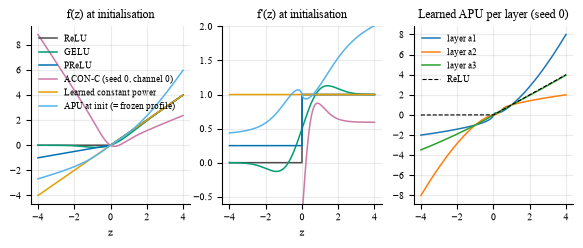

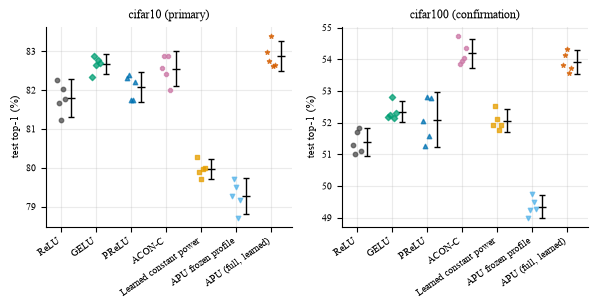

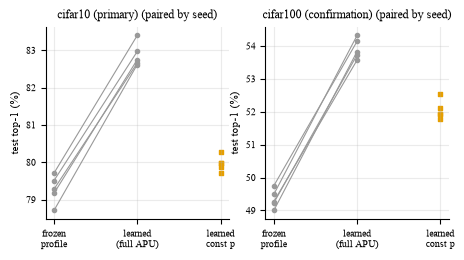

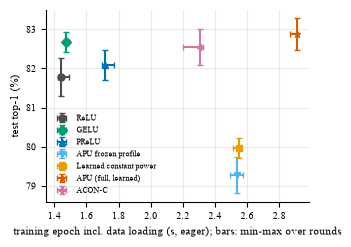

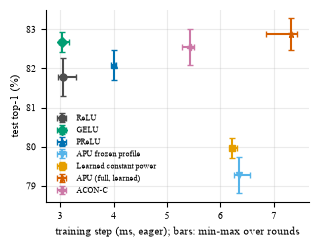

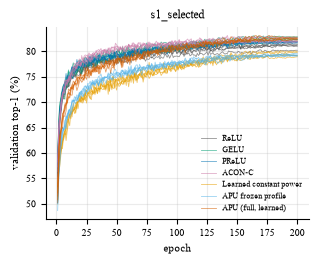

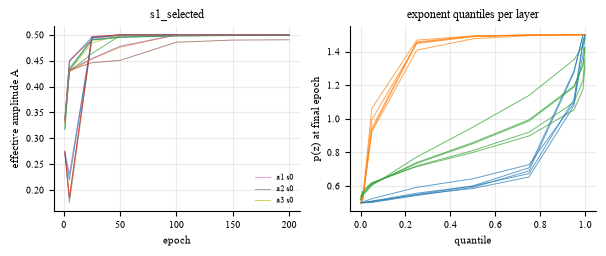

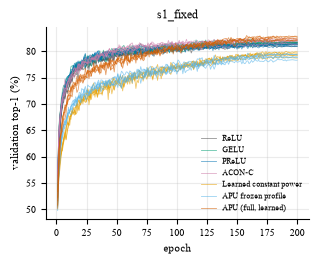

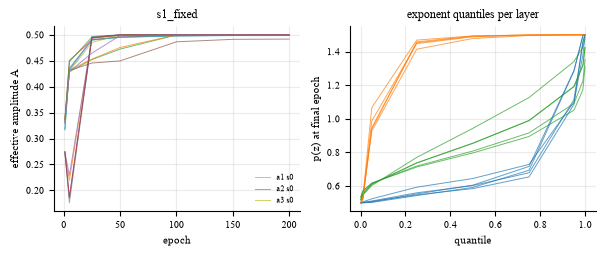

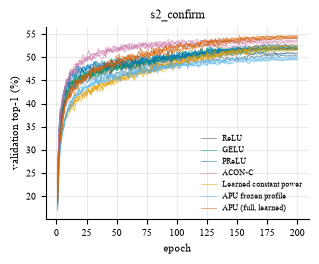

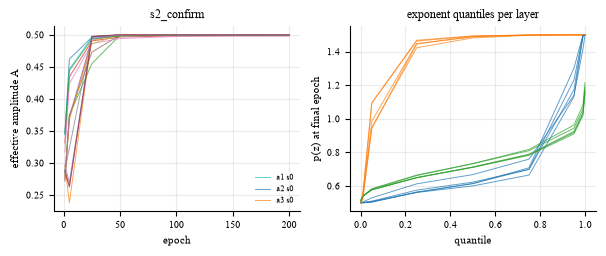

figures written to apu_v2_runs\paper_assets\figures


In [28]:
# ===== 11b. Figures (built only when the measurements exist and the seed counts / joins validate) =====
if stage_on("analysis"):
    learned = None
    s1 = RESULTS.get("s1_selected")
    if s1 is not None:
        g = s1["frame"]; g = g[(g.method == "apu") & (g.status == "completed")].sort_values("seed")
        if len(g):
            d0 = g.digest.iloc[0]; cfg = store.config(d0); rec = store.record(d0)
            mdl = TR.build_model_for(cfg, torch.device("cpu"))
            mdl.load_state_dict(torch.load(store.root / rec["evaluation_checkpoint"]["path"], map_location="cpu", weights_only=False)["model"])
            zz = torch.linspace(-4, 4, 801); learned = {}
            with torch.no_grad():
                for n, m in A.act_modules(mdl): learned[f"layer {n}"] = (zz.numpy(), m.float()(zz).numpy())
    figs = [RP.fig_activation_overview(FIG, learned)]
    complete = {t: (RESULTS[t] is not None and not RESULTS[t]["issues"]) for t in RESULTS}
    main_arms = [(f"{PRO['stage1_dataset']} (primary)", "s1_selected"), (f"{PRO['stage2_dataset']} (confirmation)", "s2_confirm")]
    ok_arms = [(t, RESULTS[k]["frame"]) for t, k in main_arms if k in RESULTS and complete[k]]
    skipped = [k for _, k in main_arms if k in RESULTS and not complete[k]]
    if skipped: print("figures 2-3 skip arms with missing or failed runs (see issues above):", skipped)
    if ok_arms:
        figs.append(RP.fig_accuracy(FIG, ok_arms))
        flags = [RP.paired_ok(f, "apu", "apu_frozen", DATA_PLAN_VERIFIED) for _, f in ok_arms]
        figs.append(RP.fig_learned_vs_frozen(FIG, ok_arms, flags))
    if s1 is not None and complete.get("s1_selected") and "BT" in globals() and len(BT) and "agg" in globals():
        mode = "compiled" if TRAIN_COMPILE else "eager"
        cost = agg[(agg.arch == "simplecnn") & (agg["mode"] == mode)]
        q = BT[(BT.status == "completed") & (BT.arch == "simplecnn") & (BT["mode"] == mode)].groupby("method")
        for col, lab in [("epoch_end_to_end_s", f"training epoch incl. data loading (s, {mode})"), ("train_step_ms", f"training step (ms, {mode})")]:
            if col in cost:
                cc = cost[["method", col]].copy()
                cc[col + "_q25"] = q[col].min().reindex(cc.method).values; cc[col + "_q75"] = q[col].max().reindex(cc.method).values
                figs.append(RP.fig_accuracy_vs_cost(FIG, s1["summary"], cc, col, lab + "; bars: min-max over rounds"))
    for k, res in RESULTS.items():
        figs.append(RP.fig_val_curves(FIG, res["frame"], k)); figs.append(RP.fig_exponents(FIG, res["frame"], k))
    plt.show()
    print("figures written to", FIG)


## 12. Conditional extensions

In [29]:
# ===== 12. Conditional extensions: depth study and Pade baseline (only if decision A holds, or when forced) =====
if stage_on("extensions"):
    dec = C.read_json(TAB / "decision.json") if (TAB / "decision.json").exists() else None
    trig = bool(dec and dec.get("extensions_triggered"))
    if not (trig or FORCE_EXTENSIONS):
        print("Extensions not triggered (decision A not met). This is reported; nothing is run.",
              "\nIf full adaptation did not beat its frozen counterpart, see fixed_profile_investigation_*.csv for whether the fixed function is the useful part.")
    else:
        label = "predeclared conditional extension" if trig else "exploratory (forced by the author; decision A not met)"
        X = PROTOCOL["extensions"]; ext_lock_path = store.root / "protocol" / "lock_extensions.json"
        pade_search = PR.search_jobs(PROTOCOL, CTX, methods=["pade"], tag="ext_pade_search")
        print(TR.run_many(store, pade_search, device, DATA_DIR, SPLIT_DIR, strict=STRICT))
        pade_sel, pade_tab = PR.select(store, PROTOCOL, pade_search, methods=["pade"])
        pd.DataFrame(pade_tab).to_csv(TAB / "ext_pade_selection.csv", index=False)
        sel = dict(LOCK["selection"], pade=pade_sel["pade"])
        jobs = PR.selected_jobs(PROTOCOL, CTX, sel, "stage1", "ext_pade", methods=["pade"])
        for depth in X["depth_study"]["depths"]:
            jobs += PR.selected_jobs(PROTOCOL, CTX, sel, "stage1", f"ext_depth{depth}", methods=X["depth_study"]["methods"], depth=depth)
        EXT_LOCK = PR.write_lock(ext_lock_path, PROTOCOL, sel, jobs, extra=dict(label=label, triggered_by=dec.get("applied") if dec else None))
        print(TR.run_many(store, sorted(jobs, key=lambda j: j[0]["seed"]), device, DATA_DIR, SPLIT_DIR, strict=STRICT))
        if test_all(EXT_LOCK):
            DF = RP.runs_frame(store); s1 = DF[DF.tags.apply(lambda t: "s1_selected" in t)]
            rows = []
            for tag in ["ext_pade"] + [f"ext_depth{d}" for d in X["depth_study"]["depths"]]:
                f = DF[DF.tags.apply(lambda t: tag in t)]
                ms = sorted(set(f.method))
                summ = RP.summary(f, "test_top1", ms); summ.insert(0, "arm", tag); summ.insert(1, "evidence", label); rows.append(summ)
                if {"apu", "apu_frozen"} <= set(ms):
                    c = RP.compare(RP.by_seed(f, "apu", "test_top1"), RP.by_seed(f, "apu_frozen", "test_top1"), RP.paired_ok(f, "apu", "apu_frozen", DATA_PLAN_VERIFIED))
                    print(f"{tag}: apu - apu_frozen = {c['diff']:.3f} pp, 95% CI [{c['lo']:.3f}, {c['hi']:.3f}] ({c['test']})")
            ext = pd.concat(rows); ext.to_csv(TAB / "extensions_accuracy.csv", index=False); display(ext.round(3))
            p = DF[DF.tags.apply(lambda t: "ext_pade" in t)]
            both = pd.concat([s1[s1.method == "apu"], p])
            c = RP.compare(RP.by_seed(both, "apu", "test_top1"), RP.by_seed(both, "pade", "test_top1"), RP.paired_ok(both, "apu", "pade", DATA_PLAN_VERIFIED))
            print(f"apu (stage 1 selected) - pade: {c['diff']:.3f} pp, 95% CI [{c['lo']:.3f}, {c['hi']:.3f}] ({c['test']}) [{label}]")


Extensions not triggered (decision A not met). This is reported; nothing is run. 
If full adaptation did not beat its frozen counterpart, see fixed_profile_investigation_*.csv for whether the fixed function is the useful part.


## 13. Claims and checklist

In [30]:
# ===== 13. Claims file, completion checklist and paper-asset zip =====
if stage_on("report"):
    DF = RP.runs_frame(store); PA = store.root / "paper_assets"
    dec = C.read_json(TAB / "decision.json") if (TAB / "decision.json").exists() else None
    lock = PR.load_lock(store.root / "protocol" / "lock.json")
    def arm_line(tag):
        res = RESULTS.get(tag)
        if res is None: return "not available yet"
        s = res["summary"].set_index("method"); c = res["comparisons"].set_index("role")
        txt = [f"{RP.METHOD_LABEL.get(m, m)} {s.loc[m, 'mean']:.2f} +/- {s.loc[m, 'sd']:.2f} (n = {s.loc[m, 'denominator']})" for m in s.index if np.isfinite(s.loc[m, "mean"])]
        out = "; ".join(txt)
        for role, r in c.iterrows():
            out += f"\n  - {role}: {r['comparison']} = {r['diff']:+.2f} points, 95% CI [{r['lo']:.2f}, {r['hi']:.2f}], {r['test']}, p = {r['p']:.3g}" + \
                   (f", Holm p = {r['p_holm']:.3g}" if role != "primary" and np.isfinite(r["p_holm"]) else "")
        return out
    hist = HIST_AUDIT or (C.read_json(store.root / "audit" / "audit_summary.json") if (store.root / "audit" / "audit_summary.json").exists() else {})
    md = [f"# Claims and evidence (generated {C.now()} by {RP.script_id()})", "",
          "## 1. Historical exploratory evidence (APU_Final2, already inspected on the test set; not used for selection)",
          f"- APU had the highest mean in {hist.get('wins', 'unavailable')} of {hist.get('settings', 'unavailable')} historical settings.",
          f"- Count reconciliation and corrections: see audit/count_reconciliation.csv and audit/corrections.csv ({hist.get('n_corrections', 'unavailable')} corrections).",
          f"- Generative results: {((hist.get('secondary') or {}).get('gan') or {}).get('metric', 'unavailable')}; generated samples per score: "
          f"{((hist.get('secondary') or {}).get('gan') or {}).get('generated_samples_per_score', 'unavailable')}.",
          f"- Corruption results: {((hist.get('secondary') or {}).get('corruption') or {}).get('label', 'unavailable')}.", "",
          "## 2. New evidence (protocol frozen before search; selection on validation only; test evaluated once after the lock)",
          f"- Protocol {PROTOCOL['protocol_digest'][:16]}, lock {lock['lock_digest'][:16] if lock else 'not written'}.",
          f"- Stage 1, primary (equal-search arm): {arm_line('s1_selected')}",
          f"- Stage 2, predeclared confirmation: {arm_line('s2_confirm')}",
          f"- Stage 1, fixed historical recipe (exploratory, answers a different question): {arm_line('s1_fixed')}", "",
          "## 3. Interpretation under the predeclared decision rules"]
    if dec:
        md += [f"- [{k}] {PROTOCOL['decision_rules'][k]}" for k in dec["applied"]]
        md.append(f"- Measured APU training-epoch overhead vs ReLU: {dec.get('cost_overhead_pct')} % (percent change in cost, not accuracy points).")
    else:
        md.append("- not available yet (analysis not run)")
    ext_done = (TAB / "extensions_accuracy.csv").exists()
    md += ["", "## 4. Proposed or not-yet-run work (no results claimed)",
           f"- Depth study and Pade baseline: {'completed, see extensions_accuracy.csv' if ext_done else 'not run (conditional on decision A)'}.",
           "- Official CIFAR-10-C / CIFAR-100-C, ImageNet-scale runs and generative experiments are not part of this study.",
           "- ACON-C and Pade are re-implementations; check them against the primary sources before submission."]
    C.atomic_write_text(PA / "CLAIMS.md", "\n".join(md)); display(Markdown("\n".join(md)))

    # completion checklist (plan section 7), evaluated from files
    fin = [d for d in (lock["final_fit_digests"] if lock else [])]
    recs = {d: store.record(d) for d in fin}
    ck1 = bool(fin) and all(store.config_path(d).exists() and r and (r["status"] == "failed" or (C.validate_completed(store, d, r) is None and store.test_path(d).exists())) for d, r in recs.items())
    tests = [C.read_json(store.test_path(d)) for d in fin if store.test_path(d).exists()]
    search_tested = [c for c, _ in SEARCH_JOBS if store.test_path(C.digest_of(c)).exists()]
    ck2 = bool(lock) and bool(tests) and all(t["evaluated"] >= lock["created"] for t in tests) and not search_tested and \
          all(r.get("test_partition_loaded") is False for r in recs.values() if r and r["status"] == "completed")
    chk_res = {r["name"]: r["passed"] for r in REP["results"]}
    f1 = DF[DF.tags.apply(lambda t: "s1_selected" in t)] if len(DF) else DF
    same_init = len(f1) and all((f1[(f1.method == "apu") & (f1.seed == s)].backbone_init.values == f1[(f1.method == "apu_frozen") & (f1.seed == s)].backbone_init.values).all()
                                for s in PROTOCOL["final_seeds"] if len(f1[(f1.method == "apu") & (f1.seed == s)]))
    ck3 = bool(same_init) and all(v for k, v in chk_res.items() if "frozen control" in k)
    sel_tab = pd.read_csv(TAB / "selection_search_table.csv") if (TAB / "selection_search_table.csv").exists() else pd.DataFrame()
    ck4 = len(sel_tab) == len(PROTOCOL["methods"]) * len(PROTOCOL["search"]["grid"]) and (TAB / "all_runs_per_seed_raw.csv").exists()
    s2 = RESULTS.get("s2_confirm"); ck5 = bool(s2 is not None and dec and dec.get("stage2") is not None and not [i for i in s2["issues"] if "missing" in i])
    bt = bench_table() if BENCH_DIR.exists() else pd.DataFrame()
    ck6 = len(bt) > 0 and set(PROTOCOL["methods"]) <= set(bt[(bt.status == "completed") & (bt.arch == "simplecnn")].method)
    ck7 = all((TAB / f).exists() for f in ["all_runs_per_seed_raw.csv", "decision.json"]) and any(FIG.glob("*.pdf"))
    ck8 = (PA / "CLAIMS.md").exists()
    items = [("Every result links to an immutable configuration, valid checkpoint and raw metric record.", ck1),
             ("The test set played no role in new configuration or checkpoint selection.", ck2),
             ("The frozen control uses the same initial input-dependent function and shared backbone initialisation.", ck3),
             ("Baseline tuning budgets and failures are fully reported.", ck4),
             ("At least one predeclared confirmation setting is completed and interpreted honestly.", ck5),
             ("The successful architecture has measured runtime and memory, with matched execution conditions.", ck6),
             ("All numerical summaries and figures regenerate from saved structured records.", ck7),
             ("The manuscript separates historical exploratory evidence, new confirmation and proposed work (CLAIMS.md).", ck8)]
    cl = "\n".join(f"- [{'x' if v else ' '}] {t}" for t, v in items)
    C.atomic_write_text(PA / "CHECKLIST.md", f"# Completion checklist ({C.now()})\n\n{cl}\n"); display(Markdown(cl))
    for f in ["protocol/protocol.json", "protocol/lock.json", "protocol/lock_extensions.json", "engineering/checks.json", "audit/audit_summary.json",
              "audit/corrections.csv", "audit/count_reconciliation.csv"]:
        if (store.root / f).exists(): shutil.copy2(store.root / f, PA / Path(f).name)
    z = shutil.make_archive(str(store.root / "paper_assets"), "zip", PA)
    print("paper assets:", z)


# Claims and evidence (generated 2026-11-02T04:05:09 by apu_lib/report.py sha256:913d11fc625d)

## 1. Historical exploratory evidence (APU_Final2, already inspected on the test set; not used for selection)
- APU had the highest mean in 1 of 13 historical settings.
- Count reconciliation and corrections: see audit/count_reconciliation.csv and audit/corrections.csv (1 corrections).
- Generative results: Frechet distance in the feature space of a small classifier trained on the real data (NOT Inception-based FID); generated samples per score: 4864.
- Corruption results: 8 re-implemented corruption types; not the official CIFAR-10-C / CIFAR-100-C benchmark.

## 2. New evidence (protocol frozen before search; selection on validation only; test evaluated once after the lock)
- Protocol a3f970bfd0ecc8a9, lock d14302b877d38c45.
- Stage 1, primary (equal-search arm): ReLU 81.79 +/- 0.39 (n = 5/5); GELU 82.67 +/- 0.20 (n = 5/5); PReLU 82.08 +/- 0.31 (n = 5/5); APU frozen profile 79.28 +/- 0.38 (n = 5/5); Learned constant power 79.97 +/- 0.20 (n = 5/5); APU (full, learned) 82.88 +/- 0.32 (n = 5/5); ACON-C 82.55 +/- 0.36 (n = 5/5)
  - primary: apu - apu_frozen = +3.60 points, 95% CI [3.35, 3.86], paired t, p = 2.63e-06
  - secondary: strongest validated standard: apu - gelu = +0.21 points, 95% CI [-0.40, 0.81], paired t, p = 0.398, Holm p = 0.398
  - secondary: strongest validated adaptive: apu - acon_c = +0.33 points, 95% CI [-0.08, 0.74], paired t, p = 0.0882, Holm p = 0.176
  - secondary: learned constant power: apu - apu_const = +2.91 points, 95% CI [2.39, 3.44], paired t, p = 0.000104, Holm p = 0.000312
- Stage 2, predeclared confirmation: ReLU 51.38 +/- 0.36 (n = 5/5); GELU 52.34 +/- 0.27 (n = 5/5); PReLU 52.10 +/- 0.69 (n = 5/5); APU frozen profile 49.35 +/- 0.28 (n = 5/5); Learned constant power 52.05 +/- 0.29 (n = 5/5); APU (full, learned) 53.92 +/- 0.31 (n = 5/5); ACON-C 54.18 +/- 0.37 (n = 5/5)
  - primary: apu - apu_frozen = +4.57 points, 95% CI [4.26, 4.88], paired t, p = 2.06e-06
  - secondary: strongest validated standard: apu - gelu = +1.58 points, 95% CI [1.01, 2.15], paired t, p = 0.00154, Holm p = 0.00347
  - secondary: strongest validated adaptive: apu - acon_c = -0.26 points, 95% CI [-1.04, 0.52], paired t, p = 0.401, Holm p = 0.401
  - secondary: learned constant power: apu - apu_const = +1.86 points, 95% CI [1.24, 2.49], paired t, p = 0.00116, Holm p = 0.00347
- Stage 1, fixed historical recipe (exploratory, answers a different question): ReLU 81.52 +/- 0.30 (n = 5/5); GELU 81.82 +/- 0.53 (n = 5/5); PReLU 81.71 +/- 0.12 (n = 5/5); APU frozen profile 79.08 +/- 0.26 (n = 5/5); Learned constant power 79.85 +/- 0.16 (n = 5/5); APU (full, learned) 82.94 +/- 0.35 (n = 5/5); ACON-C 81.64 +/- 0.11 (n = 5/5)
  - primary: apu - apu_frozen = +3.86 points, 95% CI [3.16, 4.56], paired t, p = 0.000107
  - secondary: strongest validated standard: apu - gelu = +1.12 points, 95% CI [0.60, 1.65], paired t, p = 0.004, Holm p = 0.004
  - secondary: strongest validated adaptive: apu - acon_c = +1.30 points, 95% CI [0.92, 1.68], paired t, p = 0.00066, Holm p = 0.00132
  - secondary: learned constant power: apu - apu_const = +3.09 points, 95% CI [2.48, 3.70], paired t, p = 0.000148, Holm p = 0.000445

## 3. Interpretation under the predeclared decision rules
- [E] No reproducible advantage over strong controls -> revise the central claim or pursue a carefully supported behavioural analysis.
- Measured APU training-epoch overhead vs ReLU: 101.92982175142214 % (percent change in cost, not accuracy points).

## 4. Proposed or not-yet-run work (no results claimed)
- Depth study and Pade baseline: not run (conditional on decision A).
- Official CIFAR-10-C / CIFAR-100-C, ImageNet-scale runs and generative experiments are not part of this study.
- ACON-C and Pade are re-implementations; check them against the primary sources before submission.

- [x] Every result links to an immutable configuration, valid checkpoint and raw metric record.
- [x] The test set played no role in new configuration or checkpoint selection.
- [x] The frozen control uses the same initial input-dependent function and shared backbone initialisation.
- [x] Baseline tuning budgets and failures are fully reported.
- [x] At least one predeclared confirmation setting is completed and interpreted honestly.
- [x] The successful architecture has measured runtime and memory, with matched execution conditions.
- [x] All numerical summaries and figures regenerate from saved structured records.
- [x] The manuscript separates historical exploratory evidence, new confirmation and proposed work (CLAIMS.md).

paper assets: C:\Users\ziaur\Downloads\APU_Final2\apu_v2_runs\paper_assets.zip


## Reading the results

- **Primary result.** `accuracy_s1_selected.csv` and `comparisons_s1_selected.csv` (row `primary`: full APU minus frozen profile). Stage 2 (`*_s2_confirm.csv`) is the predeclared confirmation. The fixed-recipe arm (`*_s1_fixed.csv`) is exploratory and answers a different question.
- **Historical numbers.** They stay exploratory. They were inspected on the test set, and additional seeds on that test set do not make them independent.
- **Cost.** Report costs as percent changes in `resources_absolute_and_relative.csv`, separately from accuracy differences in percentage points. FLOP counts are not used because they omit the power evaluation.
- **Failed runs.** They stay in every table, with denominators shown as completed/planned.
- **Reruns.** Re-running the notebook never changes a locked result. A changed setting creates new digests. A changed protocol raises an error instead of overwriting the old one.
